# Phase 20B — Five-Model Conventional Baseline Benchmark
### Full scientific-evidence reviewer notebook

| Item | Value |
|---|---|
| Phase | 20 (subphase **20B**; 20A = frozen shared UNet++ reference) |
| Canonical folder | `notebooks/phasewise/phase_20b_five_model_baselines/` |
| Models | U-Net · Attention U-Net · U-Net++ (20A) · DeepLabV3+ · Transformer/MiT-style U-Net |
| Protocol | `reports/audits/phase20_shared_global_baseline_protocol.json` (frozen) |
| Manifest | `manifests/phase4_v3` |
| Selection rule | `phase20_macro_domain_mean_dice_v1` |
| Cohorts read | TRAIN and VAL only |
| TEST | `CLOSED` — 0 image reads, 0 mask reads, 0 inference, 0 visualizations |
| Canonical VAL inference runs | exactly **1 per model** |
| Scientific terminal state | `PHASE20_FIVE_MODEL_BASELINE_BENCHMARK_COMPLETE__PHASE21_ELIGIBLE_NOT_STARTED` |

**This notebook runs no training and no inference.** Every number, table and figure is
rebuilt from persisted artifacts (training histories, per-image metric tables, the
persisted per-sample prediction NPZ files, and the frozen comparison/freeze JSON).

**Architecture-naming cautions.** `deeplabv3plus` uses a **random-init** backbone — it is
*not* ImageNet-pretrained. `transformer_mit_unet` is `LOCAL_RANDOM_INIT` — a MiT-*style*
U-Net, *not* official pretrained MiT-B1.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path(r"D:/Softfors/jup")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image

from src.analysis import phase20b_reviewer as R
from src.analysis import phase20b_figures as F

# Build every figure + the inventories from persisted artifacts (deterministic, no inference).
CACHE = F.build_all(progress=lambda *a, **k: None)
INV_OUT = F.write_inventories()
FIG = ROOT / "reports/figures/phase20b_five_model_baselines"

def sty(df, uid, fmt=None, **kw):
    """Deterministic Styler (fixed uuid => SHA-stable notebook output)."""
    fmt = {**(fmt or {}), **kw}
    return df.style.format(fmt).set_uuid(uid)

def show_fig(fig_id, width=1150):
    inv = F.figure_inventory()
    row = inv[inv["figure_id"] == fig_id]
    assert len(row) == 1, f"missing figure: {fig_id}"
    p = ROOT / row.iloc[0]["saved_path"]
    display(Markdown(f"*Figure — {row.iloc[0]['title']}*  \n`{row.iloc[0]['saved_path']}`"))
    display(Image(filename=str(p), width=width))

def show_figs(ids, width=1150):
    for i in ids:
        show_fig(i, width=width)

print("figures built      :", len(F.figure_inventory()))
print("embedded in notebook:", int(F.figure_inventory()["embedded_in_notebook"].sum()))
print("figure root         :", R.rel(FIG))

figures built      : 153
embedded in notebook: 114
figure root         : reports/figures/phase20b_five_model_baselines


## 02 · Scientific question  ·  03 · Phase-20A → Phase-20B rationale

**Question.** Given ONE frozen shared four-domain training protocol (identical data,
sampler, loss, optimizer, scheduler, augmentation, threshold and selection rule), how do
**five conventional segmentation architectures** compare across ISIC / BUSI / KVASIR / KUB,
and is the resulting ranking statistically stable?

**Rationale.** Phase 20A established a single frozen shared **UNet++** as the reference
four-domain baseline. Phase 20B answers the obvious follow-up — *is that ranking an
architecture effect or a protocol artifact?* — by adding four more conventional
architectures under the **identical** protocol. Only the model constructor and the
experiment identity vary, so any difference is attributable to the architecture.

Phase 20B is a **subphase of Phase 20**, not a new roadmap phase. The canonical sequence
is `19 → 20A → 20B → 21 → 22 → …`.

In [2]:
head = R.headline_table()
display(sty(head, "p20b_head",
            {"params": "{:,}", "macro_dice": "{:.6f}", "dice_ci_low": "{:.6f}",
             "dice_ci_high": "{:.6f}", "macro_iou": "{:.6f}"}))
freeze = R.load_freeze()
display(Markdown(f"**Scientific terminal state:** `{freeze['terminal_state']}`  \n"
                 f"**Top model (observed):** `{freeze['top_model']}`  ·  "
                 f"**top-two margin:** {freeze['top_two_margin']:.6f}  ·  "
                 f"**top-two significant:** {freeze['top_two_ranking_significant']}"))

,model_key,model,phase,class_name,params,best_epoch,final_epoch,stop_reason,macro_dice,dice_ci_low,dice_ci_high,macro_iou
0,unet,U-Net,20B,UNet,"7,763,041",74,89,EARLY_STOPPING_PATIENCE,0.787832,0.738143,0.837522,0.688096
1,attention_unet,Attention U-Net,20B,AttentionUNet,"7,851,285",64,79,EARLY_STOPPING_PATIENCE,0.789037,0.728752,0.844685,0.692749
2,unetpp,U-Net++,20A,UNetPlusPlus,"9,159,681",55,70,EARLY_STOPPING_PATIENCE,0.792010,0.744572,0.838188,0.691026
3,deeplabv3plus,DeepLabV3+,20B,DeepLabV3Plus,"40,347,041",57,72,EARLY_STOPPING_PATIENCE,0.827652,0.770725,0.876131,0.741205
4,transformer_mit_unet,Transformer/MiT-style U-Net,20B,TransformerMiTUNet,"16,347,777",74,89,EARLY_STOPPING_PATIENCE,0.822383,0.759882,0.875536,0.736599


**Scientific terminal state:** `PHASE20_FIVE_MODEL_BASELINE_BENCHMARK_COMPLETE__PHASE21_ELIGIBLE_NOT_STARTED`  
**Top model (observed):** `deeplabv3plus`  ·  **top-two margin:** 0.005270  ·  **top-two significant:** False

## 04 · Governance / TEST lock  ·  05 · Frozen data population

TEST is content-locked. Only manifest *metadata* is used; no TEST image or mask is ever
opened, decoded, rendered or inferred. Phase 39 remains the only TEST-evaluation phase.

In [3]:
gov = pd.DataFrame([
    ("manifest version", R.load_protocol()["dataset_populations"]["manifest_version"]),
    ("cohorts read", "TRAIN, VAL"),
    ("TEST image reads", 0), ("TEST mask reads", 0),
    ("TEST inference", 0), ("TEST visualization", 0),
    ("VAL population", freeze["val_population"]),
    ("threshold (frozen)", freeze["threshold"]),
    ("input resolution", freeze["input_resolution"]),
    ("input channel policy", freeze["input_channel_policy"]),
    ("selection rule", freeze["selection_rule_id"]),
    ("canonical VAL inference runs / model", 1),
    ("per-model recipe/threshold change", freeze["no_per_model_recipe_or_threshold_change"]),
], columns=["governance item", "value"])
display(sty(gov, "p20b_gov"))

pop = R.population_table()
display(sty(pop, "p20b_pop"))
cov = R.coverage_matrix()
display(sty(cov, "p20b_cov", {d: "{:d}" for d in R.DATASET_ORDER + ["TOTAL"]}))
assert cov[[*R.DATASET_ORDER, "TOTAL"]].to_numpy().min() > 0
assert (cov["TOTAL"] == 808).all()
display(Markdown(f"Every model was evaluated on the **same 808 VAL cases** "
                 f"(ISIC 357 · BUSI 84 · KVASIR 87 · KUB 280)."))

,governance item,value
0,manifest version,phase4_v3
1,cohorts read,"TRAIN, VAL"
2,TEST image reads,0
3,TEST mask reads,0
4,TEST inference,0
5,TEST visualization,0
6,VAL population,808
7,threshold (frozen),0.500000
8,input resolution,512
9,input channel policy,RGB_3CH


,dataset,n_val
0,ISIC,357
1,BUSI,84
2,KVASIR,87
3,KUB,280
4,TOTAL,808


,model_key,model,ISIC,BUSI,KVASIR,KUB,TOTAL
0,unet,U-Net,357,84,87,280,808
1,attention_unet,Attention U-Net,357,84,87,280,808
2,unetpp,U-Net++,357,84,87,280,808
3,deeplabv3plus,DeepLabV3+,357,84,87,280,808
4,transformer_mit_unet,Transformer/MiT-style U-Net,357,84,87,280,808


Every model was evaluated on the **same 808 VAL cases** (ISIC 357 · BUSI 84 · KVASIR 87 · KUB 280).

## 06 · Preprocessing / input contract  ·  07 · Fairness contract

The preprocessing and evaluation contracts are the frozen Phase-19 contracts, reused
verbatim. The fairness table below is a field-by-field proof that **only** the model
constructor and the experiment identity differ between the five runs.

In [4]:
proto = R.load_protocol()
ir = proto["input_representation"]
pc = pd.DataFrame([
    ("preprocessing_contract_id", proto["preprocessing_contract_id"]),
    ("preprocessing_contract_sha256", proto["preprocessing_contract_sha256"]),
    ("evaluation_contract_id", proto["evaluation_contract_id"]),
    ("evaluation_contract_sha256", proto["evaluation_contract_sha256"]),
    ("channel_policy", ir["channel_policy"]),
    ("contract_label", ir["contract_label"]),
    ("intensity_normalization", ir["intensity_normalization"]),
    ("input_resolution", proto["input_resolution"]),
    ("model_input_excludes", ", ".join(ir["model_input_excludes"])),
], columns=["preprocessing field", "value"])
display(sty(pc, "p20b_preproc"))

fair = R.fairness_contract_table()
display(sty(fair, "p20b_fair"))
all_same = bool(fair[fair["field"] != "experiment_id"]["identical_across_models"].all())
display(Markdown(f"**All contract fields identical across the five models:** `{all_same}` — "
                 f"only the model constructor and experiment identity vary."))
assert all_same

,preprocessing field,value
0,preprocessing_contract_id,phase19_preprocessing_contract_v1
1,preprocessing_contract_sha256,a1db4b083611bc5a6ec4928427c77fcc49a949481aabfadaa5277735bf53fdf0
2,evaluation_contract_id,phase19_evaluation_contract_v1
3,evaluation_contract_sha256,7f7f18fc17e1f377ef8fefcd9f4c9280cd46443b1b1f500071037525f3d32355
4,channel_policy,RGB_3CH
5,contract_label,PHASE20_BASELINE_OPERATIONAL_INPUT_ONLY
6,intensity_normalization,"divide by 255.0 -> [0, 1]"
7,input_resolution,512
8,model_input_excludes,"task_id, dataset_id, KUB category, patient_id, case_id, foreground_fraction, mask-derived metadata"


,field,U-Net,Attention U-Net,U-Net++,DeepLabV3+,Transformer/MiT-style U-Net,identical_across_models
0,manifest_version,phase4_v3,phase4_v3,phase4_v3,phase4_v3,phase4_v3,True
1,dataset,MULTI_DOMAIN_ISIC_BUSI_KVASIR_KUB,MULTI_DOMAIN_ISIC_BUSI_KVASIR_KUB,MULTI_DOMAIN_ISIC_BUSI_KVASIR_KUB,MULTI_DOMAIN_ISIC_BUSI_KVASIR_KUB,MULTI_DOMAIN_ISIC_BUSI_KVASIR_KUB,True
2,input_channel_policy,RGB_3CH,RGB_3CH,RGB_3CH,RGB_3CH,RGB_3CH,True
3,input_resolution,512,512,512,512,512,True
4,loss,"{""bce_weight"": 0.5, ""dice_epsilon"": 1e-06, ""dice_weight"": 0.5, ""name"": ""bce_dice""}","{""bce_weight"": 0.5, ""dice_epsilon"": 1e-06, ""dice_weight"": 0.5, ""name"": ""bce_dice""}","{""bce_weight"": 0.5, ""dice_epsilon"": 1e-06, ""dice_weight"": 0.5, ""name"": ""bce_dice""}","{""bce_weight"": 0.5, ""dice_epsilon"": 1e-06, ""dice_weight"": 0.5, ""name"": ""bce_dice""}","{""bce_weight"": 0.5, ""dice_epsilon"": 1e-06, ""dice_weight"": 0.5, ""name"": ""bce_dice""}",True
5,optimizer,"{""learning_rate"": 0.0001, ""name"": ""AdamW"", ""weight_decay"": 0.0001}","{""learning_rate"": 0.0001, ""name"": ""AdamW"", ""weight_decay"": 0.0001}","{""learning_rate"": 0.0001, ""name"": ""AdamW"", ""weight_decay"": 0.0001}","{""learning_rate"": 0.0001, ""name"": ""AdamW"", ""weight_decay"": 0.0001}","{""learning_rate"": 0.0001, ""name"": ""AdamW"", ""weight_decay"": 0.0001}",True
6,scheduler,"{""T_max"": 100, ""name"": ""CosineAnnealingLR"", ""step"": ""per_epoch_after_train_and_val""}","{""T_max"": 100, ""name"": ""CosineAnnealingLR"", ""step"": ""per_epoch_after_train_and_val""}","{""T_max"": 100, ""name"": ""CosineAnnealingLR"", ""step"": ""per_epoch_after_train_and_val""}","{""T_max"": 100, ""name"": ""CosineAnnealingLR"", ""step"": ""per_epoch_after_train_and_val""}","{""T_max"": 100, ""name"": ""CosineAnnealingLR"", ""step"": ""per_epoch_after_train_and_val""}",True
7,batch_size,4,4,4,4,4,True
8,max_epochs,100,100,100,100,100,True
9,early_stopping_patience,15,15,15,15,15,True


**All contract fields identical across the five models:** `True` — only the model constructor and experiment identity vary.

## 08 · Five model definitions  ·  09 · Parameter counts  ·  10 · Model provenance / SHAs

,model_key,model,phase,class_name,architecture,source_file,params,in_channels,out_channels,base_channels,provenance_note
0,unet,U-Net,20B,UNet,unet_4_stage_plain_skip_base32,src/models/unet.py,"7,763,041",3,1,32,random-init conventional baseline
1,attention_unet,Attention U-Net,20B,AttentionUNet,attention_unet_4_stage_additive_skip_gates_base32,src/models/attention_unet.py,"7,851,285",3,1,32,random-init conventional baseline
2,unetpp,U-Net++,20A,nan,nan,nan,"9,159,681",3,1,32,Phase-20A shared reference
3,deeplabv3plus,DeepLabV3+,20B,DeepLabV3Plus,deeplabv3plus_resnet50_os16_random_init_no_pretrained_aspp_rates_6_12_18,src/models/deeplabv3plus.py,"40,347,041",3,1,32,random-init backbone; NOT ImageNet-pretrained
4,transformer_mit_unet,Transformer/MiT-style U-Net,20B,TransformerMiTUNet,transformer_mit_style_unet_local_random_init,src/models/transformer_mit_unet.py,"16,347,777",3,1,32,LOCAL_RANDOM_INIT MiT-style; NOT official pretrained MiT-B1


*Figure — Parameters vs macro-domain Dice*  
`reports/figures/phase20b_five_model_baselines/efficiency/params_vs_macro.png`

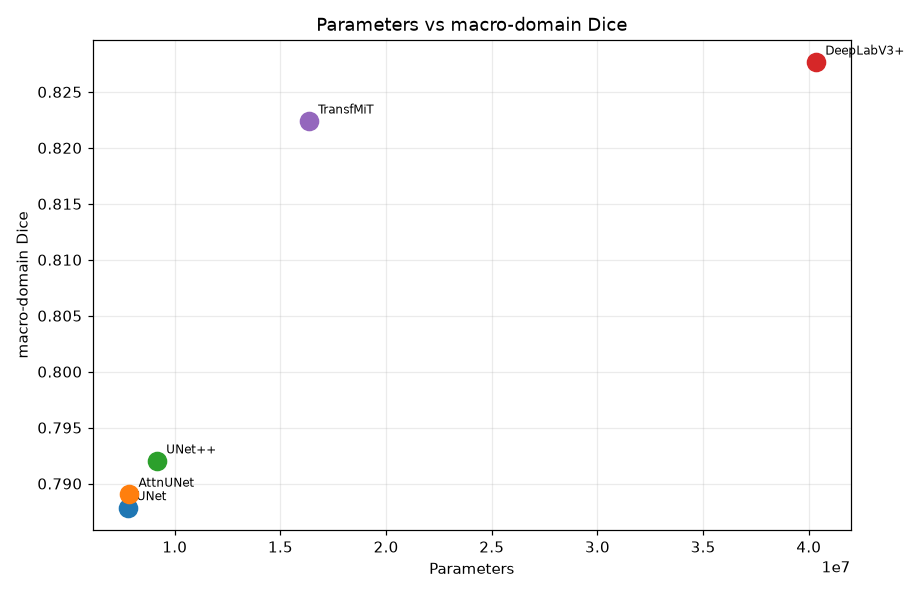

,model_key,model,phase,model_class,model_source_file,model_source_sha256,architecture_binding_sha256,pre_execution_check_sha256,history_sha256,best_checkpoint_sha256,protocol_sha256,protocol_binding,protocol_sha_matches_repo
0,unet,U-Net,20B,UNet,src/models/unet.py,62edc8fb481eb02c46c2c64f6e7219254a57d7ba935a4c840a5a7965b41bdfc2,edc2b1268218a4fe931ed6e1dd3184fb5b1a555cf55904c480a72c5d2759fbae,972b364068d468daa1839b4777f5bede272e9f694d2db13b87c97d6ec641b968,7dcf6088b5ce51fb1ffcca706aa84dc231aae373c09d369e79fbd52f46e7c683,62fde8f4b0de50803e510c609f4cb943b7d72bd1ab7a5b1ff1534b38a76a5634,b74f1f9f429adbce374f0306180943b9f373f872e1e69e115b7d17e81414283c,closure_field,True
1,attention_unet,Attention U-Net,20B,AttentionUNet,src/models/attention_unet.py,834c02170aafc1093de9edb2afad99f76a200ae1eb5ecae16ad57eb7c2e21690,ebdeb453356f9d683bf14773c54bd9d25287fc37b0701054f7a5ac992a4ec15f,1e484bd7b424b7444b5638635d7b89687b23f23e024d8f39080384aaeb060665,f8448b85a4f4b6b37cbc9ed7e5b1a4ae31e6c933f3eb42dd2dbe19d6f6ce66d7,feb0eb0577841f3a9cfc1efb3a46dd4cdd5f749e3f3b08b85d80e472f7dd2b35,b74f1f9f429adbce374f0306180943b9f373f872e1e69e115b7d17e81414283c,closure_field,True
2,unetpp,U-Net++,20A,nan,nan,nan,nan,nan,ed9abeee112a45954e458209ecff9c480a9b68ced7d76edd8dc31eaf9d2333cd,d647ac52bf39704549ce2eea4fee8e17dfcb5ce9ace5e0b24ffb1f7db86a059f,b74f1f9f429adbce374f0306180943b9f373f872e1e69e115b7d17e81414283c,frozen_protocol_code_shas,True
3,deeplabv3plus,DeepLabV3+,20B,DeepLabV3Plus,src/models/deeplabv3plus.py,751a1ead9aca93c7372750924f7483b3de3ad3f5f40edd3a648e9e39bdd77406,1fcf38a67791e81218f94086fd9e8c636428d24ed8c6a3461b355c01d827d561,11d62c7f54fea55b44db6b5d433dc2844dc58d35de8f43cbb2216d5cd1e83260,5ddc59442e1163d6762772c04645230bd9770457e6f76fa5dbd6e2427826631c,0bd9548f141174f05f842d2015dceda6db4587921d241590b63e9ae0099d3ff8,b74f1f9f429adbce374f0306180943b9f373f872e1e69e115b7d17e81414283c,closure_field,True
4,transformer_mit_unet,Transformer/MiT-style U-Net,20B,TransformerMiTUNet,src/models/transformer_mit_unet.py,46c445adf0aaa190b022a7782af3dd0646f29b1978db0cf297cc38eed3d47641,8297ab13a61005848711b5a7021567b3bf6b4d5b2ab50b4a4b9acf749d35e01f,d8dc15e2ff4aec895be4d8d6190f79fd7ca5cc378fe76db6ee29ad041feb52a0,2fcfa684b5d7a242a473ede510199d0b4f622d14f605e96cb5d6a41e93298075,e2c1fca196348d57e4bc8d8ae0f17d82ff0252142e8d94631f7e0ba7d69149e2,b74f1f9f429adbce374f0306180943b9f373f872e1e69e115b7d17e81414283c,closure_field,True


Every model's closure binds the **same** frozen protocol SHA and its own model-source / binding / pre-execution-check / history / checkpoint SHAs.

In [5]:
mdl = R.model_definition_table()
display(sty(mdl, "p20b_mdef", {"params": "{:,}"}))
show_fig("efficiency_params_macro")
prov = R.provenance_table()
display(sty(prov, "p20b_prov"))
assert prov["protocol_sha_matches_repo"].all()
display(Markdown("Every model's closure binds the **same** frozen protocol SHA and its own "
                 "model-source / binding / pre-execution-check / history / checkpoint SHAs."))

## 11 · Training protocol  ·  12 · Training termination

In [6]:
tsum = R.training_summary()
display(sty(tsum, "p20b_tsum",
            {"params": "{:,}", "best_macro_domain_dice": "{:.6f}", "best_val_loss": "{:.6f}",
             "total_elapsed_seconds": "{:.1f}", "mean_epoch_seconds": "{:.1f}"}))
c0 = R.load_closure(R.MODEL_ORDER[0])
tp = pd.DataFrame([
    ("loss", json.dumps(c0["configuration"]["loss"])),
    ("optimizer", json.dumps(c0["configuration"]["optimizer"])),
    ("scheduler", json.dumps(c0["configuration"]["scheduler"])),
    ("batch_size / eval_batch_size", f"{c0['configuration']['training']['batch_size']} / "
                                     f"{c0['configuration']['training']['eval_batch_size']}"),
    ("max_epochs / patience", f"{c0['configuration']['training']['max_epochs']} / "
                              f"{c0['configuration']['training']['early_stopping_patience']}"),
    ("amp / seed / grad_accum", f"{c0['configuration']['training']['amp']} / "
                                f"{c0['configuration']['training']['seed']} / "
                                f"{c0['configuration']['training']['gradient_accumulation_steps']}"),
    ("sampling_policy", c0["configuration"]["training"]["sampling_policy"]),
    ("checkpoint_metric", c0["configuration"]["training"]["checkpoint_metric"]),
    ("augmentation", c0["configuration"]["augmentation_policy"]),
], columns=["protocol field", "value"])
display(sty(tp, "p20b_tp"))
display(Markdown(f"All five models stopped by **EARLY_STOPPING_PATIENCE**; "
                 f"no run hit `MAX_EPOCHS` and no `rc=2` governance abort occurred."))

,model_key,model,phase,architecture,params,best_epoch,final_epoch,total_completed_epochs,stop_reason,early_stopping_patience,resume_count,best_macro_domain_dice,best_val_loss,total_elapsed_seconds,mean_epoch_seconds,n_improvement_events
0,unet,U-Net,20B,unet_4_stage_plain_skip_base32,"7,763,041",74,89,89,EARLY_STOPPING_PATIENCE,15,1,0.787833,0.193412,8134.1,451.3,28
1,attention_unet,Attention U-Net,20B,attention_unet_4_stage_additive_skip_gates_base32,"7,851,285",64,79,79,EARLY_STOPPING_PATIENCE,15,0,0.789039,0.193129,36053.2,456.1,22
2,unetpp,U-Net++,20A,nan,"9,159,681",55,70,70,EARLY_STOPPING_PATIENCE,15,0,0.792007,0.182518,43001.3,614.1,16
3,deeplabv3plus,DeepLabV3+,20B,deeplabv3plus_resnet50_os16_random_init_no_pretrained_aspp_rates_6_12_18,"40,347,041",57,72,72,EARLY_STOPPING_PATIENCE,15,0,0.827653,0.162723,32450.8,449.5,22
4,transformer_mit_unet,Transformer/MiT-style U-Net,20B,transformer_mit_style_unet_local_random_init,"16,347,777",74,89,89,EARLY_STOPPING_PATIENCE,15,0,0.822381,0.160789,42331.8,475.1,34


,protocol field,value
0,loss,"{""name"": ""bce_dice"", ""bce_weight"": 0.5, ""dice_weight"": 0.5, ""dice_epsilon"": 1e-06}"
1,optimizer,"{""name"": ""AdamW"", ""learning_rate"": 0.0001, ""weight_decay"": 0.0001}"
2,scheduler,"{""name"": ""CosineAnnealingLR"", ""T_max"": 100, ""step"": ""per_epoch_after_train_and_val""}"
3,batch_size / eval_batch_size,4 / 8
4,max_epochs / patience,100 / 15
5,amp / seed / grad_accum,True / 42 / 1
6,sampling_policy,phase20_domain_balanced_uniform_v1
7,checkpoint_metric,phase20_macro_domain_mean_dice_v1
8,augmentation,"src.data.transforms.SegmentationTransform(train=True): horizontal mirror p=0.5, rotation +/-5 deg, brightness +/-0.10, contrast +/-0.10; mask NEAREST; VAL disabled"


All five models stopped by **EARLY_STOPPING_PATIENCE**; no run hit `MAX_EPOCHS` and no `rc=2` governance abort occurred.

## 13 · Per-model training histories

For every model: train/val loss, macro-domain Dice, per-domain Dice and IoU, learning-rate
schedule, early-stopping counter, epoch wall-clock duration and best-checkpoint
progression. All curves come from the persisted `history.csv`; **no epoch row is omitted**
and missing data is never plotted as zero.

**unet**

*Figure — U-Net training overview*  
`reports/figures/phase20b_five_model_baselines/training/unet_training_overview.png`

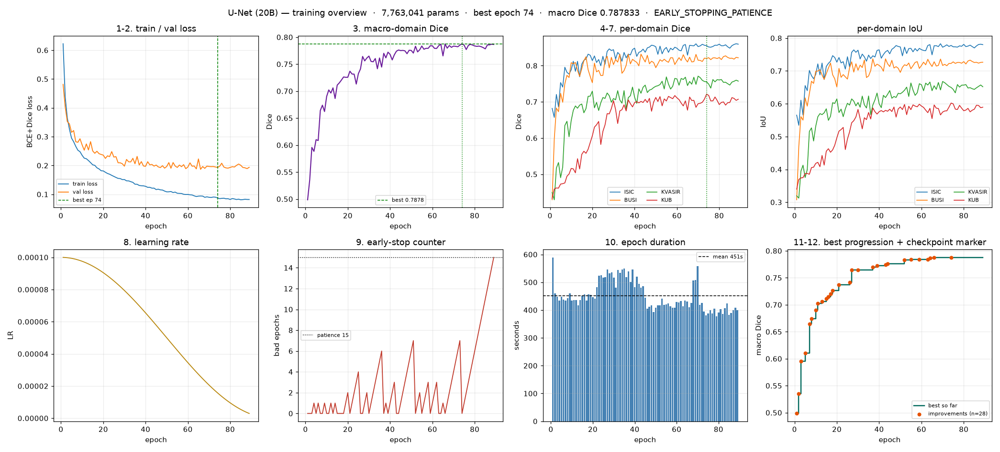

In [7]:
display(Markdown("**unet**"))
show_fig("train_overview_unet", width=1400)

**attention_unet**

*Figure — Attention U-Net training overview*  
`reports/figures/phase20b_five_model_baselines/training/attention_unet_training_overview.png`

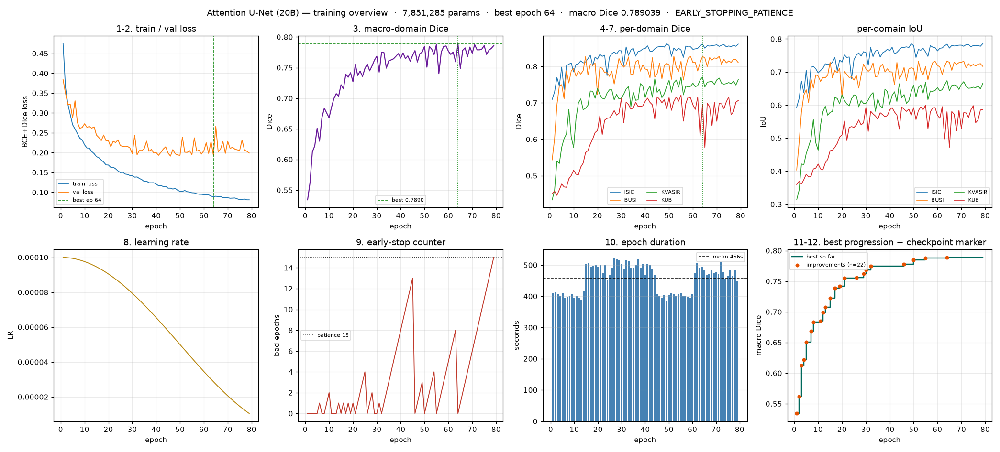

In [8]:
display(Markdown("**attention_unet**"))
show_fig("train_overview_attention_unet", width=1400)

In [9]:
display(Markdown("**unetpp**"))
show_fig("train_overview_unetpp", width=1400)

**unetpp**

*Figure — U-Net++ training overview*  
`reports/figures/phase20b_five_model_baselines/training/unetpp_training_overview.png`

In [10]:
display(Markdown("**deeplabv3plus**"))
show_fig("train_overview_deeplabv3plus", width=1400)

**deeplabv3plus**

*Figure — DeepLabV3+ training overview*  
`reports/figures/phase20b_five_model_baselines/training/deeplabv3plus_training_overview.png`

In [11]:
display(Markdown("**transformer_mit_unet**"))
show_fig("train_overview_transformer_mit_unet", width=1400)

**transformer_mit_unet**

*Figure — Transformer/MiT-style U-Net training overview*  
`reports/figures/phase20b_five_model_baselines/training/transformer_mit_unet_training_overview.png`

### 13b · Cross-model training overlays

*Figure — Cross-model overlay — Macro-domain Dice*  
`reports/figures/phase20b_five_model_baselines/training/overlay_macro_dice.png`

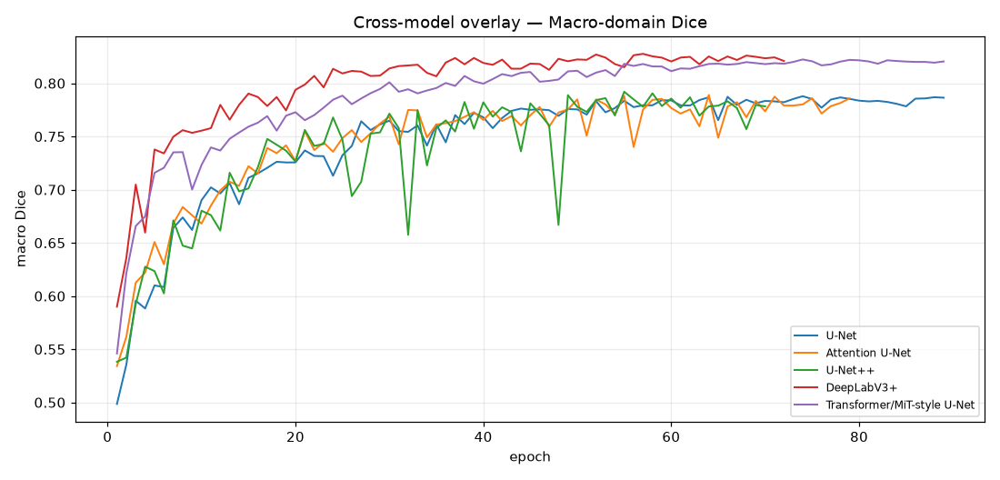

*Figure — Cross-model overlay — Validation loss*  
`reports/figures/phase20b_five_model_baselines/training/overlay_val_loss.png`

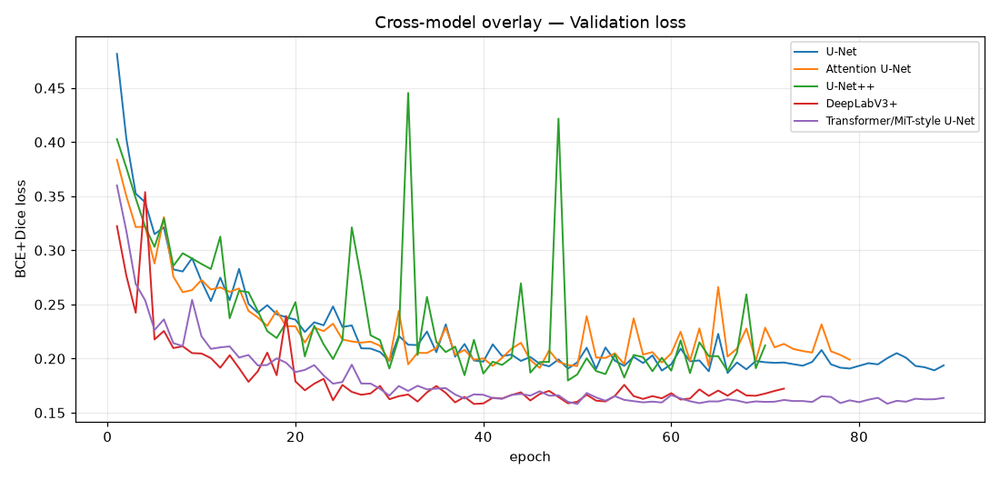

*Figure — Cross-model overlay — KUB Dice*  
`reports/figures/phase20b_five_model_baselines/training/overlay_kub_dice.png`

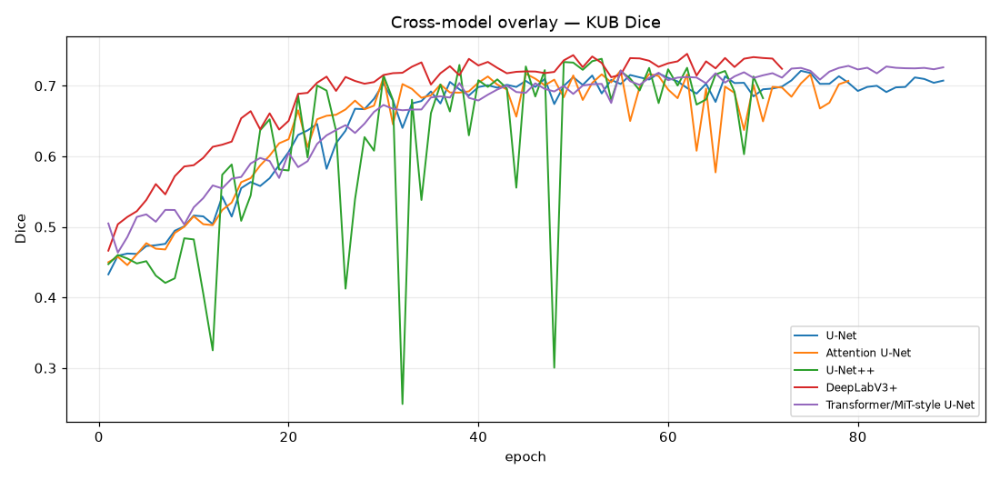

*Figure — Cross-model overlay — Epoch duration*  
`reports/figures/phase20b_five_model_baselines/training/overlay_epoch_seconds.png`

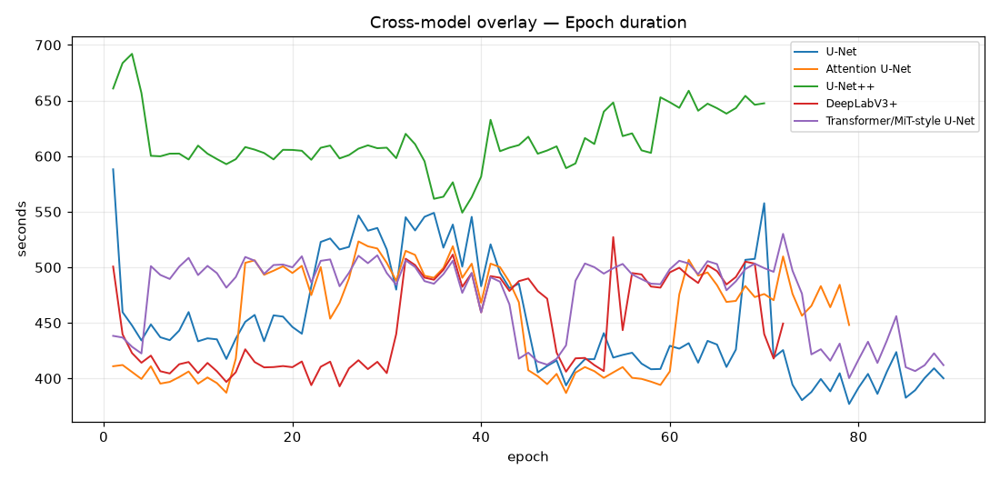

In [12]:
show_figs(["train_macro_domain_dice_overlay", "train_val_loss_overlay",
           "train_val_dice_KUB_overlay", "train_epoch_seconds_overlay"], width=1250)

## 14 · Checkpoint replay status  ·  15 · Canonical VAL evaluation status

The selection rule is replayed **on disk** over the saved history (no inference): the
history-selected epoch must equal the stored best epoch and the `best.pt` epoch.

In [13]:
rep = R.replay_summary()
display(sty(rep, "p20b_rep"))
assert rep["all_checks_passed"].all()
assert (rep["history_selected_epoch"] == rep["stored_best_epoch"]).all()
assert (rep["stored_best_epoch"] == rep["best_pt_epoch"]).all()
ve = R.val_eval_summary()
display(sty(ve, "p20b_ve", {"elapsed_seconds": "{:.1f}"}))
assert (ve["samples_evaluated"] == 808).all()
assert (ve["canonical_val_inference_runs"] == 1).all()
assert ve[["test_image_reads", "test_mask_reads", "test_inference", "test_visualization"]].to_numpy().sum() == 0
display(Markdown("All four Phase-20B replays PASS; every model has exactly one canonical "
                 "808-sample VAL pass and **zero** TEST reads."))

,model_key,model,phase,selection_rule_id,history_selected_epoch,stored_best_epoch,best_pt_epoch,n_epochs_evaluated,n_improvements,all_checks_passed,verdict
0,unet,U-Net,20B,phase20_macro_domain_mean_dice_v1,74,74,74,89,28,True,PHASE20B_CHECKPOINT_SELECTION_REPLAY_PASS
1,attention_unet,Attention U-Net,20B,phase20_macro_domain_mean_dice_v1,64,64,64,79,22,True,PHASE20B_CHECKPOINT_SELECTION_REPLAY_PASS
2,unetpp,U-Net++,20A,phase20_macro_domain_mean_dice_v1,55,55,55,70,16,True,PHASE20_CHECKPOINT_SELECTION_REPLAY_PASS
3,deeplabv3plus,DeepLabV3+,20B,phase20_macro_domain_mean_dice_v1,57,57,57,72,22,True,PHASE20B_CHECKPOINT_SELECTION_REPLAY_PASS
4,transformer_mit_unet,Transformer/MiT-style U-Net,20B,phase20_macro_domain_mean_dice_v1,74,74,74,89,34,True,PHASE20B_CHECKPOINT_SELECTION_REPLAY_PASS


,model_key,model,phase,samples_evaluated,canonical_val_inference_runs,threshold,prob_maps_persisted,elapsed_seconds,test_image_reads,test_mask_reads,test_inference,test_visualization
0,unet,U-Net,20B,808,1,0.500000,808,112.8,0,0,0,0
1,attention_unet,Attention U-Net,20B,808,1,0.500000,808,101.9,0,0,0,0
2,unetpp,U-Net++,20A,808,1,0.500000,808,123.0,0,0,0,0
3,deeplabv3plus,DeepLabV3+,20B,808,1,0.500000,808,92.5,0,0,0,0
4,transformer_mit_unet,Transformer/MiT-style U-Net,20B,808,1,0.500000,808,100.2,0,0,0,0


All four Phase-20B replays PASS; every model has exactly one canonical 808-sample VAL pass and **zero** TEST reads.

## 16 · Primary five-model comparison

Ranked at each model's own best epoch on the identical 808 VAL cases. Error bars are the
deterministic percentile bootstrap 95% CI of the macro-domain mean Dice.

,model_key,model,phase,class_name,params,best_epoch,final_epoch,stop_reason,macro_dice,dice_ci_low,dice_ci_high,macro_iou
0,unet,U-Net,20B,UNet,"7,763,041",74,89,EARLY_STOPPING_PATIENCE,0.787832,0.738143,0.837522,0.688096
1,attention_unet,Attention U-Net,20B,AttentionUNet,"7,851,285",64,79,EARLY_STOPPING_PATIENCE,0.789037,0.728752,0.844685,0.692749
2,unetpp,U-Net++,20A,UNetPlusPlus,"9,159,681",55,70,EARLY_STOPPING_PATIENCE,0.792010,0.744572,0.838188,0.691026
3,deeplabv3plus,DeepLabV3+,20B,DeepLabV3Plus,"40,347,041",57,72,EARLY_STOPPING_PATIENCE,0.827652,0.770725,0.876131,0.741205
4,transformer_mit_unet,Transformer/MiT-style U-Net,20B,TransformerMiTUNet,"16,347,777",74,89,EARLY_STOPPING_PATIENCE,0.822383,0.759882,0.875536,0.736599


*Figure — Macro-domain Dice with 95% CI*  
`reports/figures/phase20b_five_model_baselines/primary_comparison/macro_dice_ci.png`

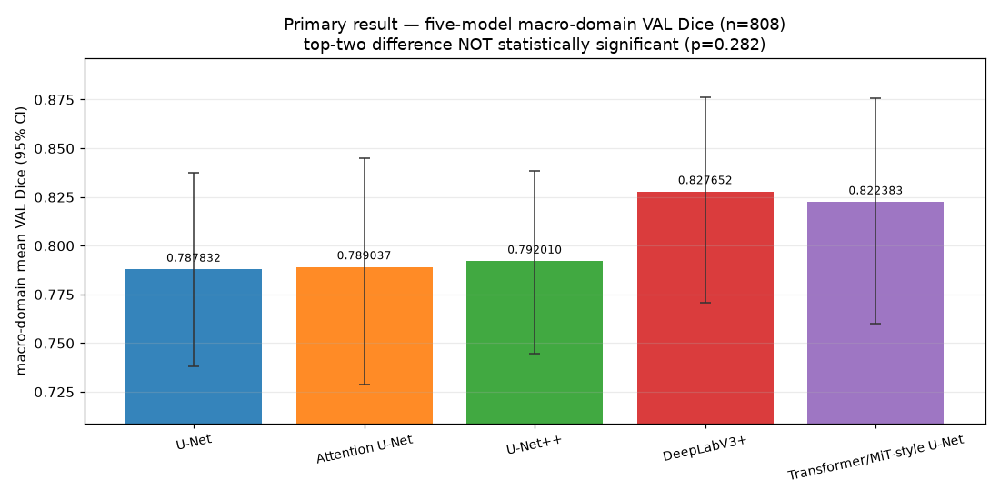

*Figure — Macro-domain IoU bar chart*  
`reports/figures/phase20b_five_model_baselines/primary_comparison/macro_iou_bar.png`

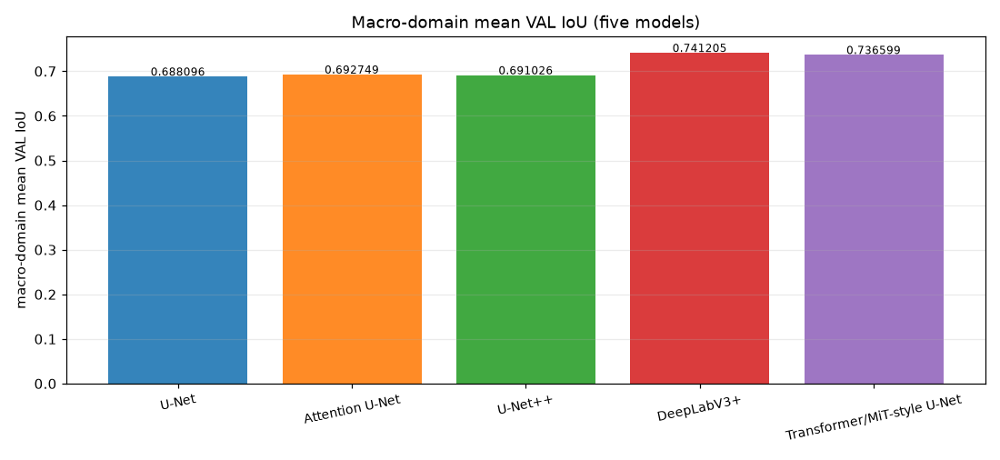

In [14]:
display(sty(head, "p20b_head2",
            {"params": "{:,}", "macro_dice": "{:.6f}", "dice_ci_low": "{:.6f}",
             "dice_ci_high": "{:.6f}", "macro_iou": "{:.6f}"}))
show_figs(["primary_macro_dice_ci", "primary_macro_iou_bar"], width=1200)

## 17 · Domain-specific results  ·  18 · Complete advanced metric comparison

Every advanced metric that is persisted (Dice, IoU, precision, recall, specificity,
balanced accuracy, MCC, HD95, ASSD, Surface Dice, ROC-AUC, PR-AUC, Brier, ECE, MCE) is
shown as a full model × domain matrix **and** as a heatmap. Unavailable entries are shown
as `NA` — never fabricated.

,model_key,model,phase,ISIC,BUSI,KVASIR,KUB,MACRO
0,unet,U-Net,20B,0.85527,0.81977,0.75520,0.72109,0.78783
1,attention_unet,Attention U-Net,20B,0.86169,0.82768,0.77100,0.69578,0.78904
2,unetpp,U-Net++,20A,0.86007,0.81630,0.77100,0.72066,0.79201
3,deeplabv3plus,DeepLabV3+,20B,0.88535,0.86692,0.81969,0.73866,0.82765
4,transformer_mit_unet,Transformer/MiT-style U-Net,20B,0.88709,0.86398,0.81328,0.72518,0.82238


,model_key,model,phase,ISIC,BUSI,KVASIR,KUB,MACRO
0,unet,U-Net,20B,0.77767,0.72284,0.64976,0.60212,0.68810
1,attention_unet,Attention U-Net,20B,0.78412,0.73296,0.67393,0.57999,0.69275
2,unetpp,U-Net++,20A,0.77997,0.71257,0.66967,0.60190,0.69103
3,deeplabv3plus,DeepLabV3+,20B,0.81295,0.78057,0.74290,0.62840,0.74120
4,transformer_mit_unet,Transformer/MiT-style U-Net,20B,0.81669,0.77984,0.72917,0.62070,0.73660


*Figure — Per-domain Dice grouped bars*  
`reports/figures/phase20b_five_model_baselines/primary_comparison/per_domain_dice_grouped.png`

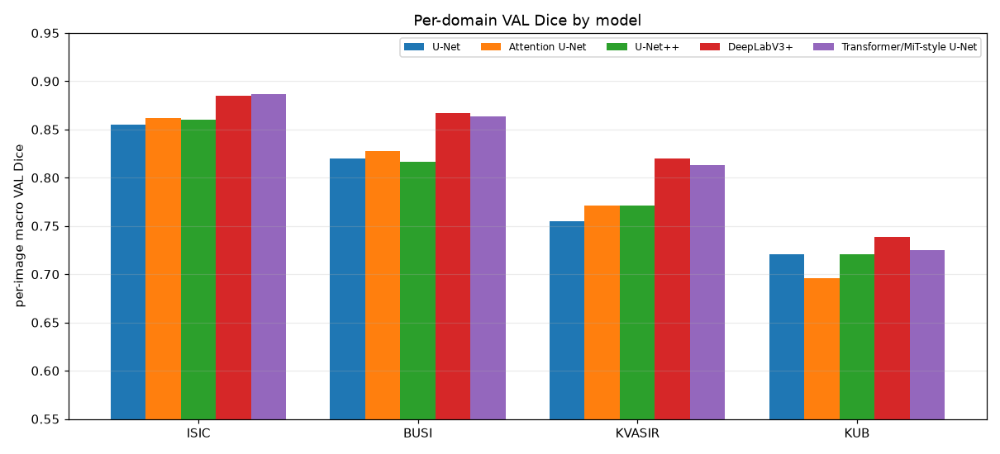

,model_key,model,phase,dice,iou,precision,recall,specificity,balanced_accuracy,mcc,hd95,assd,surface_dice,roc_auc,pr_auc,brier,ece,mce
0,unet,U-Net,20B,0.7878,0.6881,0.8331,0.8071,0.9763,0.8960,0.7853,58.9263,17.8492,0.3541,nan,nan,nan,nan,nan
1,attention_unet,Attention U-Net,20B,0.7890,0.6927,0.8501,0.7974,0.9794,0.8962,0.7936,54.9655,15.6016,0.3676,nan,nan,nan,nan,nan
2,unetpp,U-Net++,20A,0.7920,0.6910,0.8100,0.8403,0.9717,0.9099,0.7887,63.1227,17.5746,0.3460,nan,nan,nan,nan,nan
3,deeplabv3plus,DeepLabV3+,20B,0.8277,0.7412,0.8613,0.8449,0.9823,0.9186,0.8282,39.5498,12.7002,0.3812,nan,nan,nan,nan,nan
4,transformer_mit_unet,Transformer/MiT-style U-Net,20B,0.8224,0.7366,0.8478,0.8487,0.9791,0.9179,0.8209,40.9159,13.4527,0.3855,nan,nan,nan,nan,nan


*Figure — Comprehensive metric heatmap*  
`reports/figures/phase20b_five_model_baselines/metric_heatmaps/comprehensive_metric_heatmap.png`

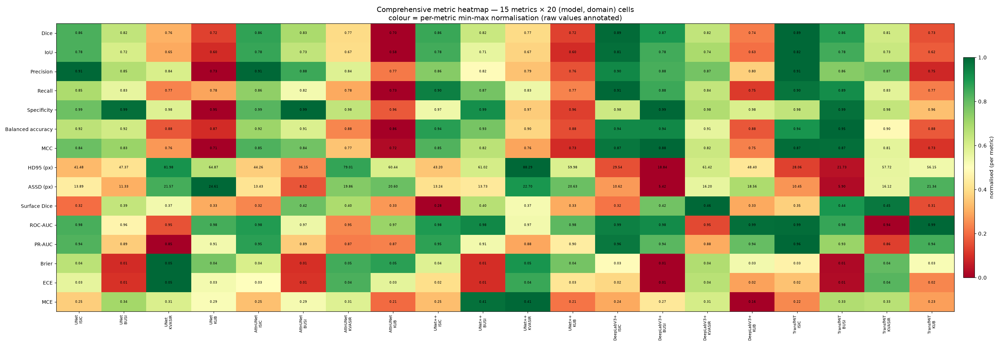

In [15]:
d_dice = R.per_domain_table("dice")
display(sty(d_dice, "p20b_pdd", {d: "{:.5f}" for d in R.DATASET_ORDER + ["MACRO"]}))
d_iou = R.per_domain_table("iou")
display(sty(d_iou, "p20b_pdi", {d: "{:.5f}" for d in R.DATASET_ORDER + ["MACRO"]}))
show_fig("primary_per_domain_dice_grouped")
adv = R.macro_advanced_table()
display(sty(adv, "p20b_adv", {m: "{:.4f}" for m in R.ADVANCED_METRICS}))
show_fig("metric_heat_comprehensive", width=1500)

*Figure — model × domain Dice heatmap*  
`reports/figures/phase20b_five_model_baselines/primary_comparison/model_domain_dice_heatmap.png`

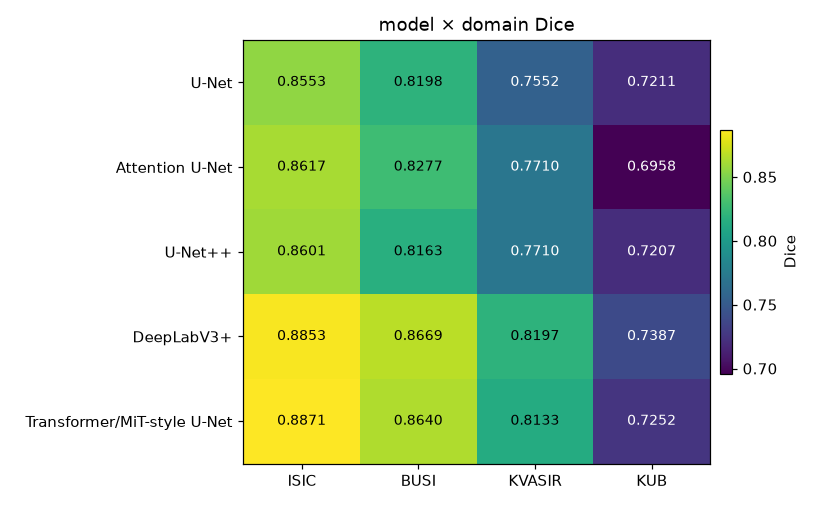

*Figure — model × domain IoU heatmap*  
`reports/figures/phase20b_five_model_baselines/primary_comparison/model_domain_iou_heatmap.png`

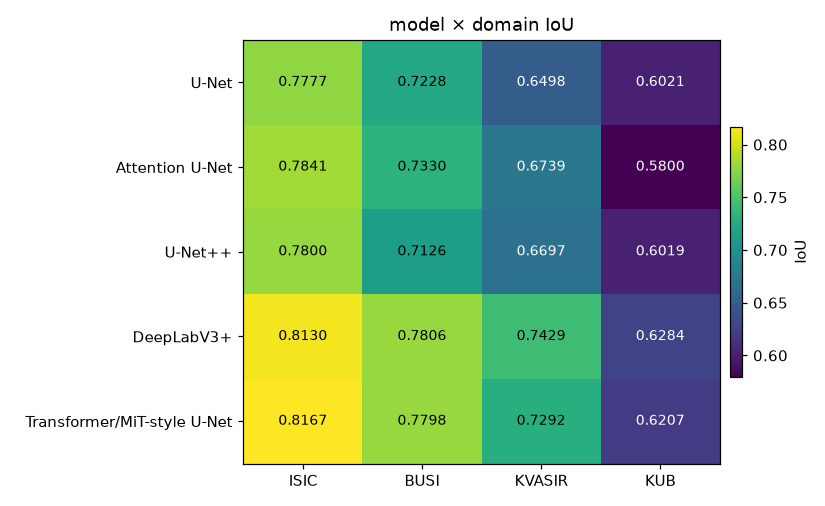

*Figure — model × domain Precision heatmap*  
`reports/figures/phase20b_five_model_baselines/metric_heatmaps/heatmap_precision.png`

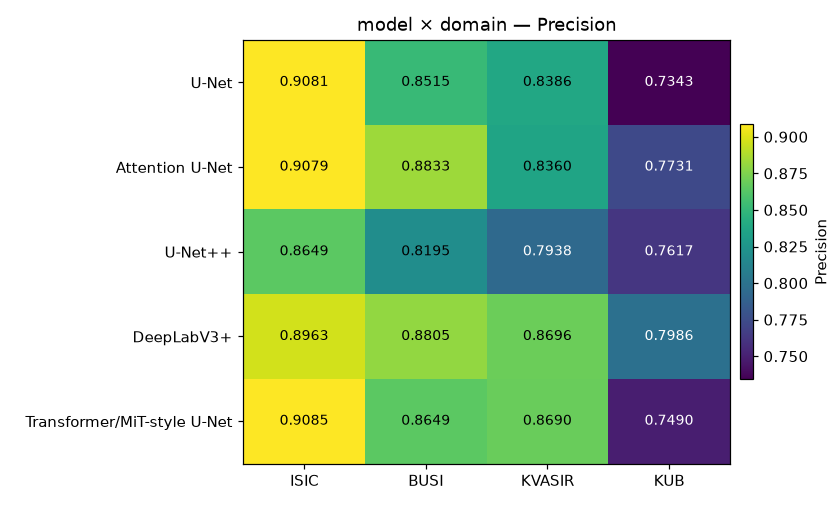

*Figure — model × domain Recall heatmap*  
`reports/figures/phase20b_five_model_baselines/metric_heatmaps/heatmap_recall.png`

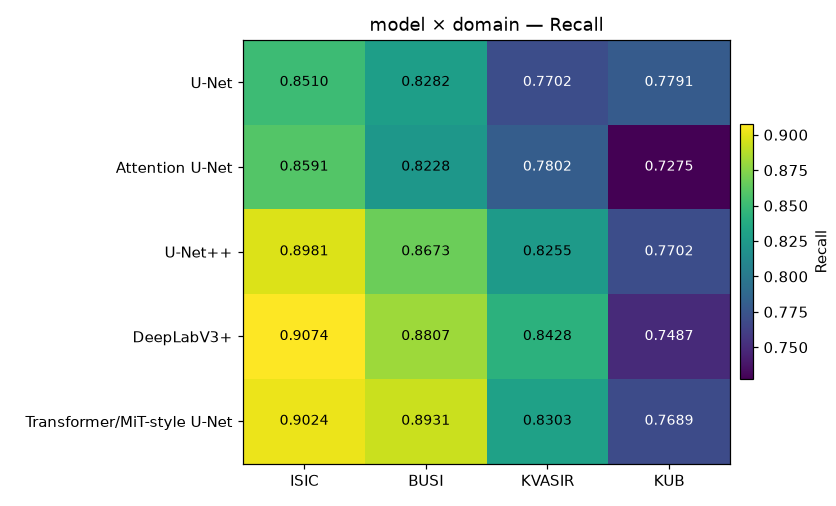

*Figure — model × domain Specificity heatmap*  
`reports/figures/phase20b_five_model_baselines/metric_heatmaps/heatmap_specificity.png`

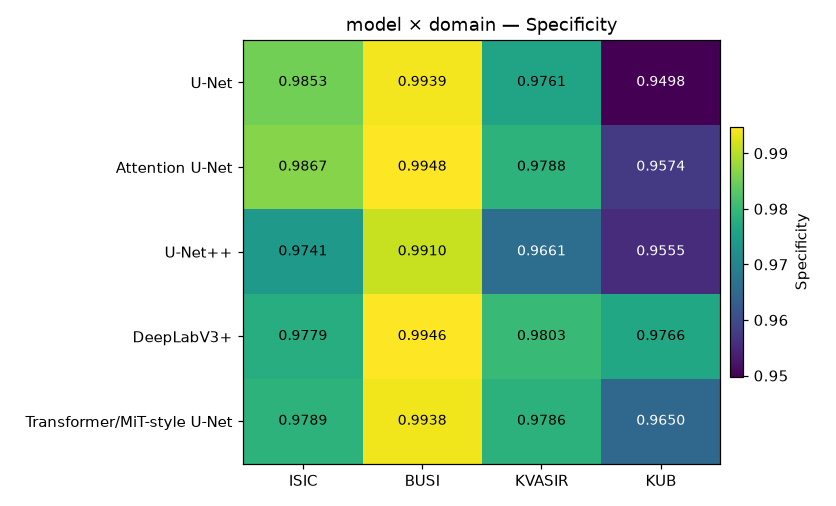

*Figure — model × domain Balanced accuracy heatmap*  
`reports/figures/phase20b_five_model_baselines/metric_heatmaps/heatmap_balanced_accuracy.png`

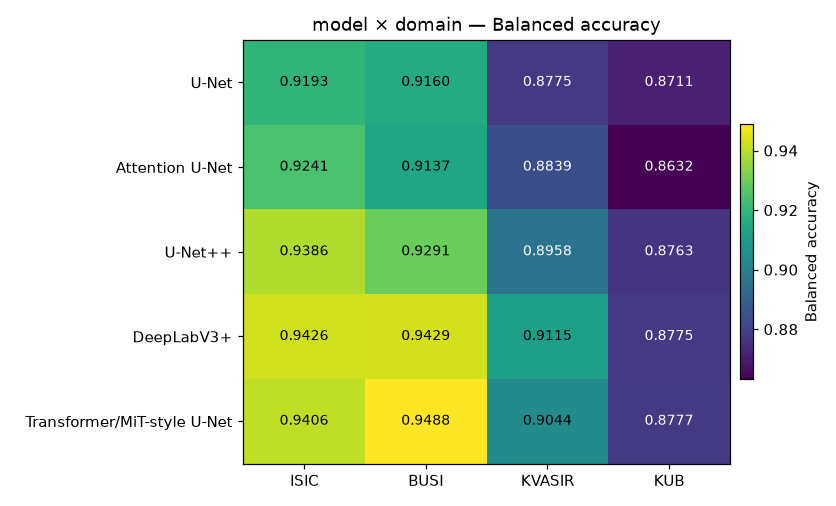

*Figure — model × domain MCC heatmap*  
`reports/figures/phase20b_five_model_baselines/metric_heatmaps/heatmap_mcc.png`

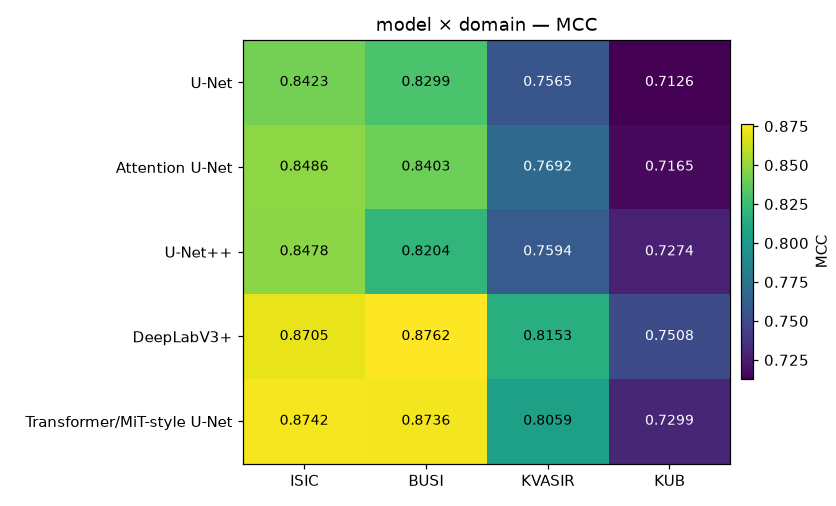

*Figure — model × domain HD95 (px) heatmap*  
`reports/figures/phase20b_five_model_baselines/metric_heatmaps/heatmap_hd95.png`

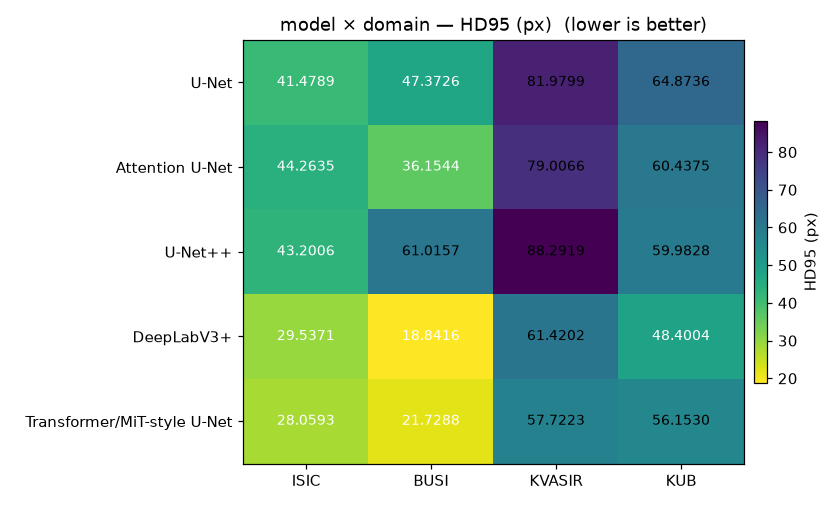

*Figure — model × domain ASSD (px) heatmap*  
`reports/figures/phase20b_five_model_baselines/metric_heatmaps/heatmap_assd.png`

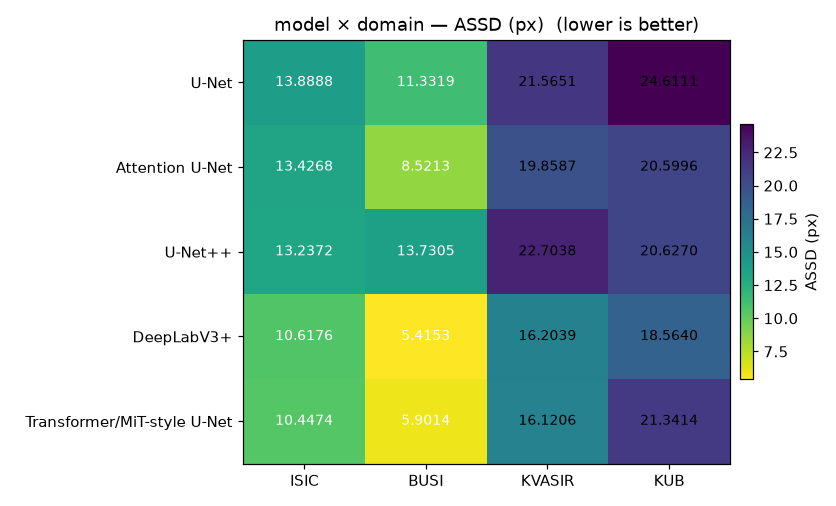

*Figure — model × domain Surface Dice heatmap*  
`reports/figures/phase20b_five_model_baselines/metric_heatmaps/heatmap_surface_dice.png`

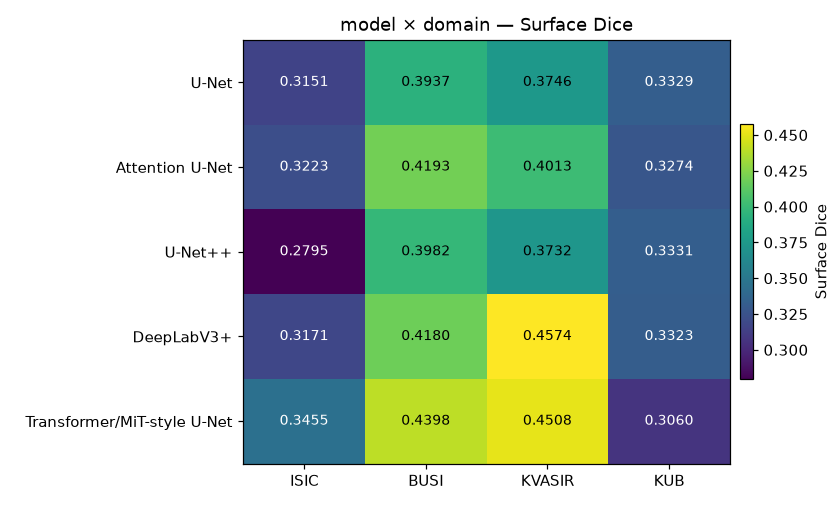

*Figure — model × domain ROC-AUC heatmap*  
`reports/figures/phase20b_five_model_baselines/metric_heatmaps/heatmap_roc_auc.png`

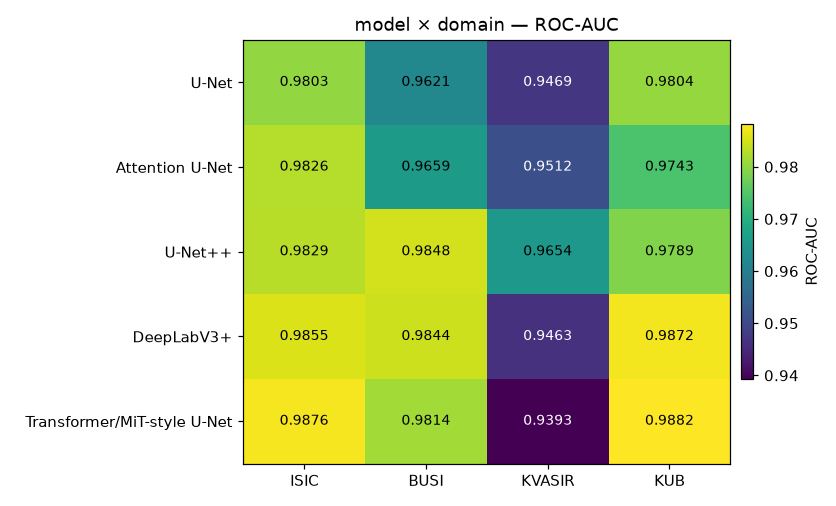

*Figure — model × domain PR-AUC heatmap*  
`reports/figures/phase20b_five_model_baselines/metric_heatmaps/heatmap_pr_auc.png`

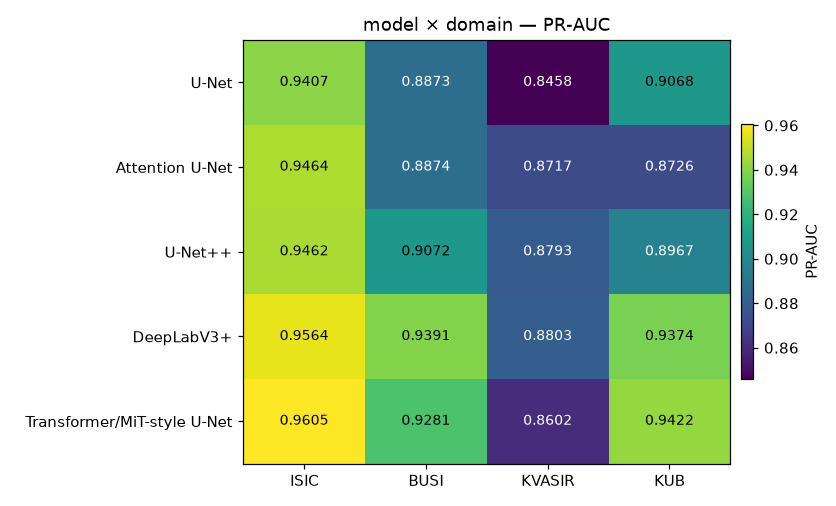

*Figure — model × domain Brier heatmap*  
`reports/figures/phase20b_five_model_baselines/metric_heatmaps/heatmap_brier.png`

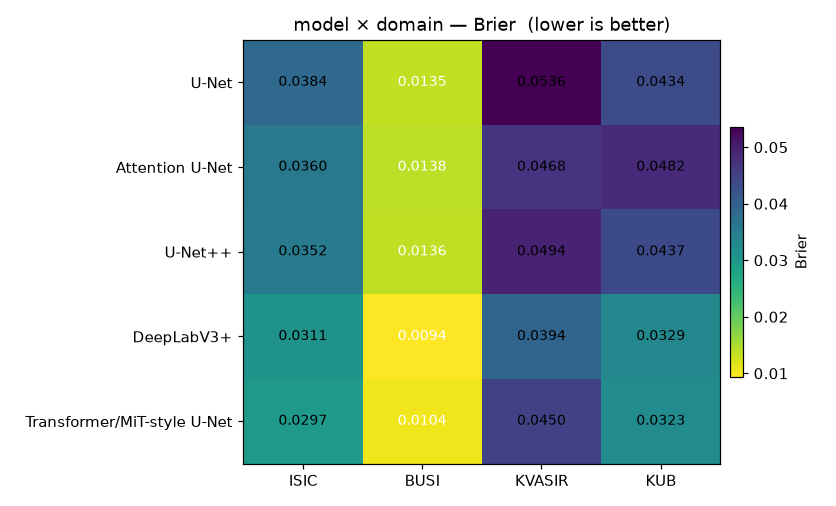

*Figure — model × domain ECE heatmap*  
`reports/figures/phase20b_five_model_baselines/metric_heatmaps/heatmap_ece.png`

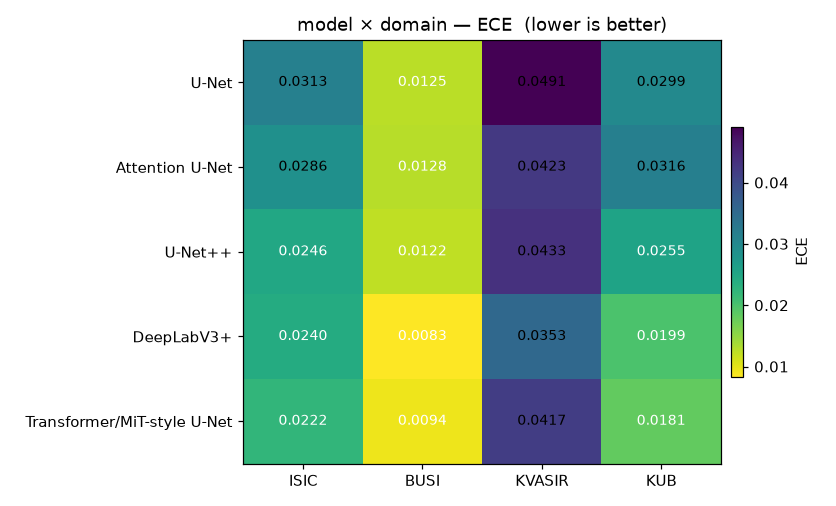

*Figure — model × domain MCE heatmap*  
`reports/figures/phase20b_five_model_baselines/metric_heatmaps/heatmap_mce.png`

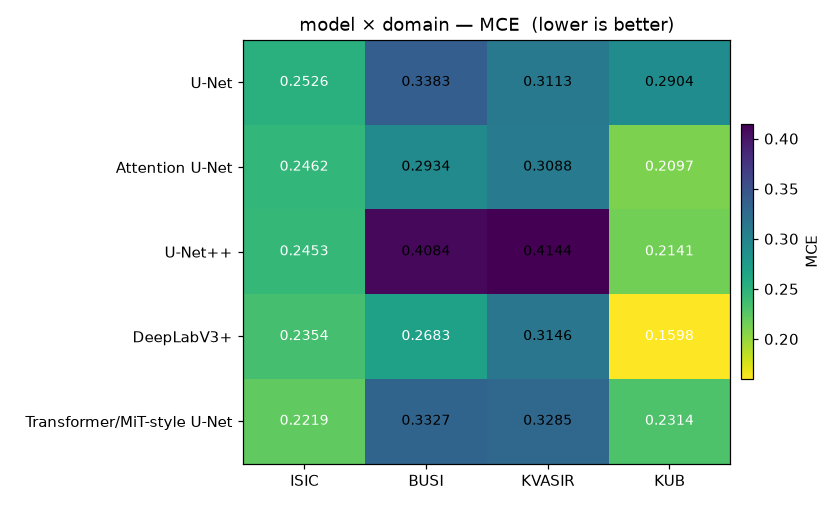

In [16]:
show_figs(["primary_dice_heatmap", "primary_iou_heatmap",
           "metric_heat_precision", "metric_heat_recall",
           "metric_heat_specificity", "metric_heat_balanced_accuracy",
           "metric_heat_mcc", "metric_heat_hd95",
           "metric_heat_assd", "metric_heat_surface_dice",
           "metric_heat_roc_auc", "metric_heat_pr_auc",
           "metric_heat_brier", "metric_heat_ece",
           "metric_heat_mce"], width=950)

## 19 · Bootstrap uncertainty  ·  20 · Pairwise statistical comparison

Every model saw the **same 808 VAL samples**, so models are compared *pairwise* with a
**paired domain-stratified percentile bootstrap**: within each domain the same resampled
indices are used for both models, so per-sample difficulty cancels
(`n_boot=2000`, `seed=42`, `alpha=0.05`). A pair is significant when the 95% CI of the
macro-Dice difference excludes zero.

,model_a,model_b,observed_diff,diff_ci_low,diff_ci_high,p_value_two_sided,significant_at_0.05
0,deeplabv3plus,unetpp,+0.035643,+0.023153,+0.047986,0.000,True
1,transformer_mit_unet,unetpp,+0.030373,+0.016946,+0.044389,0.000,True
2,deeplabv3plus,transformer_mit_unet,+0.005270,-0.004246,+0.013870,0.282,False
3,unet,attention_unet,-0.001204,-0.009941,+0.008359,0.830,False
4,attention_unet,unetpp,-0.002973,-0.014766,+0.008504,0.577,False
5,unet,unetpp,-0.004178,-0.015182,+0.007565,0.488,False
6,attention_unet,transformer_mit_unet,-0.033346,-0.046688,-0.021403,0.000,True
7,unet,transformer_mit_unet,-0.034550,-0.048555,-0.020799,0.000,True
8,attention_unet,deeplabv3plus,-0.038616,-0.051391,-0.026347,0.000,True
9,unet,deeplabv3plus,-0.039820,-0.053127,-0.026640,0.000,True


,U-Net,Attention U-Net,U-Net++,DeepLabV3+,Transformer/MiT-style U-Net
U-Net,+0.0000,-0.0012,-0.0042,-0.0398,-0.0346
Attention U-Net,+0.0012,+0.0000,-0.0030,-0.0386,-0.0333
U-Net++,+0.0042,+0.0030,+0.0000,-0.0356,-0.0304
DeepLabV3+,+0.0398,+0.0386,+0.0356,+0.0000,+0.0053
Transformer/MiT-style U-Net,+0.0346,+0.0333,+0.0304,-0.0053,+0.0000


,U-Net,Attention U-Net,U-Net++,DeepLabV3+,Transformer/MiT-style U-Net
U-Net,nan,0.830,0.488,0.000,0.000
Attention U-Net,0.830,nan,0.577,0.000,0.000
U-Net++,0.488,0.577,nan,0.000,0.000
DeepLabV3+,0.000,0.000,0.000,nan,0.282
Transformer/MiT-style U-Net,0.000,0.000,0.000,0.282,nan


*Figure — Pairwise ΔDice matrix*  
`reports/figures/phase20b_five_model_baselines/bootstrap/pairwise_delta_matrix.png`

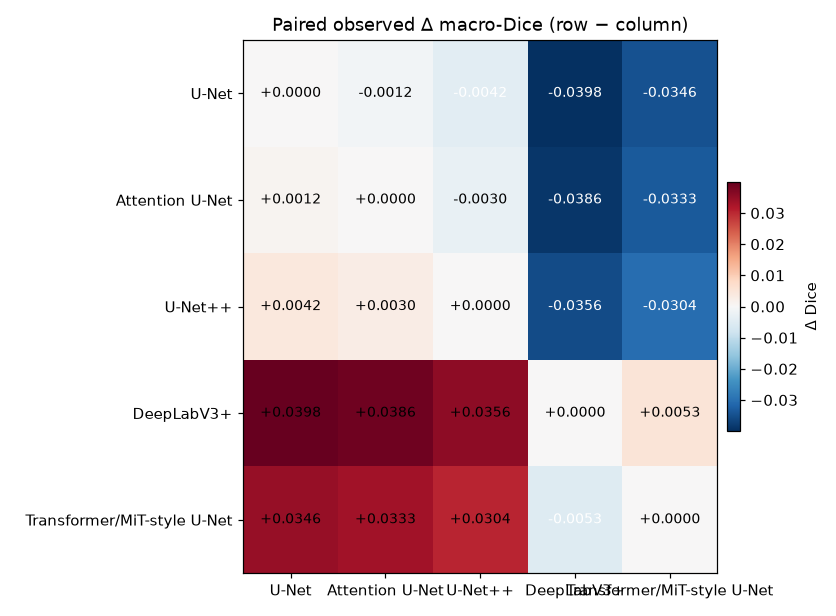

*Figure — Statistical significance matrix*  
`reports/figures/phase20b_five_model_baselines/bootstrap/significance_matrix.png`

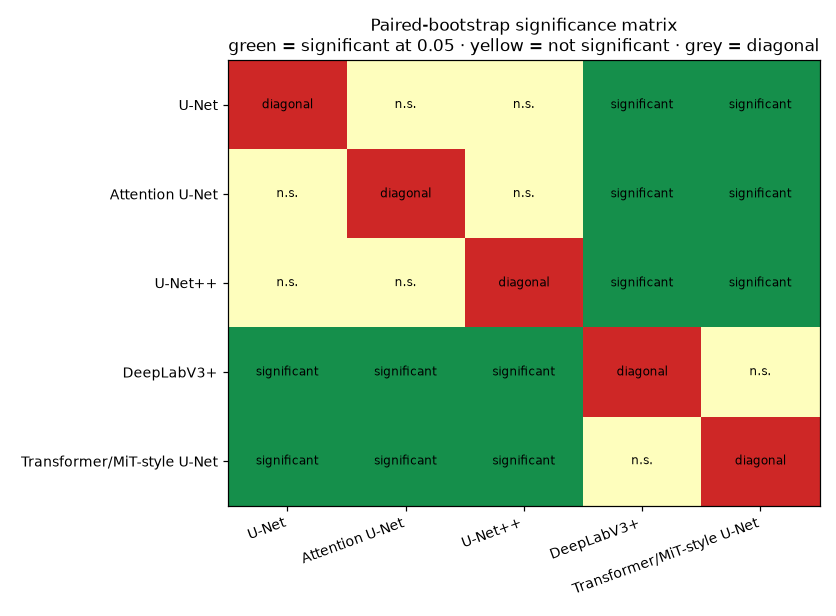

*Figure — Pairwise p-value heatmap*  
`reports/figures/phase20b_five_model_baselines/bootstrap/pvalue_heatmap.png`

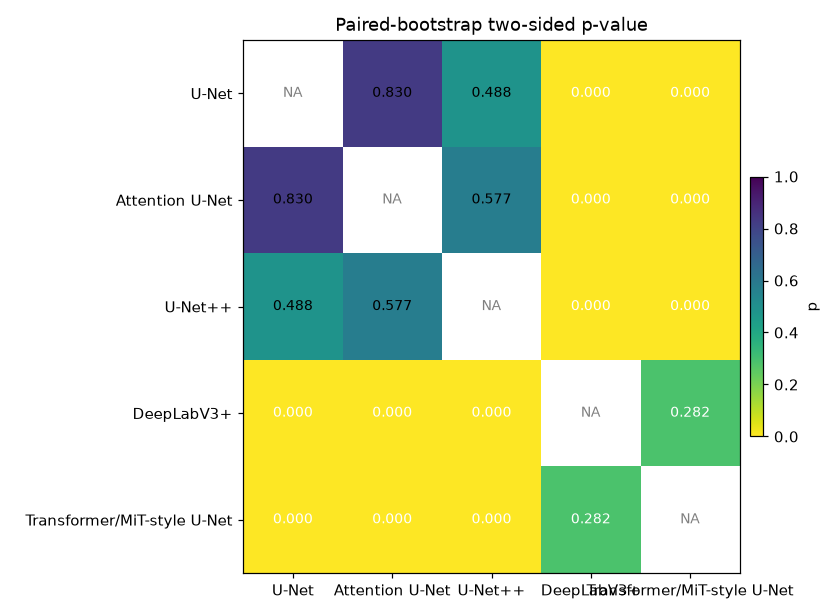

*Figure — Effect-direction heatmap*  
`reports/figures/phase20b_five_model_baselines/bootstrap/effect_direction_heatmap.png`

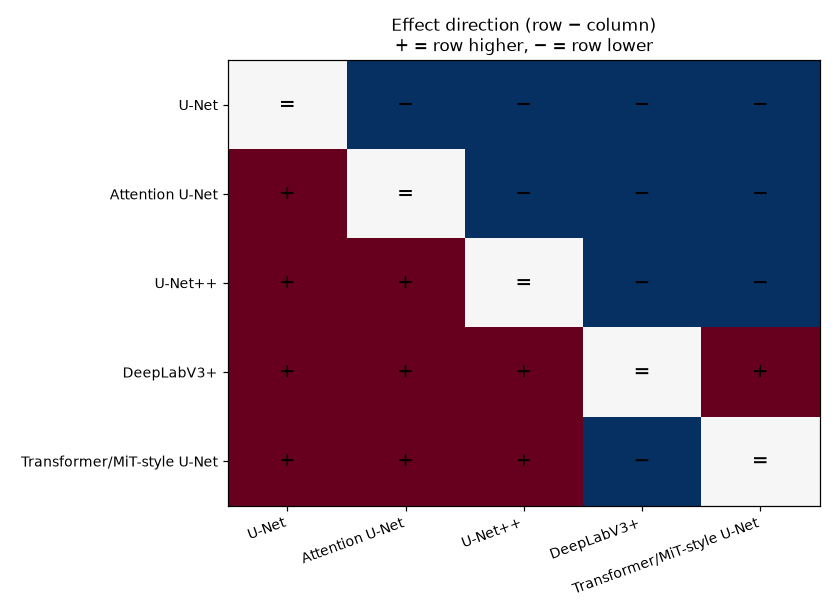

In [17]:
paired = R.load_paired_bootstrap()
display(sty(paired[["model_a", "model_b", "observed_diff", "diff_ci_low", "diff_ci_high",
                    "p_value_two_sided", "significant_at_0.05"]],
            "p20b_paired",
            {"observed_diff": "{:+.6f}", "diff_ci_low": "{:+.6f}",
             "diff_ci_high": "{:+.6f}", "p_value_two_sided": "{:.3f}"}))
display(sty(R.paired_delta_matrix(), "p20b_delta", {c: "{:+.4f}" for c in R.paired_delta_matrix().columns}))
display(sty(R.pvalue_matrix(), "p20b_pval", {c: "{:.3f}" for c in R.pvalue_matrix().columns}))
show_figs(["boot_delta_matrix", "boot_significance_matrix",
           "boot_pvalue_heatmap", "boot_effect_direction"], width=1000)

*Figure — Pairwise CI forest plot*  
`reports/figures/phase20b_five_model_baselines/bootstrap/ci_forest.png`

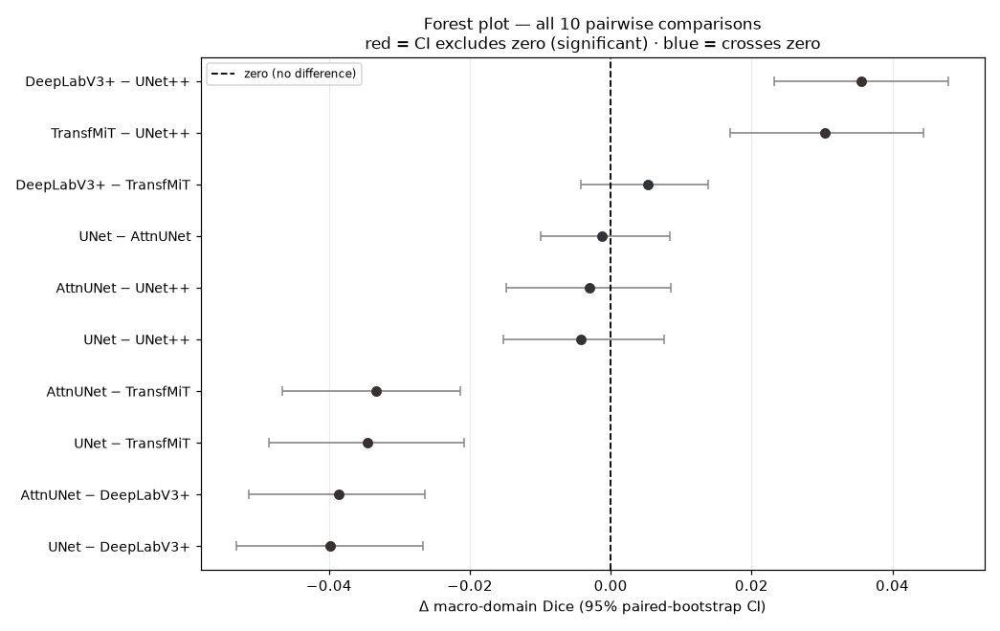

**Top-two result.** `deeplabv3plus` vs `transformer_mit_unet`: Δ +0.005270, 95% CI [-0.004246, +0.013870], p=0.282 → **CI crosses zero; the top-two ordering is NOT statistically significant.** DeepLabV3+ has the highest *observed* macro-domain Dice but must **not** be called the definitive winner.

In [18]:
show_fig("boot_ci_forest", width=1150)
tt = freeze["top_two_paired_bootstrap"]
display(Markdown(
  f"**Top-two result.** `{tt['model_a']}` vs `{tt['model_b']}`: "
  f"Δ {tt['observed_diff']:+.6f}, 95% CI "
  f"[{tt['diff_ci_low']:+.6f}, {tt['diff_ci_high']:+.6f}], p={tt['p_value_two_sided']:.3f} → "
  f"**CI crosses zero; the top-two ordering is NOT statistically significant.** "
  f"DeepLabV3+ has the highest *observed* macro-domain Dice but must **not** be called the "
  f"definitive winner."))
assert tt["ci_excludes_zero"] is False
assert tt["significant_at_0.05"] is False

## 26 · Rank-stability visualization  *(DESCRIPTIVE_BOOTSTRAP_ANALYSIS)*

Reconstructing the frozen paired resampling and re-ranking the five models in every
replicate shows how stable the ordering is. This is descriptive uncertainty only — it is
**not** a new selection gate.

,U-Net,Attention U-Net,U-Net++,DeepLabV3+,Transformer/MiT-style U-Net
rank_1,0.000,0.000,0.000,0.859,0.141
rank_2,0.000,0.000,0.000,0.141,0.859
rank_3,0.158,0.224,0.619,0.000,0.000
rank_4,0.344,0.426,0.230,0.000,0.000
rank_5,0.498,0.350,0.151,0.000,0.000


*Figure — Bootstrap rank stability*  
`reports/figures/phase20b_five_model_baselines/bootstrap/rank_stability.png`

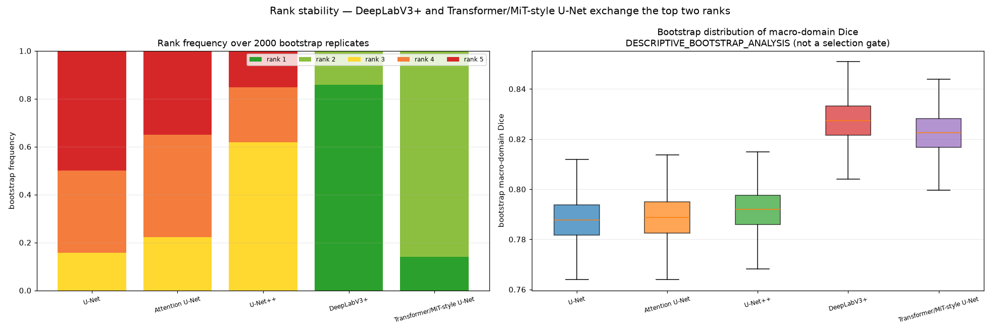

DeepLabV3+ out-ranks Transformer/MiT-style U-Net in **0.859** of bootstrap replicates — i.e. they swap the top two ranks in 0.141 of replicates. Labelled `DESCRIPTIVE_BOOTSTRAP_ANALYSIS`.

In [19]:
rs = R.rank_stability()
display(sty(rs["rank_frequency"], "p20b_rankfreq", {c: "{:.3f}" for c in rs["rank_frequency"].columns}))
show_fig("boot_rank_stability", width=1250)
sup = rs["pairwise_superiority"][("deeplabv3plus", "transformer_mit_unet")]
display(Markdown(f"DeepLabV3+ out-ranks Transformer/MiT-style U-Net in "
                 f"**{sup:.3f}** of bootstrap replicates — i.e. they swap the top two ranks "
                 f"in {1 - sup:.3f} of replicates. Labelled `{rs['label']}`."))

## 21 · Per-case distributions  ·  17b · model × sample performance

Averages hide the tails. Below are per-image box plots, ECDF and violin plots by domain,
plus median/IQR/mean/95% CI summaries.

,model,dataset,n,median,iqr,mean,p05,p95
0,U-Net,ISIC,357,0.9194,0.1071,0.8553,0.5211,0.9744
1,U-Net,BUSI,84,0.8834,0.1073,0.8198,0.4602,0.9467
2,U-Net,KVASIR,87,0.8325,0.2901,0.7552,0.3455,0.9577
3,U-Net,KUB,280,0.7990,0.1523,0.7211,0.0239,0.9077
4,Attention U-Net,ISIC,357,0.9202,0.1162,0.8617,0.5592,0.9745
5,Attention U-Net,BUSI,84,0.8911,0.1212,0.8277,0.4023,0.9563
6,Attention U-Net,KVASIR,87,0.8571,0.2368,0.7710,0.2266,0.9707
7,Attention U-Net,KUB,280,0.7992,0.1964,0.6958,0.0000,0.9101
8,U-Net++,ISIC,357,0.9172,0.1139,0.8601,0.5410,0.9739
9,U-Net++,BUSI,84,0.8694,0.1463,0.8163,0.5692,0.9489


*Figure — Per-image distribution box plots*  
`reports/figures/phase20b_five_model_baselines/distributions/boxplots_by_domain.png`

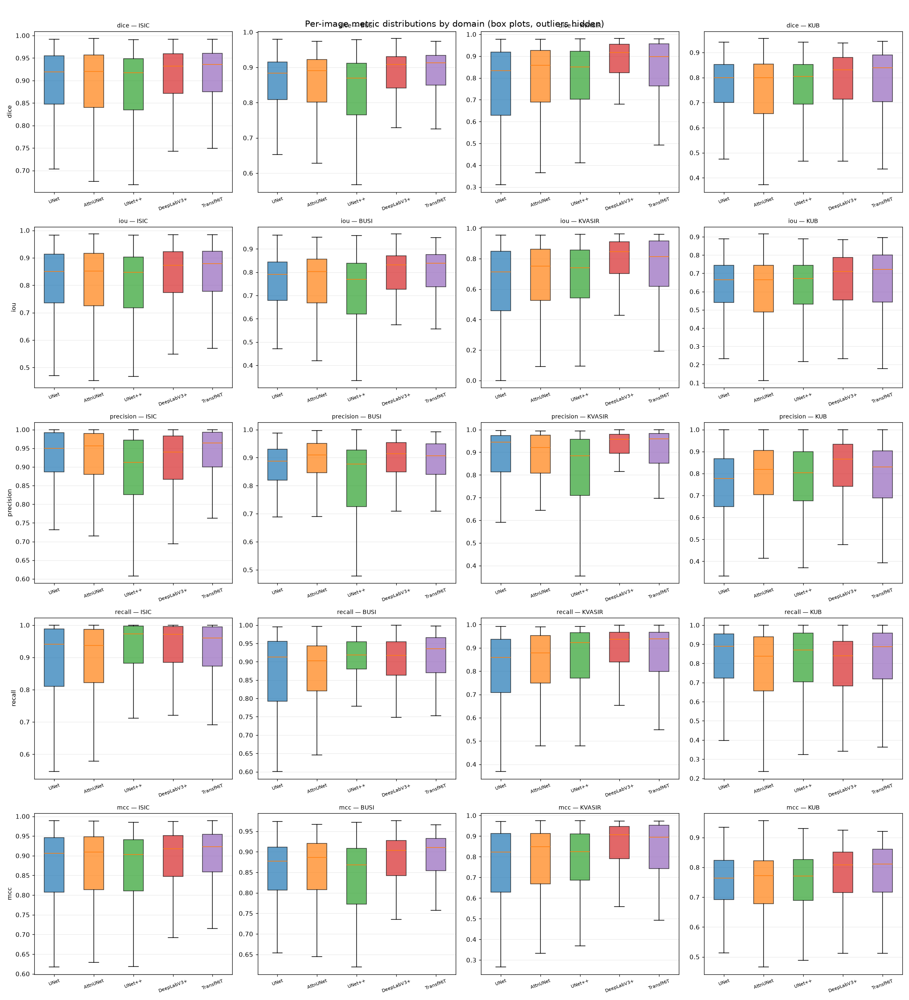

*Figure — Dice ECDF per domain*  
`reports/figures/phase20b_five_model_baselines/distributions/ecdf_dice.png`

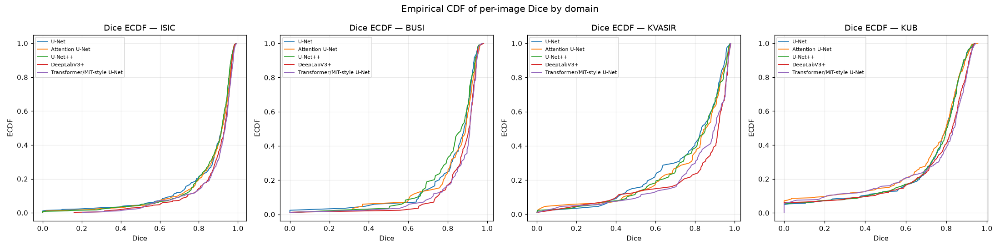

*Figure — Dice violin plots per domain*  
`reports/figures/phase20b_five_model_baselines/distributions/violin_dice.png`

In [20]:
pi5 = R.load_per_image_all5()
summ = []
for m in R.MODEL_ORDER:
    for d in R.DATASET_ORDER:
        v = pi5[(pi5["model_key"] == m) & (pi5["dataset"] == d)]["dice"].dropna()
        summ.append({"model": R.DISPLAY[m], "dataset": d, "n": len(v),
                     "median": v.median(), "iqr": v.quantile(.75) - v.quantile(.25),
                     "mean": v.mean(), "p05": v.quantile(.05), "p95": v.quantile(.95)})
summ = pd.DataFrame(summ)
display(sty(summ, "p20b_distsum", {"median": "{:.4f}", "iqr": "{:.4f}", "mean": "{:.4f}",
                                   "p05": "{:.4f}", "p95": "{:.4f}"}))
show_figs(["dist_boxplots", "dist_ecdf_dice", "dist_violin_dice"], width=1400)

*Figure — model × sample Dice heatmap (global)*  
`reports/figures/phase20b_five_model_baselines/distributions/sample_heatmap_global.png`

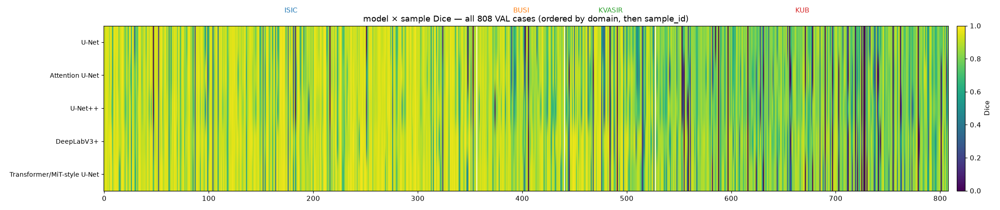

*Figure — model × sample Dice heatmap (by domain)*  
`reports/figures/phase20b_five_model_baselines/distributions/sample_heatmap_domains.png`

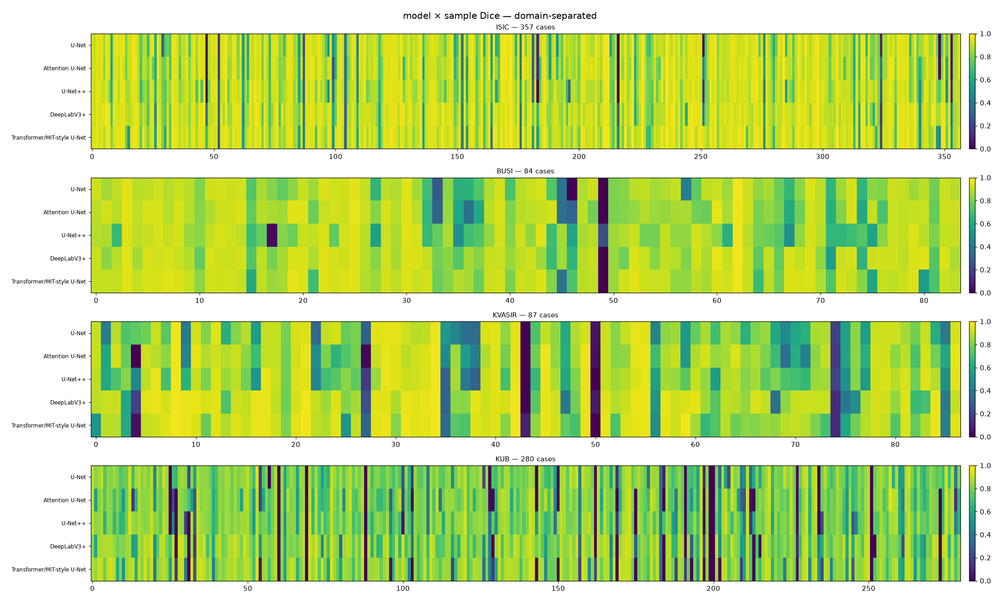

*Figure — Difficult-case heatmap*  
`reports/figures/phase20b_five_model_baselines/distributions/difficult_cases_heatmap.png`

Sample ordering is deterministic (domain, then `sample_id`) and never re-ordered by any single model.

In [21]:
show_fig("dist_sample_heatmap_global", width=1500)
show_fig("dist_sample_heatmap_domains", width=1400)
show_fig("dist_difficult_heatmap", width=1500)
display(Markdown("Sample ordering is deterministic (domain, then `sample_id`) and never "
                 "re-ordered by any single model."))

## 22 · Confusion-matrix analysis

Raw and row-normalised pixel confusion matrices for all **5 models × 4 domains** (= 20
groups), plus the pooled descriptive cell, derived sensitivity / FPR / FNR heatmaps.

,model,scope,tp,tn,fp,fn,row_norm_gt_fg_tp,row_norm_gt_fg_fn,row_norm_gt_bg_fp,row_norm_gt_bg_tn
0,U-Net,ISIC,"13,041,882","76,243,816","1,088,000","3,211,710",0.8024,0.1976,0.0141,0.9859
1,U-Net,BUSI,"911,658","20,779,001","123,398","206,039",0.8157,0.1843,0.0059,0.9941
2,U-Net,KVASIR,"2,349,990","19,078,825","471,665","906,048",0.7217,0.2783,0.0241,0.9759
3,U-Net,KUB,"9,623,687","59,573,828","2,805,092","1,397,713",0.8732,0.1268,0.0450,0.9550
4,U-Net,POOLED_DESCRIPTIVE,"25,927,217","175,675,470","4,488,155","5,721,510",0.8192,0.1808,0.0249,0.9751
5,Attention U-Net,ISIC,"13,181,355","76,348,453","983,363","3,072,237",0.8110,0.1890,0.0127,0.9873
6,Attention U-Net,BUSI,"889,438","20,795,660","106,739","228,259",0.7958,0.2042,0.0051,0.9949
7,Attention U-Net,KVASIR,"2,468,646","19,136,105","414,385","787,392",0.7582,0.2418,0.0212,0.9788
8,Attention U-Net,KUB,"8,846,485","59,958,357","2,420,563","2,174,915",0.8027,0.1973,0.0388,0.9612
9,Attention U-Net,POOLED_DESCRIPTIVE,"25,385,924","176,238,575","3,925,050","6,262,803",0.8021,0.1979,0.0218,0.9782


*Figure — U-Net confusion matrices (raw + row-normalised)*  
`reports/figures/phase20b_five_model_baselines/confusion/confusion_unet.png`

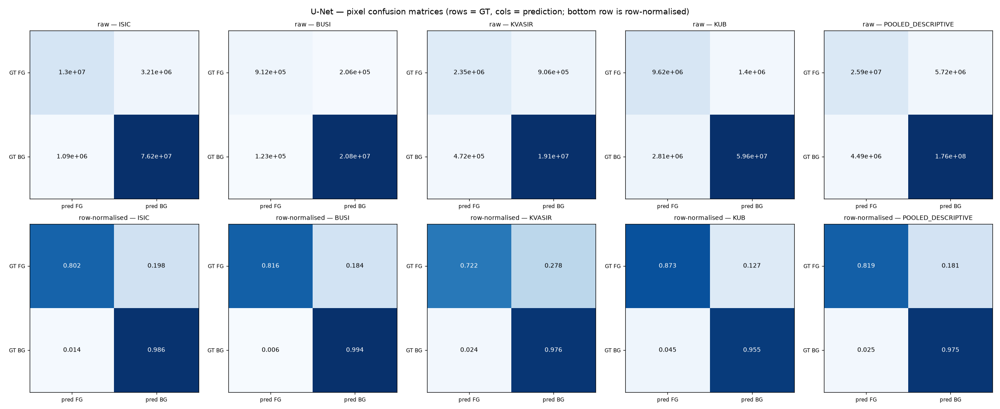

*Figure — Attention U-Net confusion matrices (raw + row-normalised)*  
`reports/figures/phase20b_five_model_baselines/confusion/confusion_attention_unet.png`

*Figure — U-Net++ confusion matrices (raw + row-normalised)*  
`reports/figures/phase20b_five_model_baselines/confusion/confusion_unetpp.png`

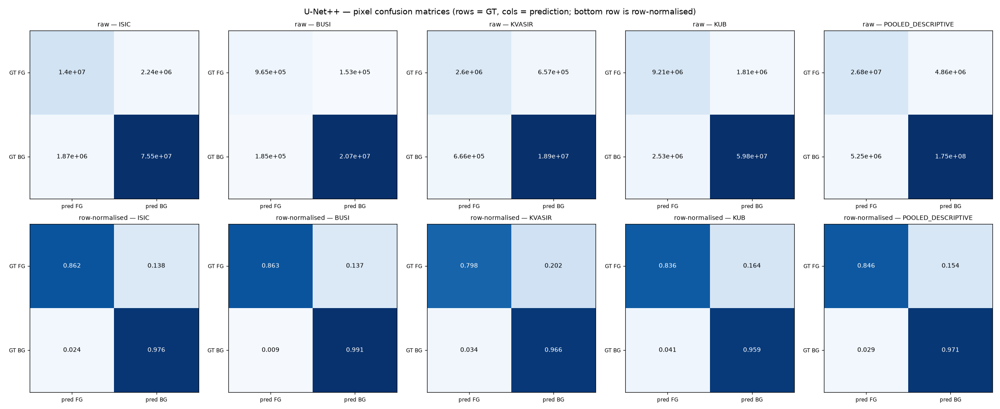

*Figure — DeepLabV3+ confusion matrices (raw + row-normalised)*  
`reports/figures/phase20b_five_model_baselines/confusion/confusion_deeplabv3plus.png`

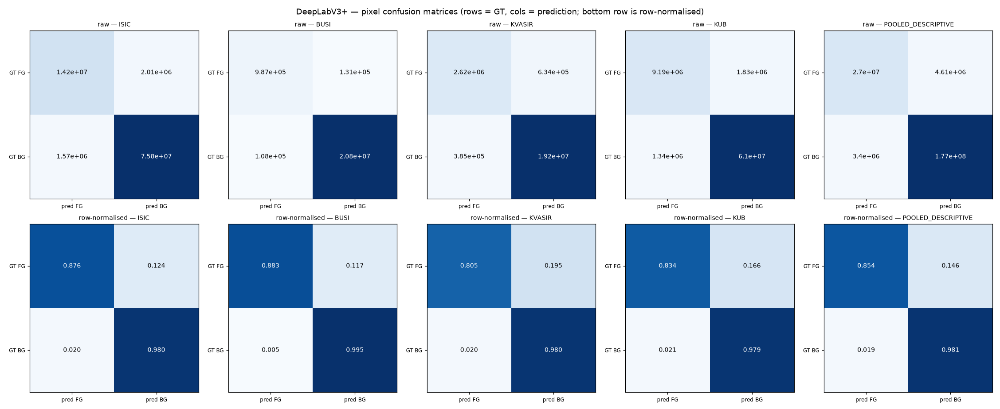

*Figure — Transformer/MiT-style U-Net confusion matrices (raw + row-normalised)*  
`reports/figures/phase20b_five_model_baselines/confusion/confusion_transformer_mit_unet.png`

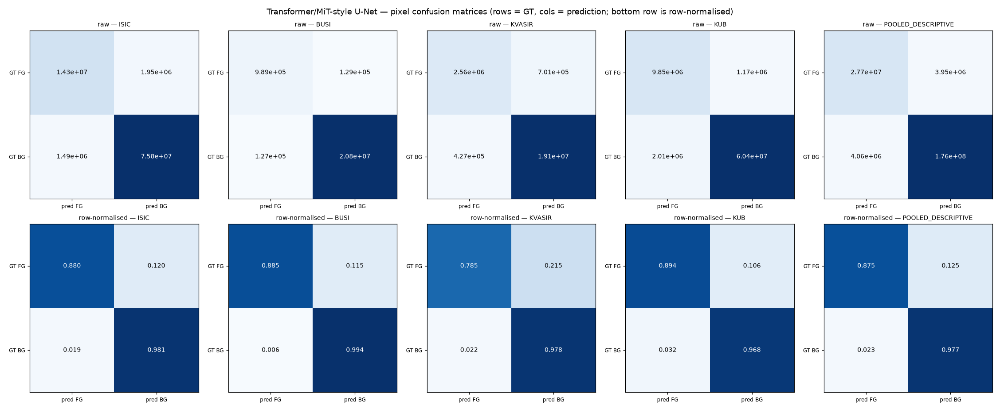

In [22]:
ct = R.confusion_table()
display(sty(ct[["model", "scope", "tp", "tn", "fp", "fn",
                "row_norm_gt_fg_tp", "row_norm_gt_fg_fn",
                "row_norm_gt_bg_fp", "row_norm_gt_bg_tn"]], "p20b_conf",
            {"tp": "{:,}", "tn": "{:,}", "fp": "{:,}", "fn": "{:,}",
             "row_norm_gt_fg_tp": "{:.4f}", "row_norm_gt_fg_fn": "{:.4f}",
             "row_norm_gt_bg_fp": "{:.4f}", "row_norm_gt_bg_tn": "{:.4f}"}))
show_figs([f"confusion_{m}" for m in R.MODEL_ORDER], width=1500)

*Figure — model × domain Sensitivity*  
`reports/figures/phase20b_five_model_baselines/confusion/confusion_metric_heatmap.png`

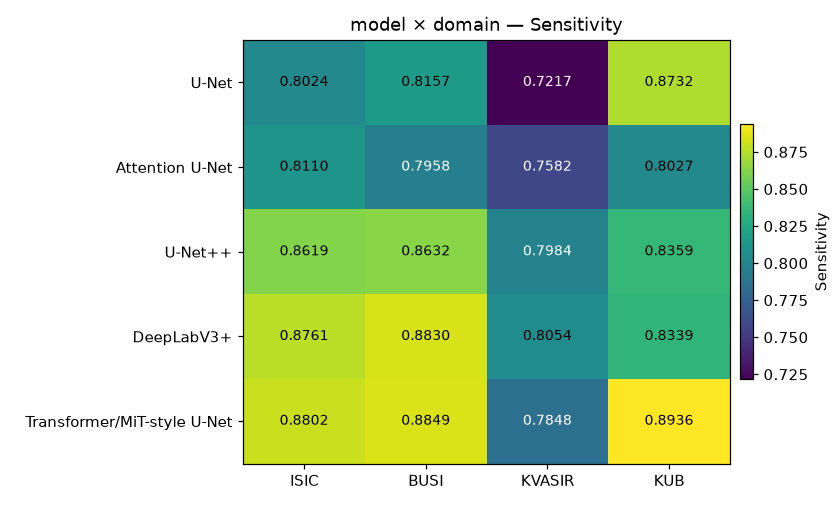

*Figure — model × domain False-positive rate*  
`reports/figures/phase20b_five_model_baselines/confusion/fpr_heatmap.png`

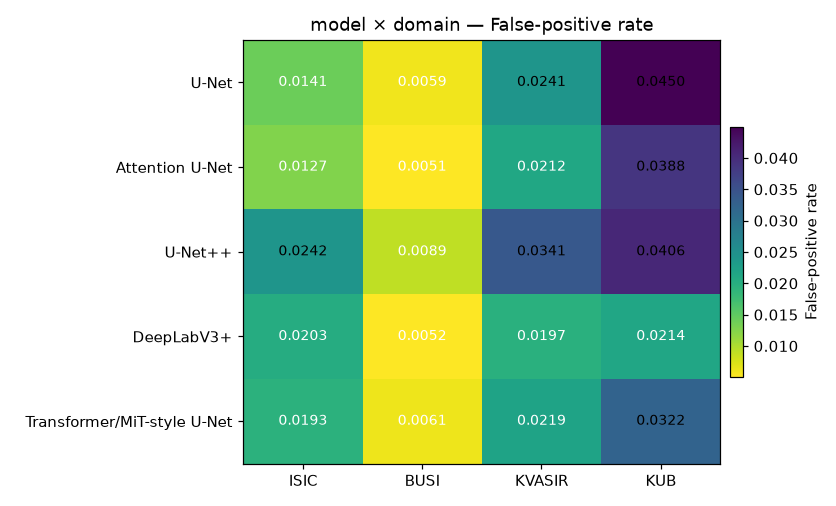

*Figure — model × domain False-negative rate*  
`reports/figures/phase20b_five_model_baselines/confusion/fnr_heatmap.png`

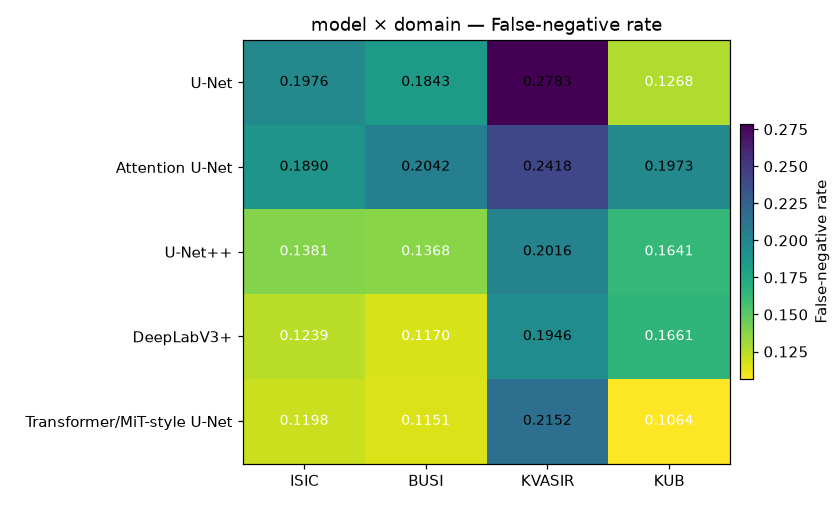

`row_norm_gt_fg_tp` is the sensitivity (recall); `row_norm_gt_bg_fp` is the false-positive rate. Pooled rows are descriptive only.

In [23]:
show_figs(["confusion_sensitivity", "confusion_fpr", "confusion_fnr"], width=1000)
display(Markdown("`row_norm_gt_fg_tp` is the sensitivity (recall); `row_norm_gt_bg_fp` is the "
                 "false-positive rate. Pooled rows are descriptive only."))

## 23 · ROC / PR analysis

Computed from the **persisted probability maps only** (deterministic pixel subsample,
stride 4 — the same protocol as Phase 20A). No model inference is run. Because
segmentation foreground is highly sparse, **PR-AUC is more informative than ROC-AUC**.

dataset,ISIC,BUSI,KVASIR,KUB
model,,,,
U-Net,0.9803,0.9621,0.9469,0.9804
Attention U-Net,0.9826,0.9659,0.9512,0.9743
U-Net++,0.9829,0.9848,0.9654,0.9789
DeepLabV3+,0.9855,0.9844,0.9463,0.9872
Transformer/MiT-style U-Net,0.9876,0.9814,0.9393,0.9882


dataset,ISIC,BUSI,KVASIR,KUB
model,,,,
U-Net,0.9407,0.8873,0.8458,0.9068
Attention U-Net,0.9464,0.8874,0.8717,0.8726
U-Net++,0.9462,0.9072,0.8793,0.8967
DeepLabV3+,0.9564,0.9391,0.8803,0.9374
Transformer/MiT-style U-Net,0.9605,0.9281,0.8602,0.9422


*Figure — ROC per domain*  
`reports/figures/phase20b_five_model_baselines/roc_pr/roc_per_domain.png`

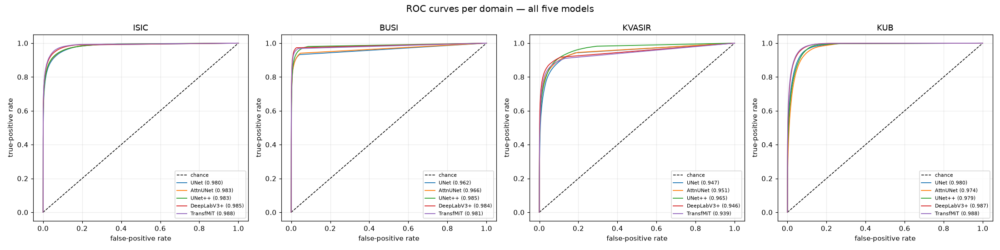

*Figure — PR per domain*  
`reports/figures/phase20b_five_model_baselines/roc_pr/pr_per_domain.png`

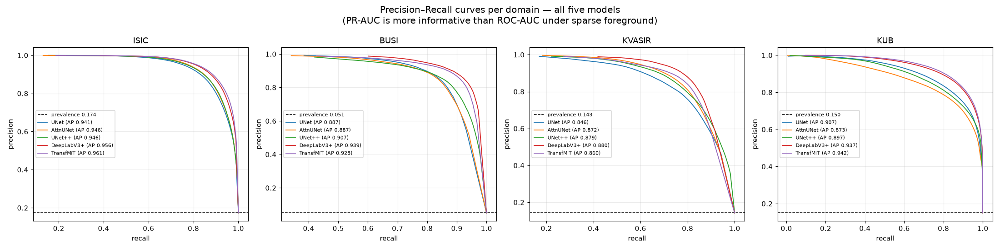

*Figure — model × domain ROC-AUC*  
`reports/figures/phase20b_five_model_baselines/roc_pr/roc_auc_heatmap.png`

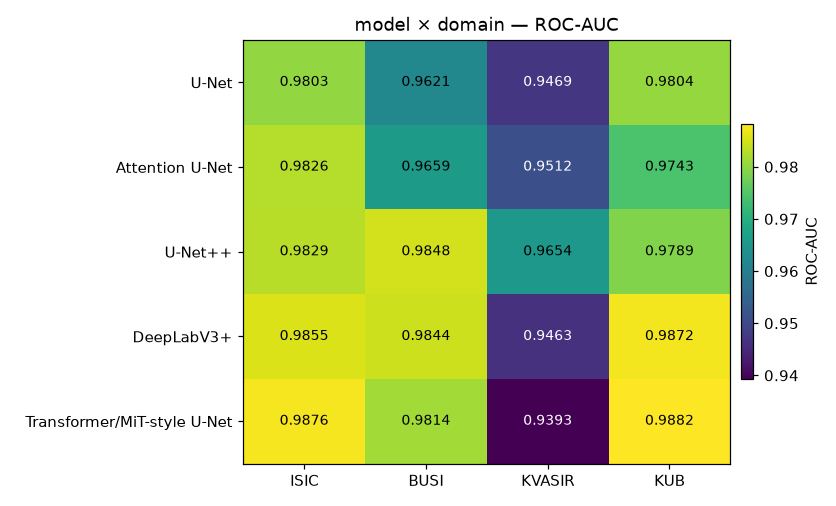

*Figure — model × domain PR-AUC (average precision)*  
`reports/figures/phase20b_five_model_baselines/roc_pr/pr_auc_heatmap.png`

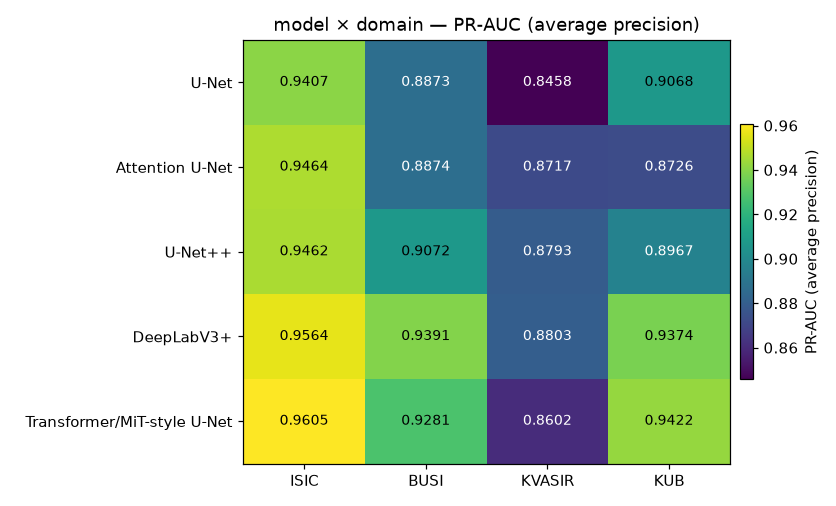

In [24]:
scal = CACHE["scalars"]
roc = scal.pivot(index="model", columns="dataset", values="roc_auc").reindex(
    [R.DISPLAY[m] for m in R.MODEL_ORDER])[R.DATASET_ORDER]
pr = scal.pivot(index="model", columns="dataset", values="pr_auc").reindex(
    [R.DISPLAY[m] for m in R.MODEL_ORDER])[R.DATASET_ORDER]
display(sty(roc, "p20b_roc", {d: "{:.4f}" for d in R.DATASET_ORDER}))
display(sty(pr, "p20b_prauc", {d: "{:.4f}" for d in R.DATASET_ORDER}))
show_figs(["roc_per_domain", "pr_per_domain", "roc_pr_roc_auc", "roc_pr_pr_auc"], width=1400)

## 24 · Calibration analysis

Reliability diagrams plus Brier / ECE / MCE per model and domain, using the identical
deterministic calibration protocol as Phase 20A (stride 4, 15 bins).

dataset,ISIC,BUSI,KVASIR,KUB
model,,,,
U-Net,0.0384,0.0135,0.0536,0.0434
Attention U-Net,0.0360,0.0138,0.0468,0.0482
U-Net++,0.0352,0.0136,0.0494,0.0437
DeepLabV3+,0.0311,0.0094,0.0394,0.0329
Transformer/MiT-style U-Net,0.0297,0.0104,0.0450,0.0323


dataset,ISIC,BUSI,KVASIR,KUB
model,,,,
U-Net,0.0313,0.0125,0.0491,0.0299
Attention U-Net,0.0286,0.0128,0.0423,0.0316
U-Net++,0.0246,0.0122,0.0433,0.0255
DeepLabV3+,0.0240,0.0083,0.0353,0.0199
Transformer/MiT-style U-Net,0.0222,0.0094,0.0417,0.0181


dataset,ISIC,BUSI,KVASIR,KUB
model,,,,
U-Net,0.2526,0.3383,0.3113,0.2904
Attention U-Net,0.2462,0.2934,0.3088,0.2097
U-Net++,0.2453,0.4084,0.4144,0.2141
DeepLabV3+,0.2354,0.2683,0.3146,0.1598
Transformer/MiT-style U-Net,0.2219,0.3327,0.3285,0.2314


*Figure — Reliability diagrams per domain*  
`reports/figures/phase20b_five_model_baselines/calibration/reliability_per_domain.png`

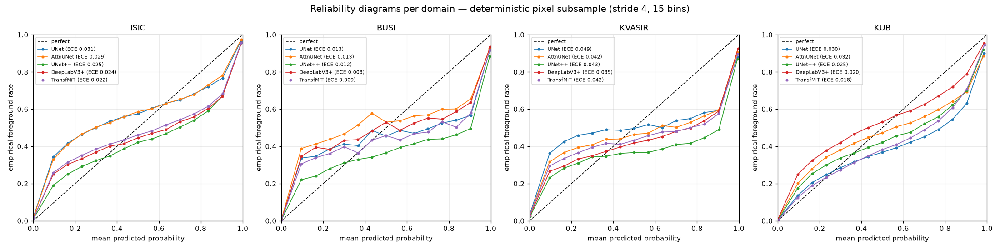

*Figure — model × domain Expected calibration error*  
`reports/figures/phase20b_five_model_baselines/calibration/ece_heatmap.png`

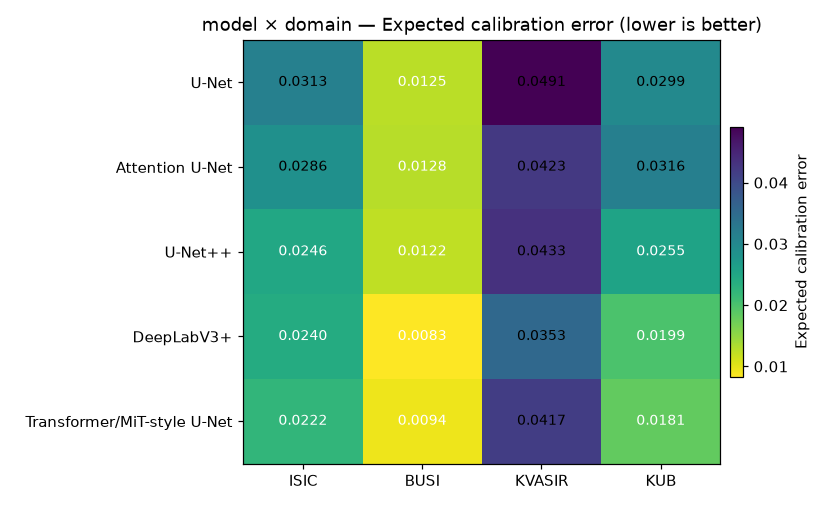

*Figure — model × domain Brier score*  
`reports/figures/phase20b_five_model_baselines/calibration/brier_heatmap.png`

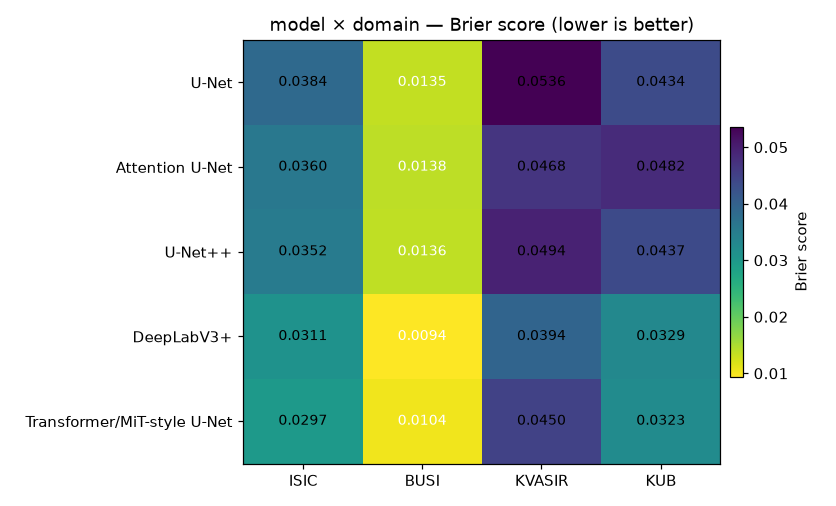

*Figure — model × domain Maximum calibration error*  
`reports/figures/phase20b_five_model_baselines/calibration/mce_heatmap.png`

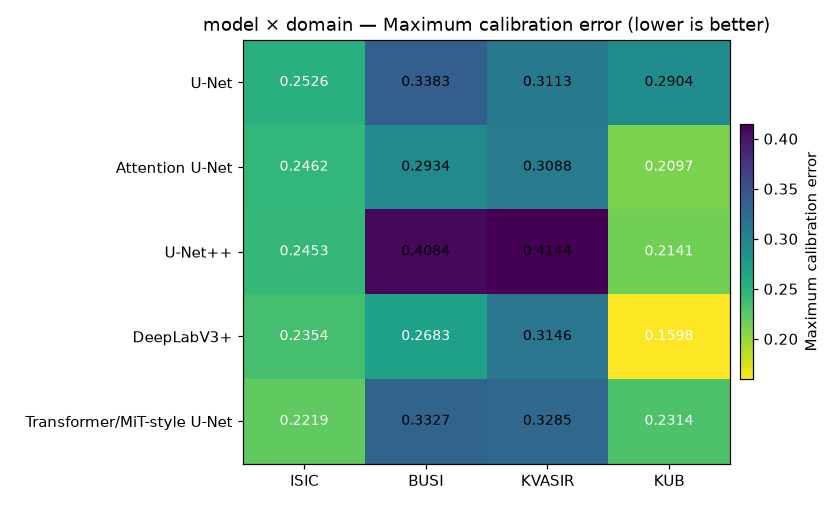

In [25]:
brier = scal.pivot(index="model", columns="dataset", values="brier").reindex(
    [R.DISPLAY[m] for m in R.MODEL_ORDER])[R.DATASET_ORDER]
ece = scal.pivot(index="model", columns="dataset", values="ece").reindex(
    [R.DISPLAY[m] for m in R.MODEL_ORDER])[R.DATASET_ORDER]
mce = scal.pivot(index="model", columns="dataset", values="mce").reindex(
    [R.DISPLAY[m] for m in R.MODEL_ORDER])[R.DATASET_ORDER]
display(sty(brier, "p20b_brier", {d: "{:.4f}" for d in R.DATASET_ORDER}))
display(sty(ece, "p20b_ece", {d: "{:.4f}" for d in R.DATASET_ORDER}))
display(sty(mce, "p20b_mce", {d: "{:.4f}" for d in R.DATASET_ORDER}))
show_figs(["calib_reliability", "calib_ece", "calib_brier", "calib_mce"], width=1250)

## 25 · Boundary-quality analysis

HD95, ASSD and Surface Dice per model and domain. Boundary metrics are computed only where
both masks are non-empty; the frozen sentinel rule excludes invalid cases from the mean and
reports the valid count (`hd95_valid_n`, `surface_dice_valid_n`).

,model,ISIC,BUSI,KVASIR,KUB
0,U-Net,41.4789,47.3726,81.9799,64.8736
1,Attention U-Net,44.2635,36.1544,79.0066,60.4375
2,U-Net++,43.2006,61.0157,88.2919,59.9828
3,DeepLabV3+,29.5371,18.8416,61.4202,48.4004
4,Transformer/MiT-style U-Net,28.0593,21.7288,57.7223,56.1530


,model,ISIC,BUSI,KVASIR,KUB
0,U-Net,13.8888,11.3319,21.5651,24.6111
1,Attention U-Net,13.4268,8.5213,19.8587,20.5996
2,U-Net++,13.2372,13.7305,22.7038,20.6270
3,DeepLabV3+,10.6176,5.4153,16.2039,18.5640
4,Transformer/MiT-style U-Net,10.4474,5.9014,16.1206,21.3414


,model,ISIC,BUSI,KVASIR,KUB
0,U-Net,0.3151,0.3937,0.3746,0.3329
1,Attention U-Net,0.3223,0.4193,0.4013,0.3274
2,U-Net++,0.2795,0.3982,0.3732,0.3331
3,DeepLabV3+,0.3171,0.4180,0.4574,0.3323
4,Transformer/MiT-style U-Net,0.3455,0.4398,0.4508,0.3060


*Figure — model × domain HD95 (pixels)*  
`reports/figures/phase20b_five_model_baselines/boundary/hd95_heatmap.png`

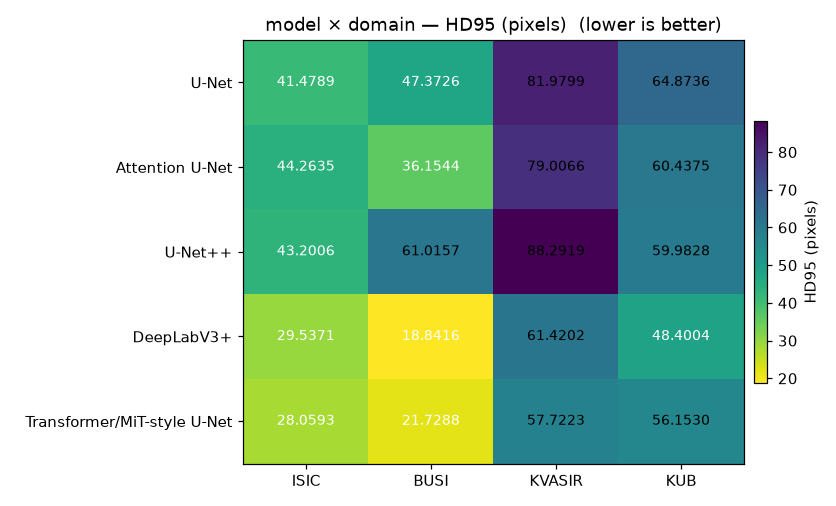

*Figure — model × domain ASSD (pixels)*  
`reports/figures/phase20b_five_model_baselines/boundary/assd_heatmap.png`

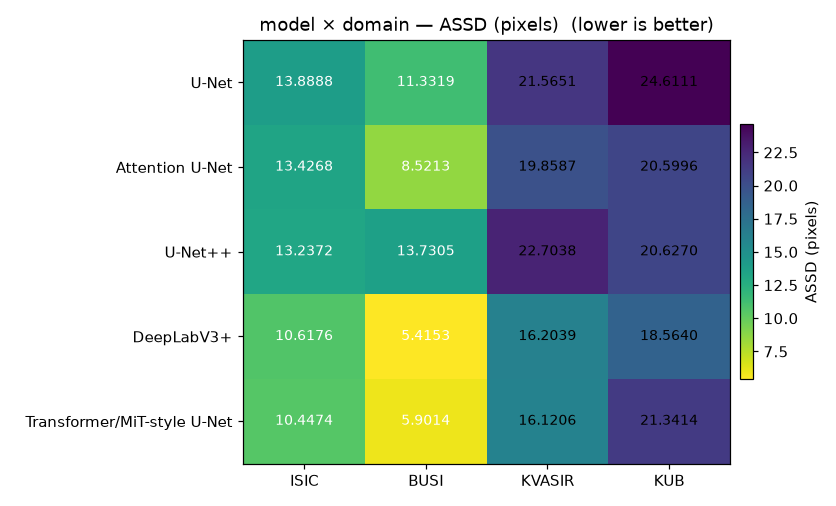

*Figure — model × domain Surface Dice*  
`reports/figures/phase20b_five_model_baselines/boundary/surface_dice_heatmap.png`

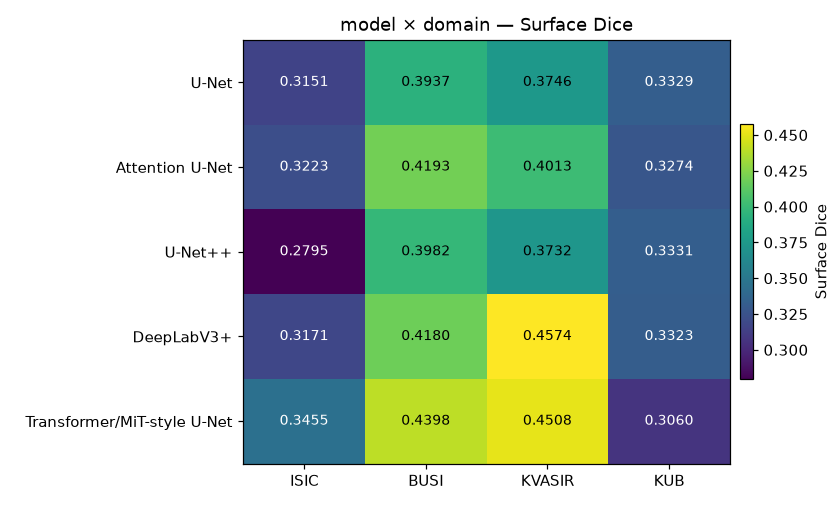

*Figure — Boundary metrics grouped bars*  
`reports/figures/phase20b_five_model_baselines/boundary/boundary_grouped_bars.png`

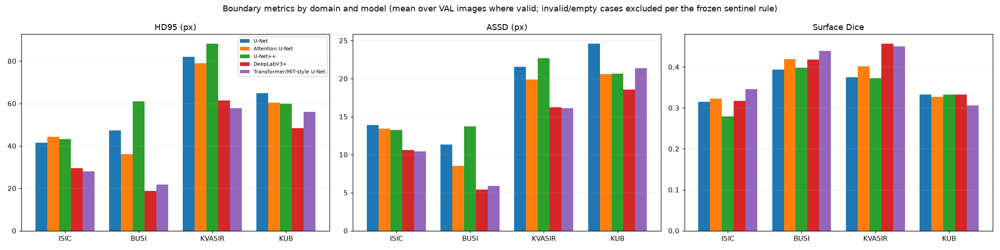

In [26]:
for met, uid in [("hd95", "p20b_hd95"), ("assd", "p20b_assd"), ("surface_dice", "p20b_sd")]:
    m = R.domain_metric_matrix(met).set_index("model")[R.DATASET_ORDER]
    display(sty(m.reset_index(), uid, {d: "{:.4f}" for d in R.DATASET_ORDER}))
show_figs(["boundary_hd95", "boundary_assd", "boundary_surface_dice", "boundary_grouped_bars"],
          width=1400)

## 27 · KUB subgroup analysis  *(REPORTING ONLY)*

Kidney / Bladder / Ureteric stone subgroups plus `KUB_ALL`. These native category labels are
**reporting only** and are never model inputs.

,model_key,model,Kidney_Stone,Bladder_Stone,Ureteric_Stone,KUB_ALL
0,unet,U-Net,0.7489,0.6926,0.7622,0.7211
1,attention_unet,Attention U-Net,0.7020,0.6819,0.7498,0.6958
2,unetpp,U-Net++,0.7523,0.6930,0.7389,0.7207
3,deeplabv3plus,DeepLabV3+,0.7704,0.7025,0.8079,0.7387
4,transformer_mit_unet,Transformer/MiT-style U-Net,0.7667,0.6864,0.7643,0.7252


,model_key,model,Kidney_Stone,Bladder_Stone,Ureteric_Stone,KUB_ALL
0,unet,U-Net,0.7677,0.7734,0.8660,0.7791
1,attention_unet,Attention U-Net,0.6978,0.7285,0.8598,0.7275
2,unetpp,U-Net++,0.7456,0.7748,0.8572,0.7702
3,deeplabv3plus,DeepLabV3+,0.7534,0.7293,0.8437,0.7487
4,transformer_mit_unet,Transformer/MiT-style U-Net,0.7551,0.7652,0.8549,0.7689


*Figure — KUB subgroup Dice heatmap*  
`reports/figures/phase20b_five_model_baselines/kub_subgroups/subgroup_dice_heatmap.png`

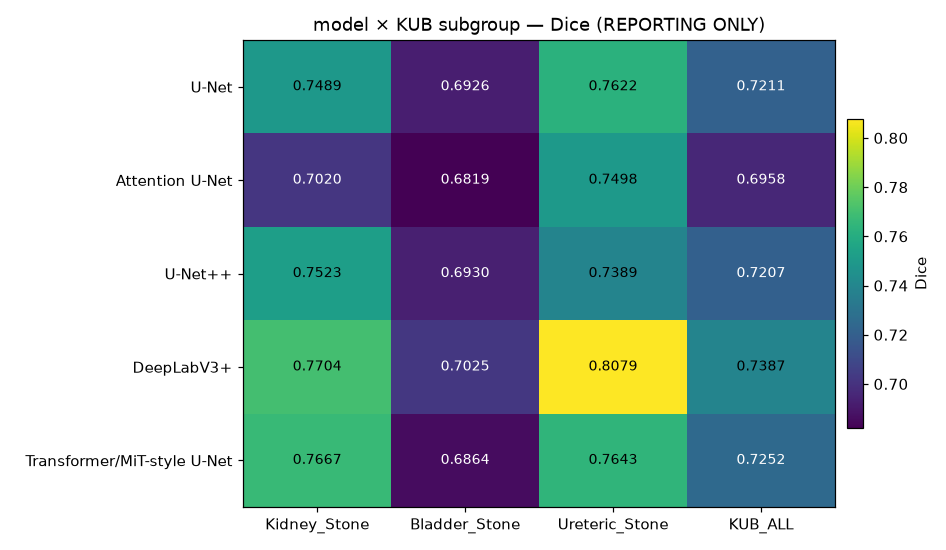

*Figure — KUB subgroup Dice grouped bars*  
`reports/figures/phase20b_five_model_baselines/kub_subgroups/subgroup_dice_bars.png`

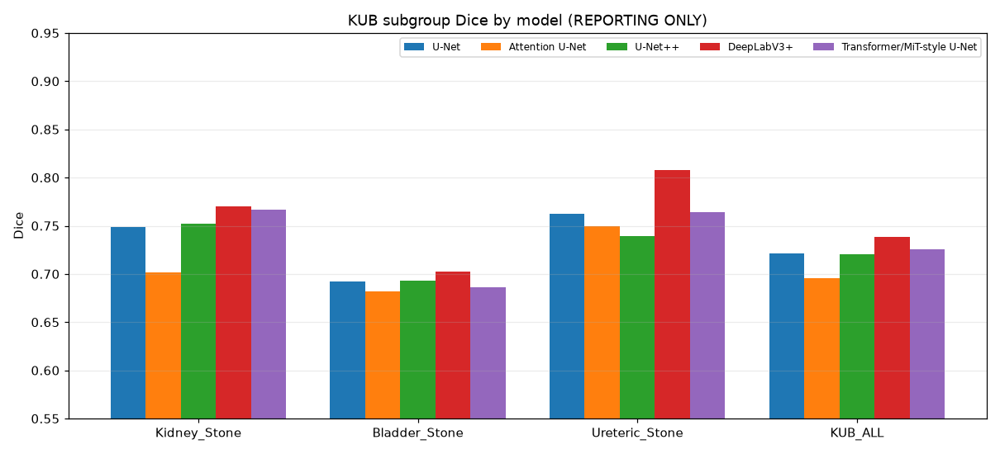

*Figure — KUB subgroup recall heatmap*  
`reports/figures/phase20b_five_model_baselines/kub_subgroups/subgroup_recall_heatmap.png`

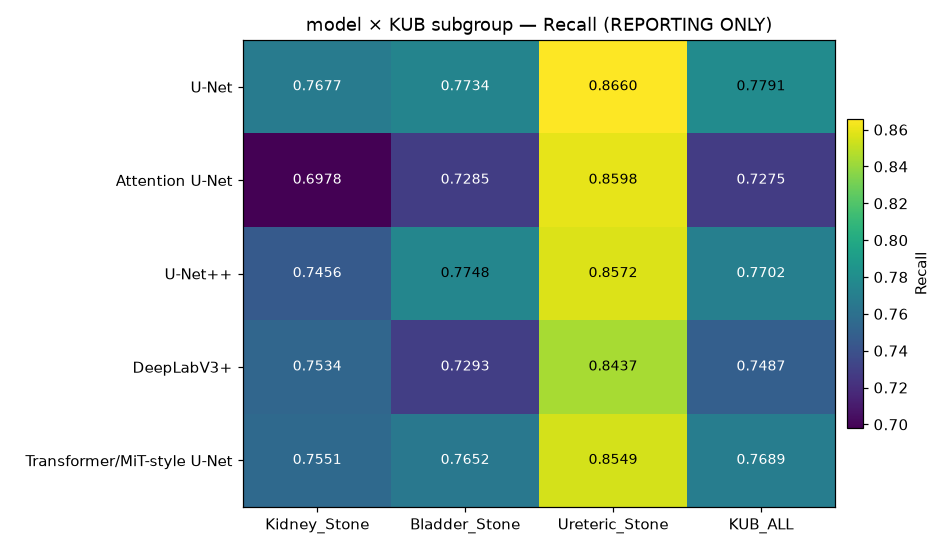

*Figure — KUB subgroup empty-prediction rate*  
`reports/figures/phase20b_five_model_baselines/kub_subgroups/subgroup_empty_rate.png`

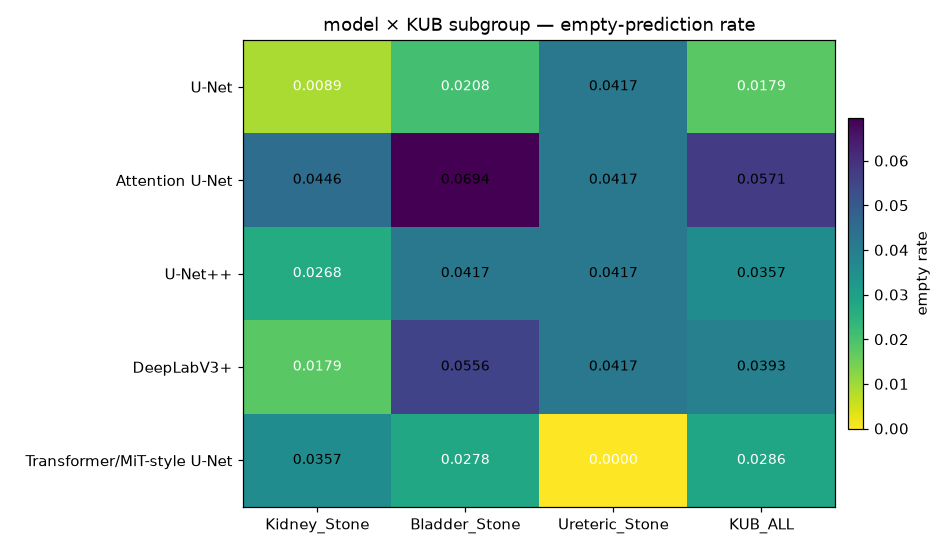

In [27]:
subs = ["Kidney_Stone", "Bladder_Stone", "Ureteric_Stone", "KUB_ALL"]
for met, uid in [("dice", "p20b_subd"), ("recall", "p20b_subr")]:
    m = R.kub_subgroup_matrix(met)
    display(sty(m, uid, {s: "{:.4f}" for s in subs}))
show_figs(["kubsub_dice_heatmap", "kubsub_dice_bars",
           "kubsub_recall_heatmap", "kubsub_empty_rate"], width=1100)

## 28 · KUB size-stratification analysis

Frozen taxonomy `kub_size_clean_v3_v1` only: FULL_FIELD strata TINY / SMALL / MEDIUM /
LARGE, with `ROI_NOT_PRIMARY_BINNED` kept **separate** because ROI crops are a different
acquisition regime and are not directly comparable.

stratum n: TINY=44, SMALL=19, MEDIUM=27, LARGE=13, ROI_NOT_PRIMARY_BINNED=177

,model_key,model,TINY,SMALL,MEDIUM,LARGE,ROI_NOT_PRIMARY_BINNED
0,unet,U-Net,0.5079,0.6496,0.6158,0.6277,0.8047
1,attention_unet,Attention U-Net,0.4951,0.5796,0.5970,0.6773,0.7745
2,unetpp,U-Net++,0.5314,0.6806,0.6408,0.6359,0.7904
3,deeplabv3plus,DeepLabV3+,0.4147,0.6234,0.6561,0.6867,0.8480
4,transformer_mit_unet,Transformer/MiT-style U-Net,0.3757,0.5670,0.6201,0.6238,0.8525


,model_key,model,TINY,SMALL,MEDIUM,LARGE,ROI_NOT_PRIMARY_BINNED
0,unet,U-Net,0.3928,0.5281,0.4874,0.5287,0.6850
1,attention_unet,Attention U-Net,0.3968,0.4708,0.4781,0.5741,0.6532
2,unetpp,U-Net++,0.4231,0.5514,0.5169,0.5311,0.6699
3,deeplabv3plus,DeepLabV3+,0.3128,0.4837,0.5190,0.5772,0.7428
4,transformer_mit_unet,Transformer/MiT-style U-Net,0.2796,0.4513,0.5032,0.5143,0.7494


*Figure — KUB size-stratum Dice heatmap*  
`reports/figures/phase20b_five_model_baselines/kub_size/size_dice_heatmap.png`

*Figure — KUB size-stratum Dice grouped bars*  
`reports/figures/phase20b_five_model_baselines/kub_size/size_dice_grouped_bars.png`

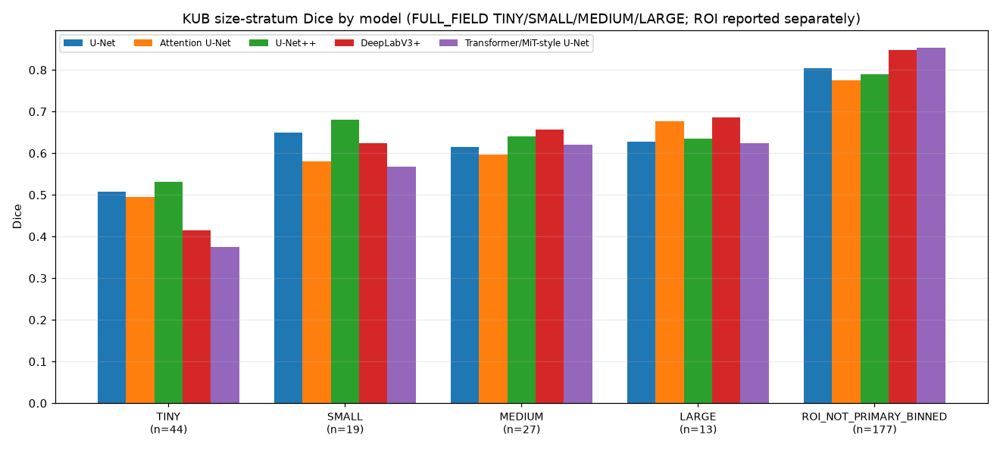

*Figure — Size-stratum × model interaction*  
`reports/figures/phase20b_five_model_baselines/kub_size/size_stratum_model_interaction.png`

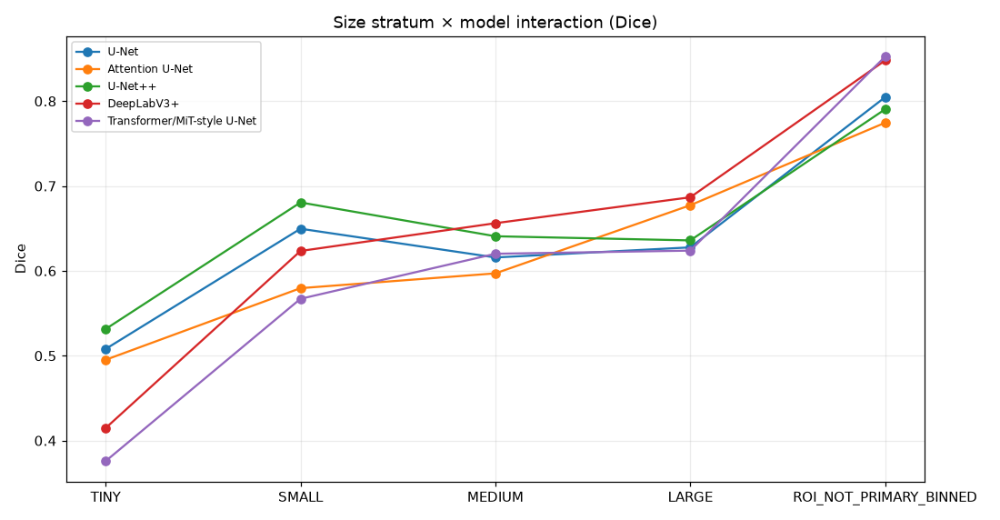

*Figure — FULL_FIELD vs ROI descriptive comparison*  
`reports/figures/phase20b_five_model_baselines/kub_size/roi_vs_fullfield.png`

In [28]:
strata = ["TINY", "SMALL", "MEDIUM", "LARGE", "ROI_NOT_PRIMARY_BINNED"]
ns = R.kub_size_n()
display(Markdown("stratum n: " + ", ".join(f"{k}={v}" for k, v in ns.items())))
for met, uid in [("dice", "p20b_szd"), ("iou", "p20b_szi")]:
    m = R.kub_size_matrix(met)
    display(sty(m, uid, {s: "{:.4f}" for s in strata}))
show_figs(["kubsize_dice_heatmap", "kubsize_dice_bars",
           "kubsize_interaction", "kubsize_roi_vs_ff"], width=1150)

## 29 · TINY-target special analysis

KUB tiny objects are the project's known bottleneck. Below: TINY Dice distribution, TINY
per-case heatmap, and TINY-vs-overall decoupling, for all five models.

,model,n,mean,median,q25,q75
0,Attention U-Net,44,0.4951,0.6330,0.0000,0.8000
1,DeepLabV3+,44,0.4147,0.5060,0.0000,0.7024
2,Transformer/MiT-style U-Net,44,0.3757,0.3852,0.0419,0.6721
3,U-Net,44,0.5079,0.6550,0.2189,0.7520
4,U-Net++,44,0.5314,0.6667,0.2627,0.8031


*Figure — KUB TINY Dice distribution*  
`reports/figures/phase20b_five_model_baselines/tiny/tiny_dice_distribution.png`

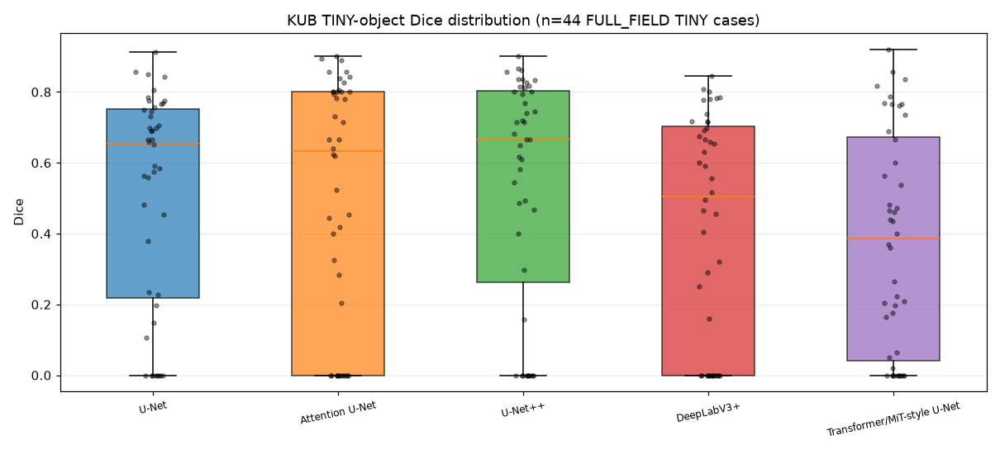

*Figure — TINY per-case Dice heatmap*  
`reports/figures/phase20b_five_model_baselines/tiny/tiny_case_heatmap.png`

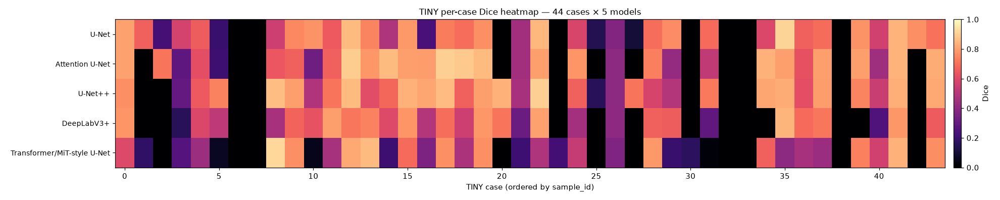

*Figure — TINY vs macro performance*  
`reports/figures/phase20b_five_model_baselines/tiny/tiny_vs_macro.png`

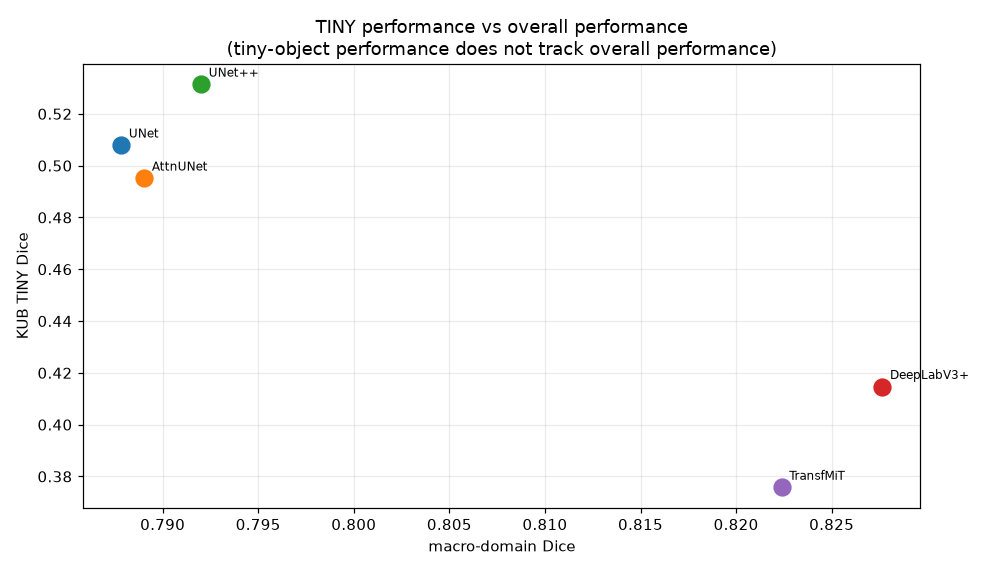

In [29]:
tiny = R.tiny_per_sample()
tstat = tiny.groupby("model")["dice"].agg(["count", "mean", "median",
                                           lambda s: s.quantile(.25),
                                           lambda s: s.quantile(.75)])
tstat.columns = ["n", "mean", "median", "q25", "q75"]
display(sty(tstat.reset_index(), "p20b_tiny", {"mean": "{:.4f}", "median": "{:.4f}",
                                               "q25": "{:.4f}", "q75": "{:.4f}"}))
show_figs(["tiny_dice_distribution", "tiny_case_heatmap", "tiny_vs_macro"], width=1300)

## 30 · Empty-prediction analysis  ·  31 · FP / FN burden analysis

,model,dataset,n,gt_empty_n,pred_empty_n,empty_prediction_rate,gt_empty_pred_nonempty_n,gt_nonempty_pred_empty_n
0,U-Net,ISIC,357,0,1,0.0028,0,1
1,U-Net,BUSI,84,0,1,0.0119,0,1
2,U-Net,KVASIR,87,0,1,0.0115,0,1
3,U-Net,KUB,280,0,5,0.0179,0,5
4,Attention U-Net,ISIC,357,0,1,0.0028,0,1
5,Attention U-Net,BUSI,84,0,1,0.0119,0,1
6,Attention U-Net,KVASIR,87,0,1,0.0115,0,1
7,Attention U-Net,KUB,280,0,16,0.0571,0,16
8,U-Net++,ISIC,357,0,2,0.0056,0,2
9,U-Net++,BUSI,84,0,0,0.0000,0,0


,model,dataset,mean_fp_pixels,mean_fn_pixels,fp_burden_ratio,fn_burden_ratio,complete_miss_n,fp_on_empty_gt_n
0,U-Net,ISIC,3047.6,8996.4,0.0669,0.1976,1,0
1,U-Net,BUSI,1469.0,2452.8,0.1104,0.1843,1,0
2,U-Net,KVASIR,5421.4,10414.3,0.1449,0.2783,1,0
3,U-Net,KUB,10018.2,4991.8,0.2545,0.1268,5,0
4,Attention U-Net,ISIC,2754.5,8605.7,0.0605,0.1890,1,0
5,Attention U-Net,BUSI,1270.7,2717.4,0.0955,0.2042,1,0
6,Attention U-Net,KVASIR,4763.0,9050.5,0.1273,0.2418,1,0
7,Attention U-Net,KUB,8644.9,7767.6,0.2196,0.1973,16,0
8,U-Net++,ISIC,5232.5,6285.7,0.1149,0.1381,2,0
9,U-Net++,BUSI,2205.2,1820.7,0.1657,0.1368,0,0


*Figure — model × domain FP burden ratio (FP / GT-FG px)*  
`reports/figures/phase20b_five_model_baselines/failure_cases/fp_burden_heatmap.png`

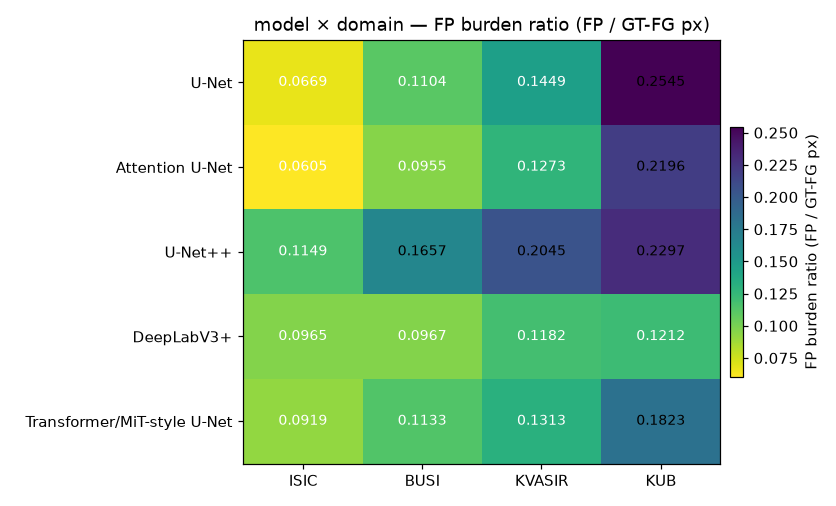

*Figure — model × domain FN burden ratio (FN / GT-FG px)*  
`reports/figures/phase20b_five_model_baselines/failure_cases/fn_burden_heatmap.png`

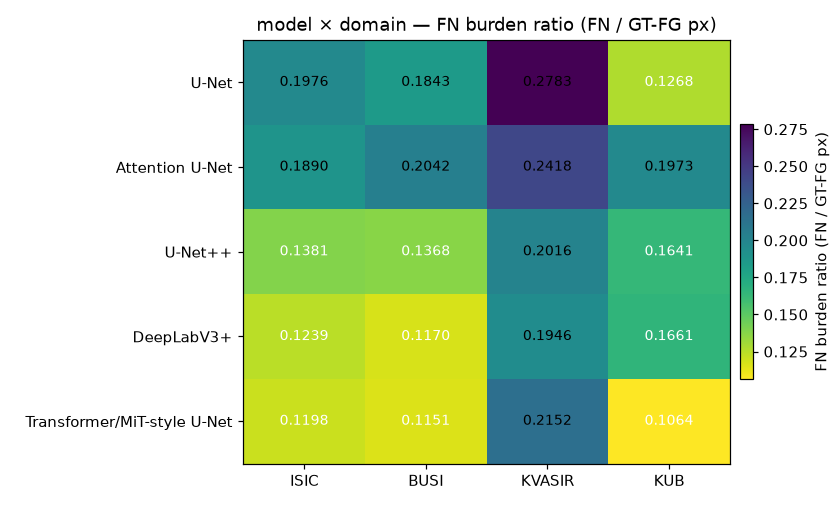

*Figure — Failure counts heatmaps*  
`reports/figures/phase20b_five_model_baselines/failure_cases/failure_counts.png`

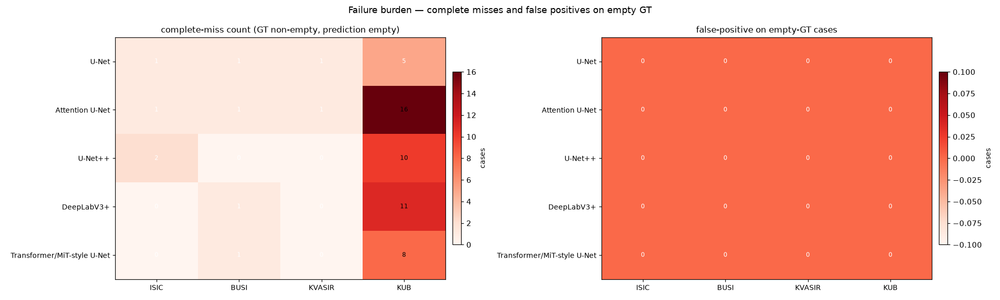

In [30]:
emp = R.empty_prediction_table()
display(sty(emp[["model", "dataset", "n", "gt_empty_n", "pred_empty_n", "empty_prediction_rate",
                 "gt_empty_pred_nonempty_n", "gt_nonempty_pred_empty_n"]], "p20b_empty",
            {"empty_prediction_rate": "{:.4f}"}))
fb = R.failure_burden_table()
display(sty(fb[["model", "dataset", "mean_fp_pixels", "mean_fn_pixels",
                "fp_burden_ratio", "fn_burden_ratio", "complete_miss_n", "fp_on_empty_gt_n"]],
            "p20b_fb", {"mean_fp_pixels": "{:.1f}", "mean_fn_pixels": "{:.1f}",
                        "fp_burden_ratio": "{:.4f}", "fn_burden_ratio": "{:.4f}"}))
show_figs(["failure_fp_burden_ratio", "failure_fn_burden_ratio", "failure_counts"], width=1400)

## 32 · Common-failure analysis  *(OUTCOME-BASED galleries)*

These galleries are **outcome-based analytical** selections with deterministic, reported
rules. They are deliberately **not** the prediction-independent canonical 64-case gallery.

**Selection rules (first cases per rule):**  
`RULESET:{"all_models_fail": ["980faa74400c37c5704a3bdc97116e4f", "1e5065d7179c200f16560f9c74fb001e", "21c6342179f5a1bed9699cdb311717f1", "4550f9075276b23eac8ab1811b42fb26"], "two_stage_success_unet_fail": ["599e05b01c746597dbd6b23b7f36c52e", "59007da26fb1f08e42bca7f9b912048e", "72a89c3d0ca53e2fa17e11b650036c4a"], "unet_family_success": ["4a166fffe41b3f511fb5520719e83b09"], "max_disagreement": ["0012a4db87568a44b326db45138d2147", "00849cbfea1e926cc0bf0443c9a57ac0", "0114095ec4368201be5cbc6b4a134ab5", "011cdf8573a4bc0fc5c2f36ba9a1b225"], "kub_tiny_misses": ["0785b56594049121d6281aa40e475e26", "15c6b69254f60701d181da403d8c2906", "1ba084b5439ffee651b4f5e0697e2209", "1e08d0c4a0448b41b2dbb61a1160c203"], "fp_heavy": ["4a861436fef3ba977fbcfb327e5922be", "4a3035354e73fa4d4787f26d899e2def", "59007da26fb1f08e42bca7f9b912048e", "39431a6a05f2a9552da20691f52b2b3c"], "fn_heavy": ["21c6342179f5a1bed9699cdb311717f1", "e49371af49edbb17500da84dd2adf3df", "4c46e14891ae2949b2cb93b2858d3318", "730cc4d9e13538b14659ffb6a9897795"]}`

*Figure — Failure gallery — all_models_fail*  
`reports/figures/phase20b_five_model_baselines/failure_cases/gallery_all_models_fail.png`

*Figure — Failure gallery — two_stage_success_unet_fail*  
`reports/figures/phase20b_five_model_baselines/failure_cases/gallery_two_stage_success_unet_fail.png`

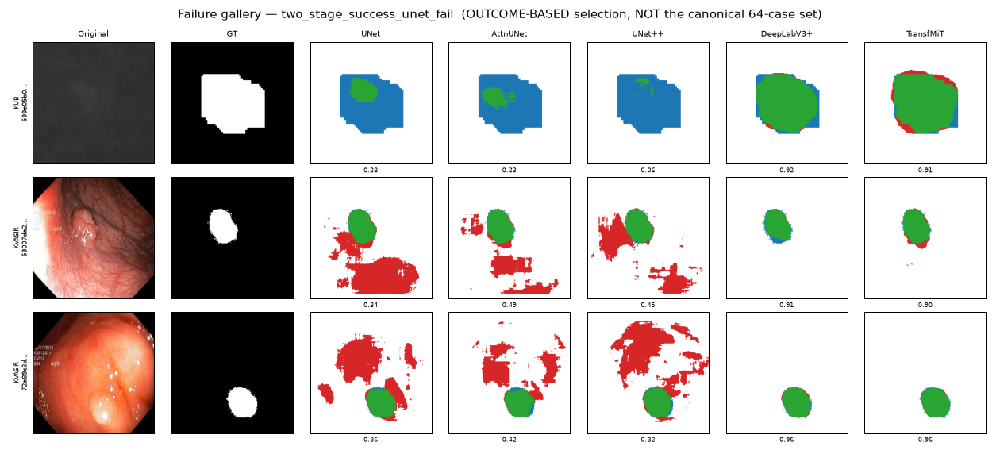

*Figure — Failure gallery — unet_family_success*  
`reports/figures/phase20b_five_model_baselines/failure_cases/gallery_unet_family_success.png`

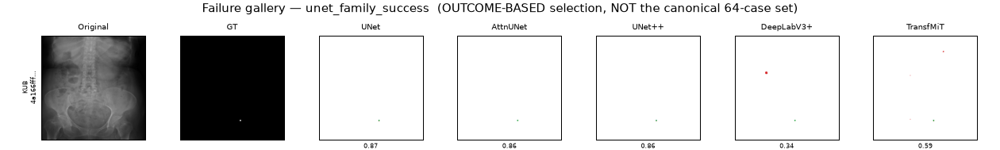

*Figure — Failure gallery — max_disagreement*  
`reports/figures/phase20b_five_model_baselines/failure_cases/gallery_max_disagreement.png`

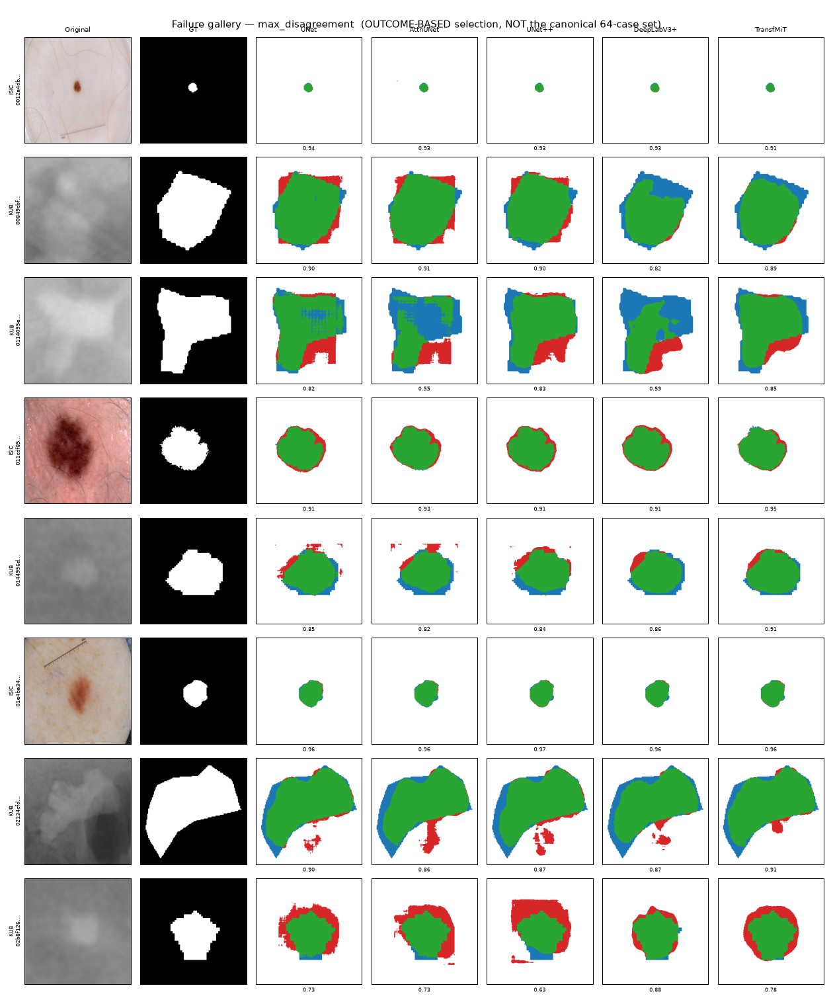

*Figure — Failure gallery — kub_tiny_misses*  
`reports/figures/phase20b_five_model_baselines/failure_cases/gallery_kub_tiny_misses.png`

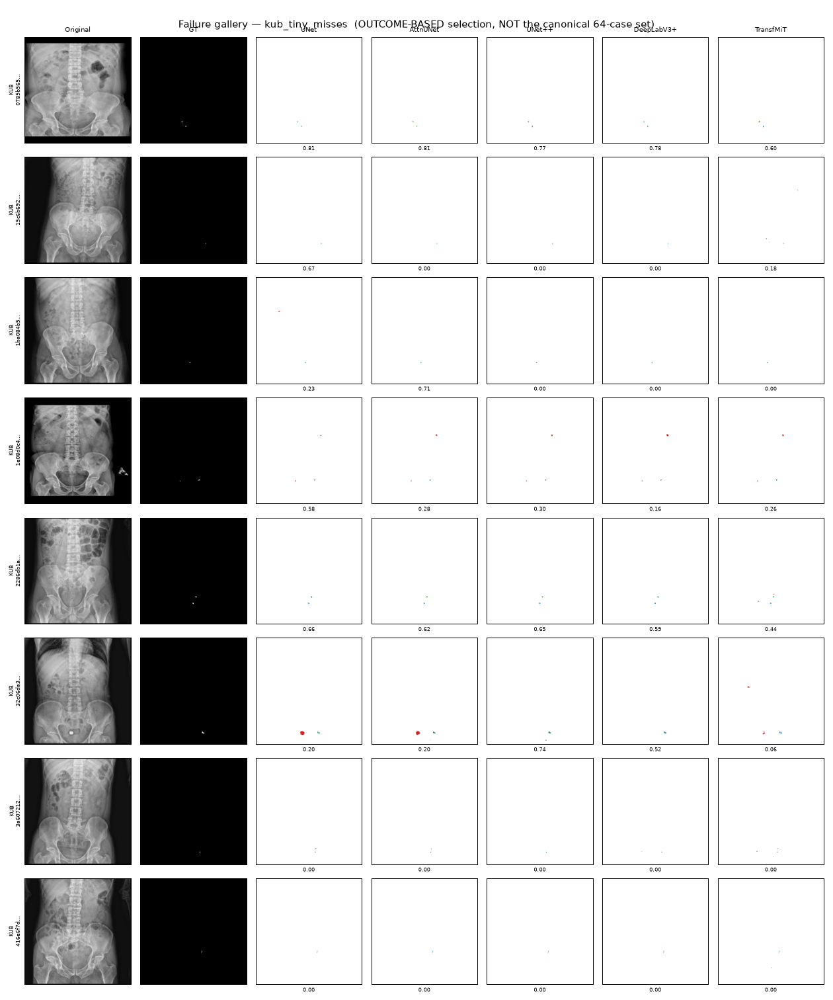

*Figure — Failure gallery — fp_heavy*  
`reports/figures/phase20b_five_model_baselines/failure_cases/gallery_fp_heavy.png`

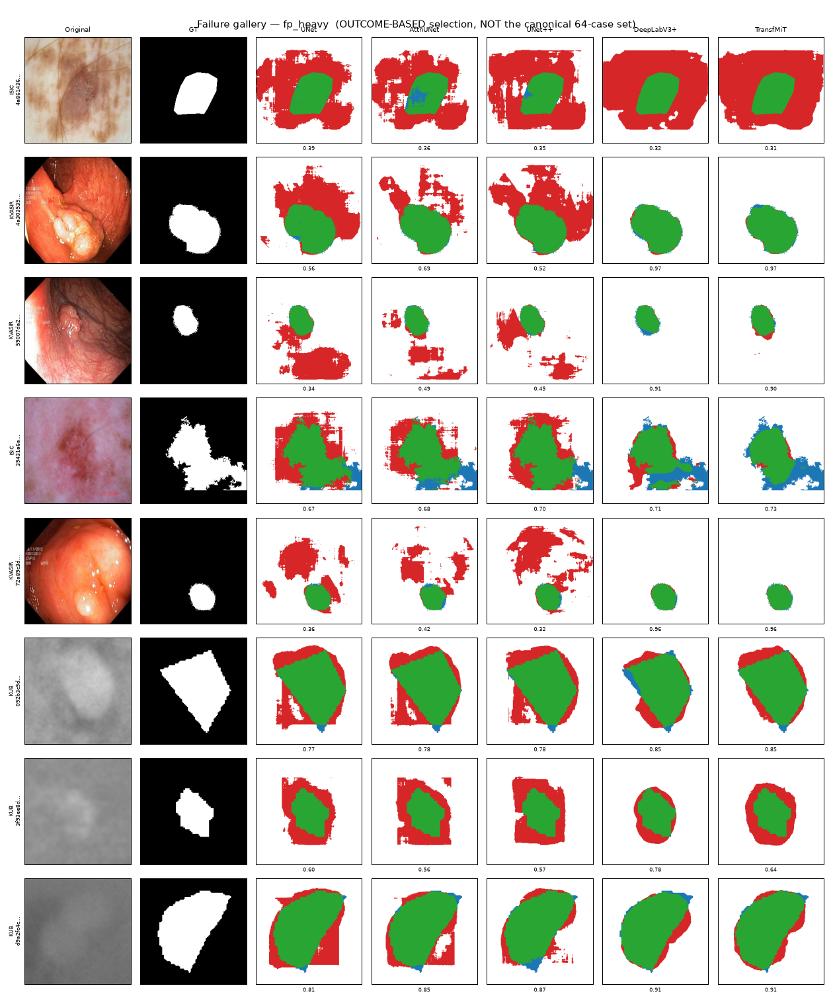

*Figure — Failure gallery — fn_heavy*  
`reports/figures/phase20b_five_model_baselines/failure_cases/gallery_fn_heavy.png`

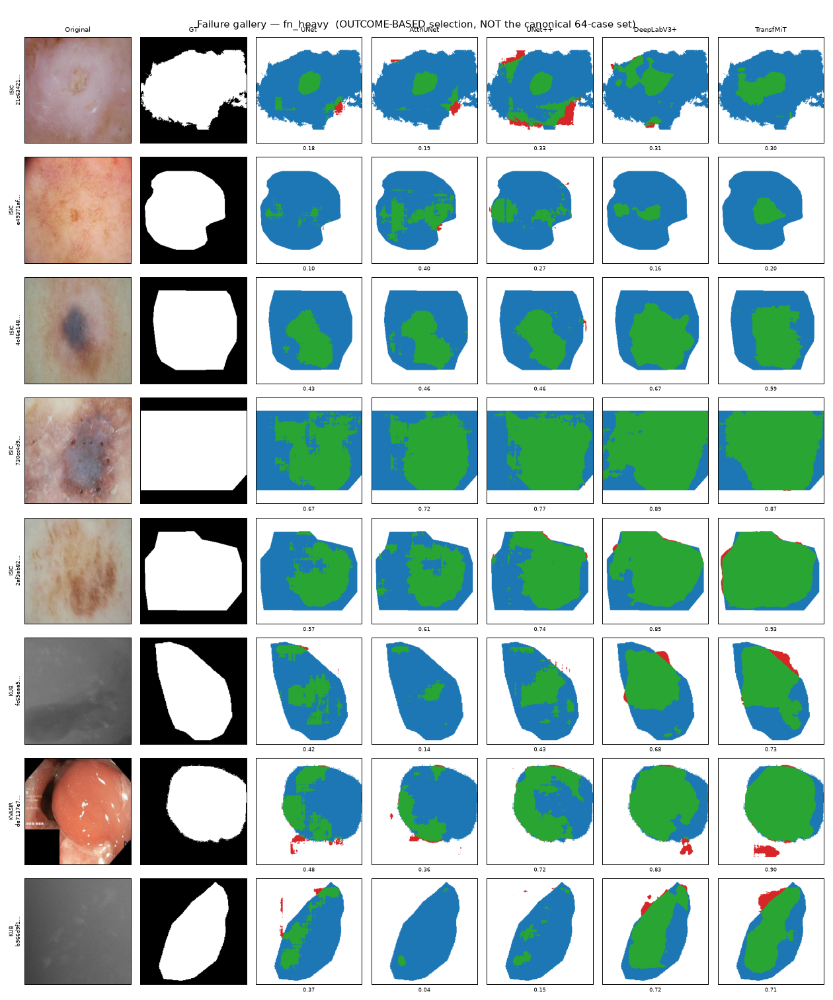

In [31]:
rules = F.figure_inventory()
rules = rules[rules["figure_id"] == "failure_gallery_selection_rules"]
if len(rules):
    display(Markdown("**Selection rules (first cases per rule):**  \n`" +
                     rules.iloc[0]["status"] + "`"))
show_figs(["failure_gallery_all_models_fail", "failure_gallery_two_stage_success_unet_fail",
           "failure_gallery_unet_family_success", "failure_gallery_max_disagreement",
           "failure_gallery_kub_tiny_misses", "failure_gallery_fp_heavy",
           "failure_gallery_fn_heavy"], width=1400)

## 33 · Efficiency / complexity analysis  ·  34 · Pareto analysis  ·  35 · Radar (supplemental)

Parameters, checkpoint size, training cost and (where persisted) inference cost. `NA` is
used where a quantity was never measured — nothing is re-benchmarked to fill a gap.

,model_key,model,phase,params,checkpoint_bytes,best_epoch,final_epoch,total_training_seconds,mean_epoch_seconds,inference_seconds_808,inference_ms_per_sample,peak_gpu_memory_mb
0,unet,U-Net,20B,"7,763,041","93,260,632",74,89,"8,134.1",451.3,112.8,139.60,nan
1,attention_unet,Attention U-Net,20B,"7,851,285","94,362,208",64,79,"36,053.2",456.1,101.9,126.11,nan
2,unetpp,U-Net++,20A,"9,159,681","110,061,300",55,70,"43,001.3",614.1,123.0,152.23,nan
3,deeplabv3plus,DeepLabV3+,20B,"40,347,041","484,632,532",57,72,"32,450.8",449.5,92.5,114.48,nan
4,transformer_mit_unet,Transformer/MiT-style U-Net,20B,"16,347,777","196,401,403",74,89,"42,331.8",475.1,100.2,124.01,nan


*Figure — Parameters vs macro-domain Dice*  
`reports/figures/phase20b_five_model_baselines/efficiency/params_vs_macro.png`

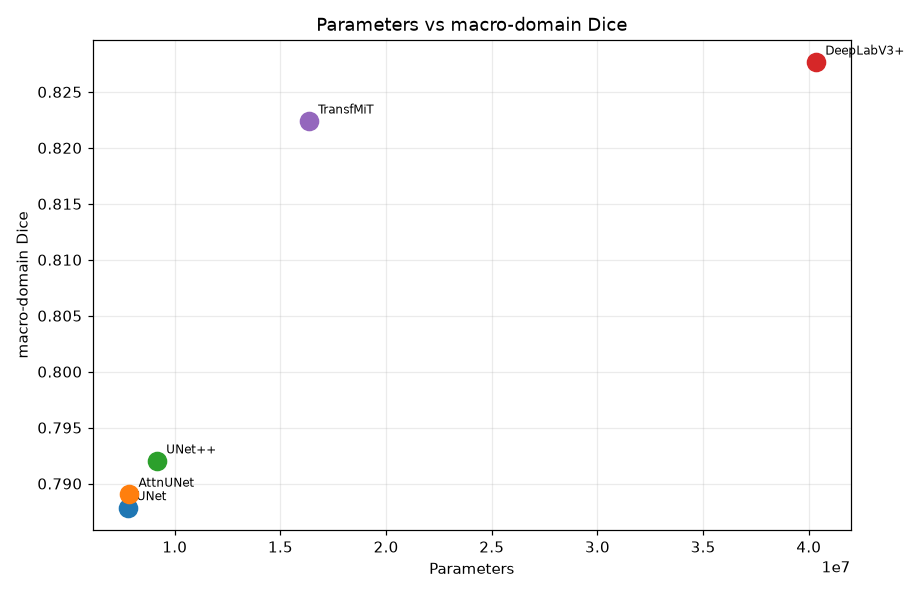

*Figure — Parameters vs KUB Dice*  
`reports/figures/phase20b_five_model_baselines/efficiency/params_vs_kub.png`

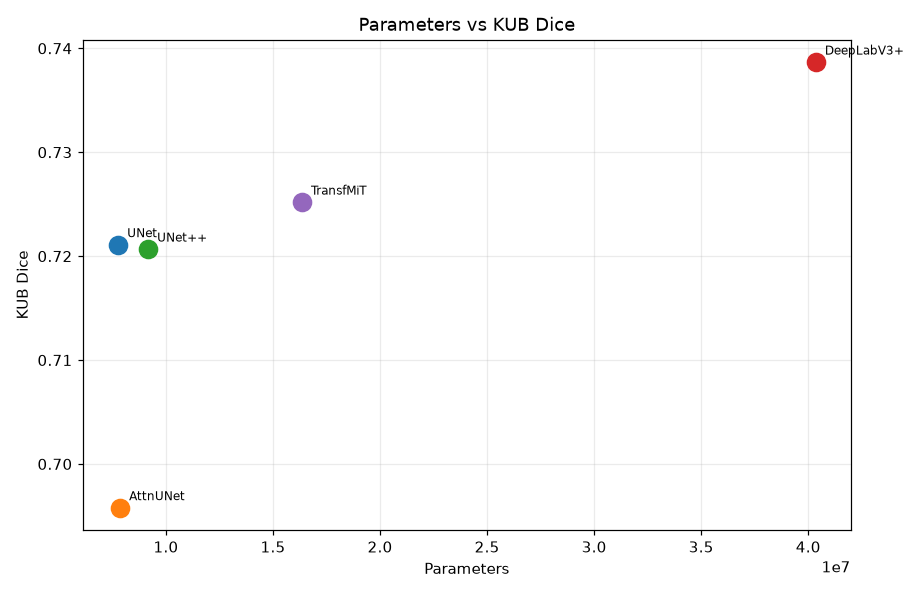

*Figure — Parameters vs KUB TINY Dice*  
`reports/figures/phase20b_five_model_baselines/efficiency/params_vs_tiny.png`

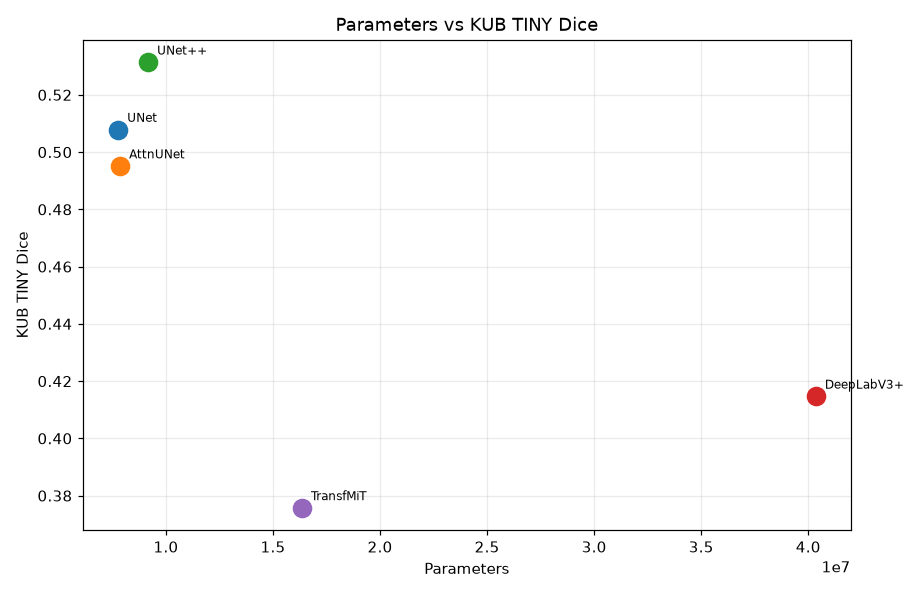

*Figure — Total training time (s) vs macro-domain Dice*  
`reports/figures/phase20b_five_model_baselines/efficiency/time_vs_macro.png`

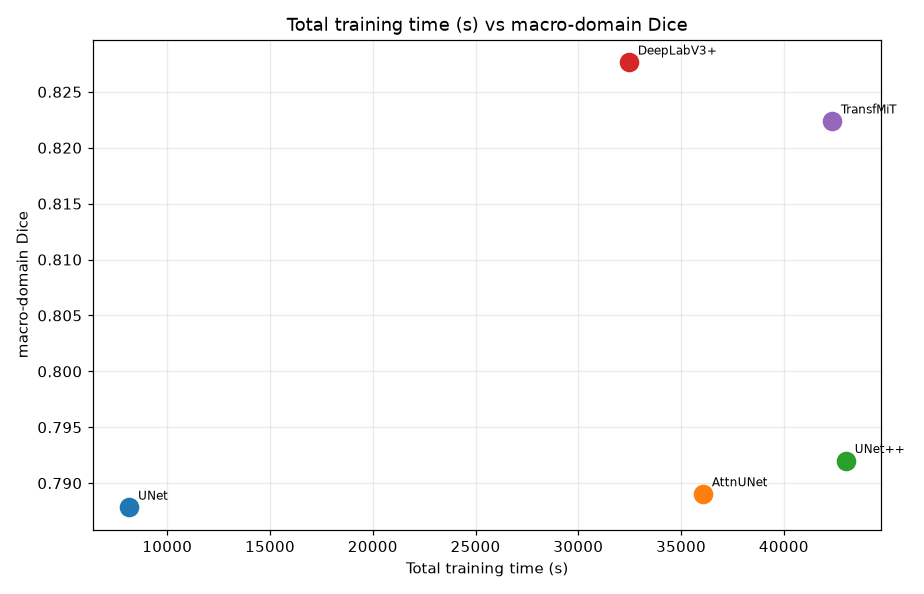

*Figure — Inference ms / sample (808 VAL) vs macro-domain Dice*  
`reports/figures/phase20b_five_model_baselines/efficiency/inference_vs_macro.png`

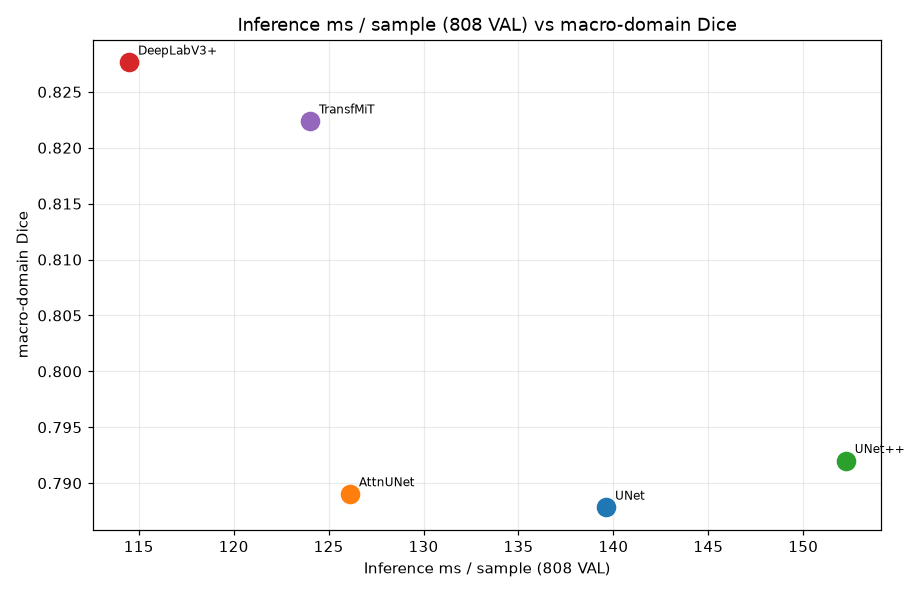

In [32]:
eff = R.efficiency_table()
display(sty(eff, "p20b_eff",
            {"params": "{:,}", "checkpoint_bytes": "{:,.0f}", "total_training_seconds": "{:,.1f}",
             "mean_epoch_seconds": "{:,.1f}", "inference_seconds_808": "{:,.1f}",
             "inference_ms_per_sample": "{:,.2f}"}))
show_figs(["efficiency_params_macro", "efficiency_params_kub", "efficiency_params_tiny",
           "efficiency_time_macro", "efficiency_inference_macro"], width=1050)

*Figure — Pareto — macro-domain Dice vs Parameters*  
`reports/figures/phase20b_five_model_baselines/efficiency/pareto_params_macro.png`

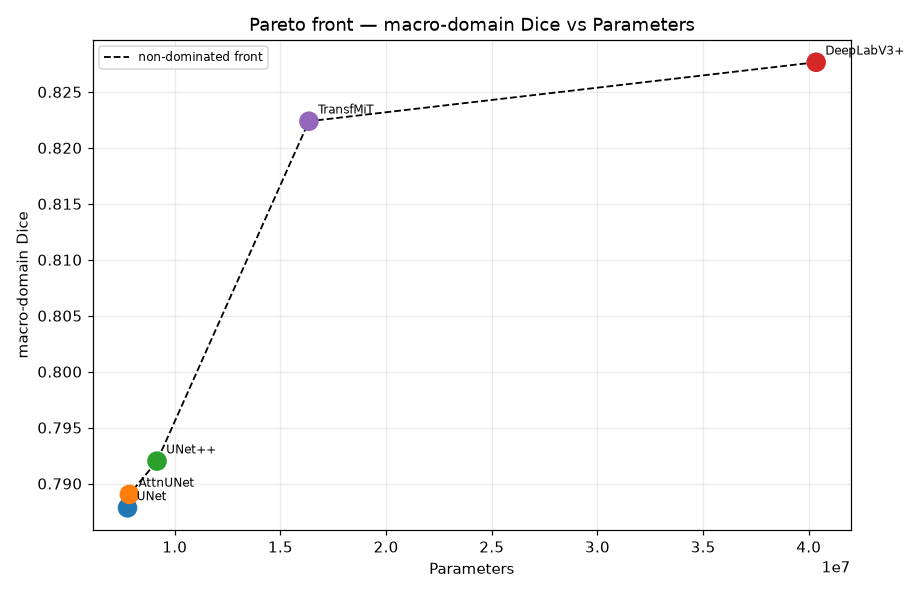

*Figure — Pareto — macro-domain Dice vs Total training time (s)*  
`reports/figures/phase20b_five_model_baselines/efficiency/pareto_time_macro.png`

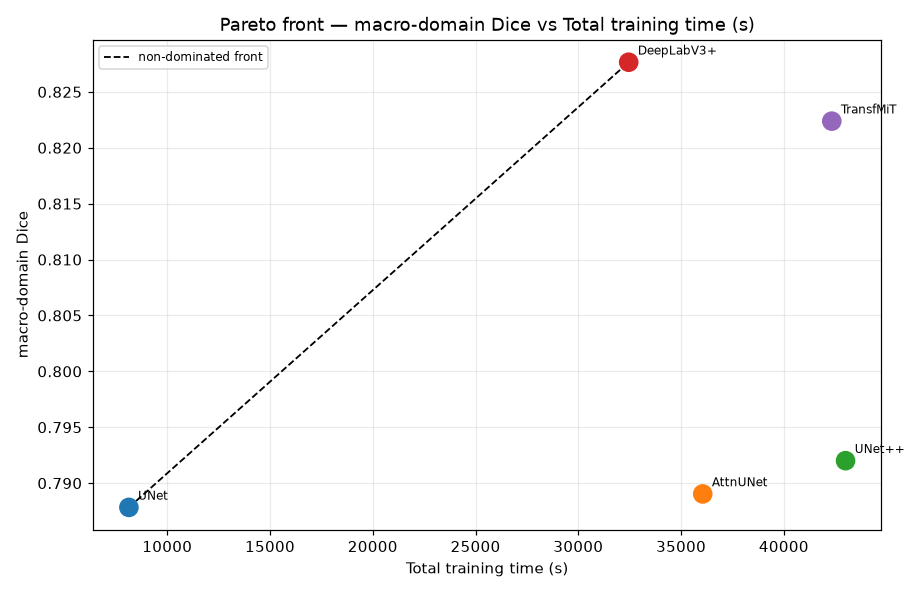

*Figure — Pareto — KUB TINY Dice vs macro-domain Dice*  
`reports/figures/phase20b_five_model_baselines/efficiency/pareto_tiny_macro.png`

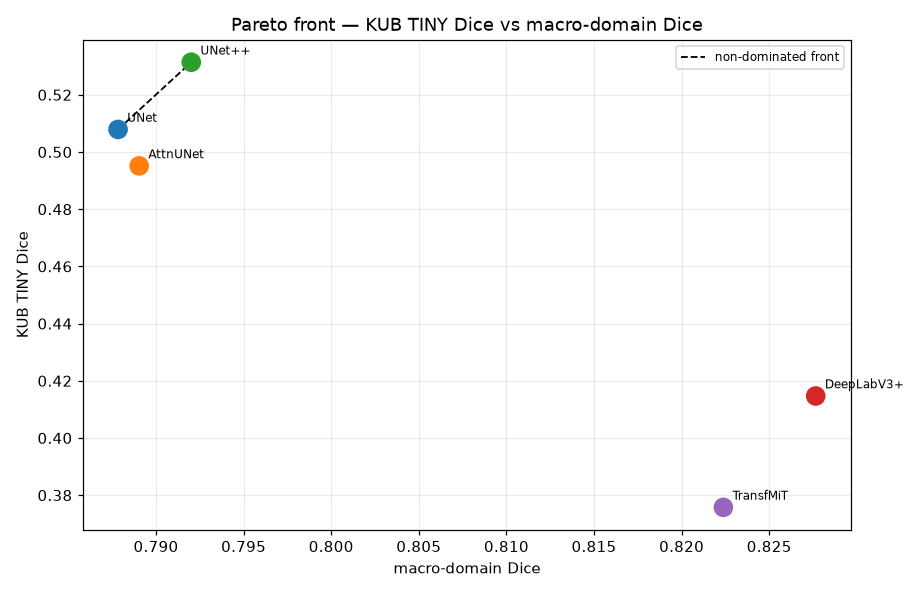

*Figure — Radar / spider plot (supplemental)*  
`reports/figures/phase20b_five_model_baselines/efficiency/radar.png`

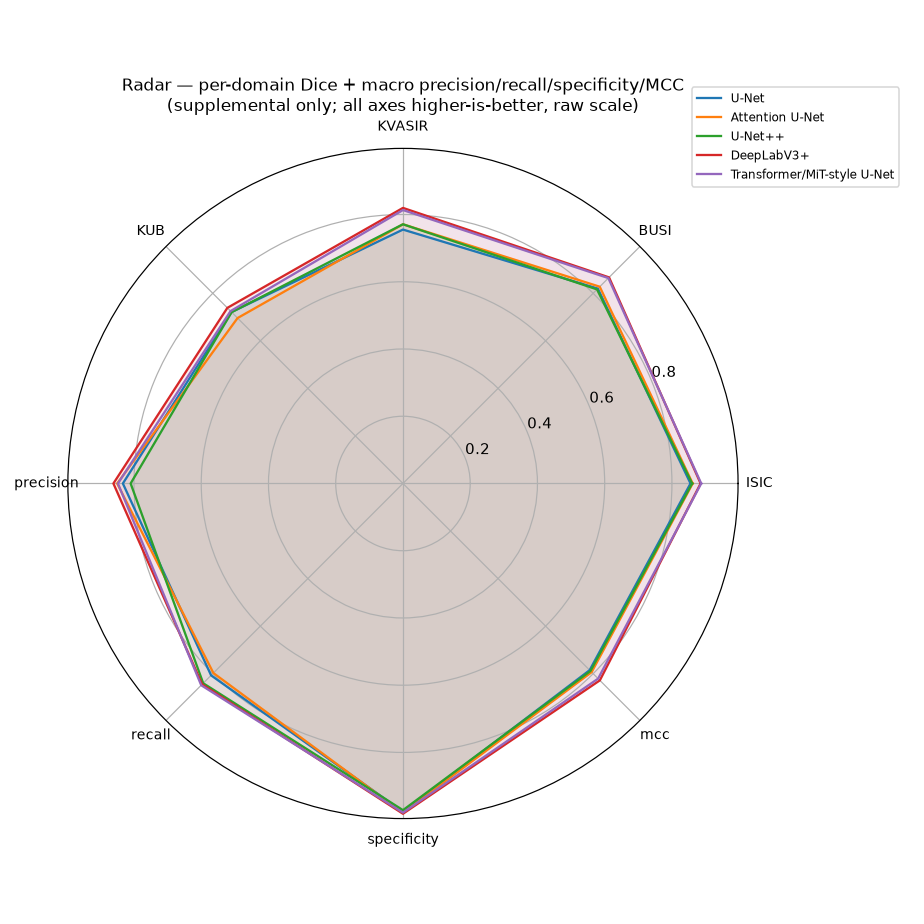

Pareto fronts are **descriptive** — they show trade-offs and do not declare an absolute winner. The radar is supplemental only.

In [33]:
show_figs(["pareto_params_macro", "pareto_time_macro", "pareto_tiny_macro"], width=1050)
show_fig("efficiency_radar", width=1000)
display(Markdown("Pareto fronts are **descriptive** — they show trade-offs and do not declare "
                 "an absolute winner. The radar is supplemental only."))

## 36 · Cross-model agreement / disagreement

,index,U-Net,Attention U-Net,U-Net++,DeepLabV3+,Transformer/MiT-style U-Net
0,U-Net,1.000,0.859,0.806,0.729,0.728
1,Attention U-Net,0.859,1.000,0.834,0.779,0.788
2,U-Net++,0.806,0.834,1.000,0.749,0.735
3,DeepLabV3+,0.729,0.779,0.749,1.000,0.850
4,Transformer/MiT-style U-Net,0.728,0.788,0.735,0.850,1.000


*Figure — Cross-model Dice correlation matrix*  
`reports/figures/phase20b_five_model_baselines/agreement/dice_correlation_matrix.png`

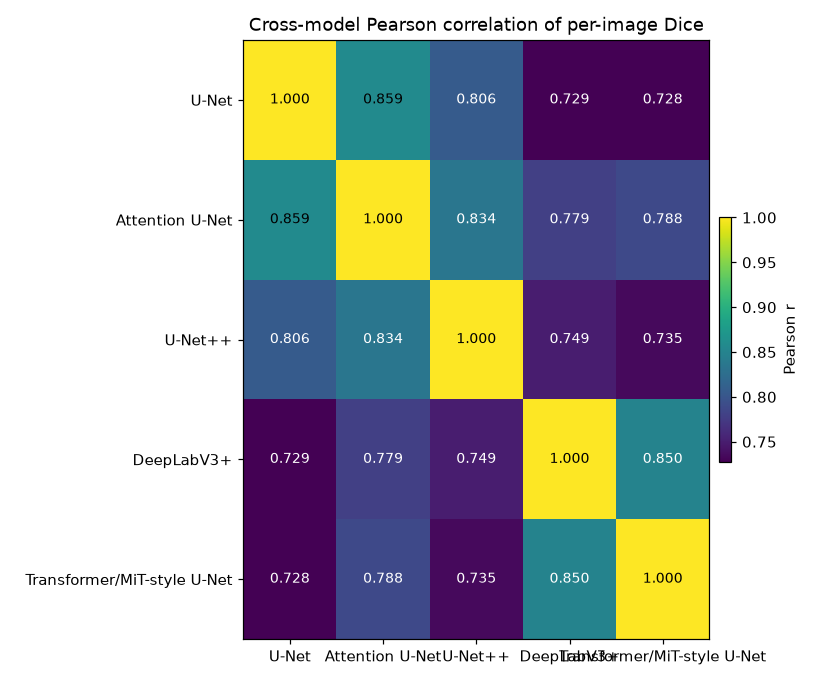

*Figure — Pairwise model Dice scatter grid*  
`reports/figures/phase20b_five_model_baselines/agreement/pairwise_scatter.png`

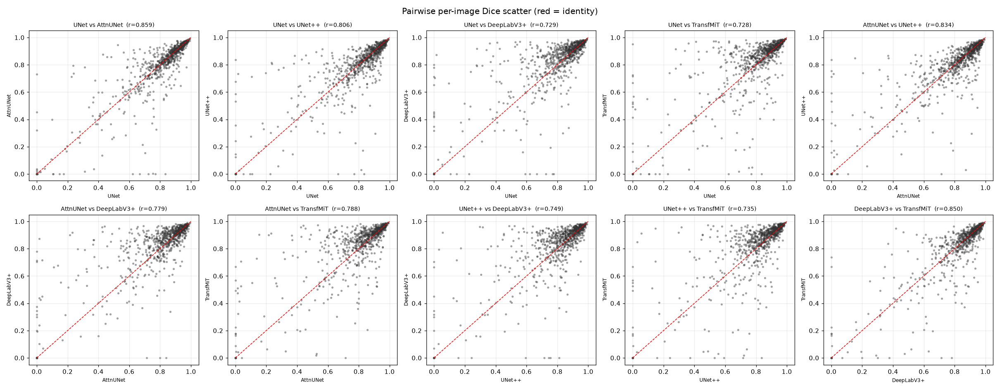

*Figure — Cross-model disagreement magnitude*  
`reports/figures/phase20b_five_model_baselines/agreement/disagreement_magnitude.png`

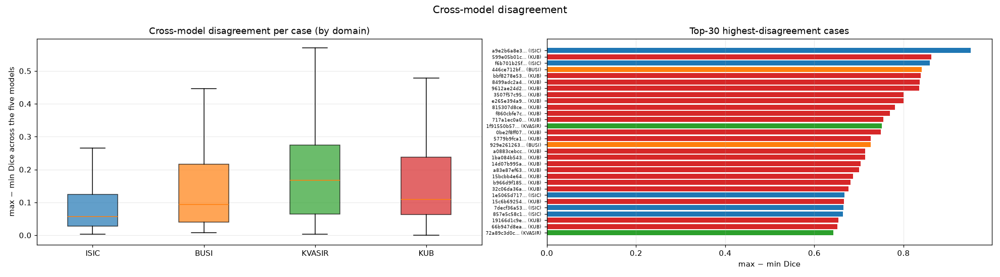

In [34]:
corr = R.cross_model_dice_correlation("dice")
display(sty(corr.reset_index(), "p20b_corr", {c: "{:.3f}" for c in corr.columns}))
show_figs(["agree_corr_matrix", "agree_pairwise_scatter", "agree_disagreement"], width=1400)

## 37 · Qualitative same-case comparison — the frozen 64-case gallery

The **same** 64 deterministically selected VAL cases (16 per domain, prediction-independent,
seed 42) shown for all five models. Error maps: **TP green / FP red / FN blue**. The sample
IDs are byte-identical to the frozen Phase-20A gallery set, so Phase 21 can reuse them.

,dataset,cases
0,BUSI,16
1,ISIC,16
2,KUB,16
3,KVASIR,16


*Figure — Cross-model same-case gallery page 1*  
`reports/figures/phase20b_five_model_baselines/galleries/cross_model_page_01.png`

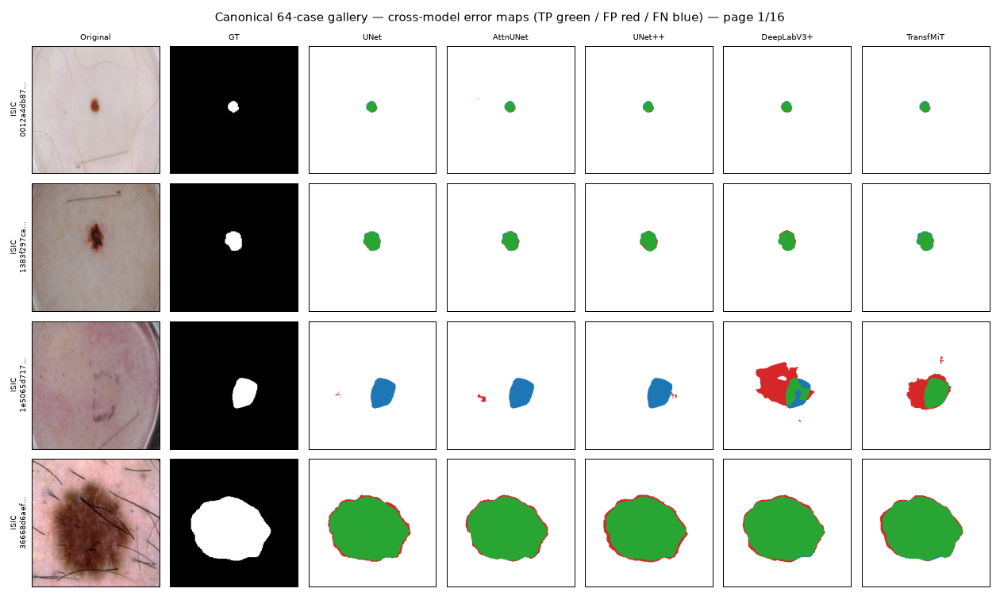

*Figure — Cross-model same-case gallery page 2*  
`reports/figures/phase20b_five_model_baselines/galleries/cross_model_page_02.png`

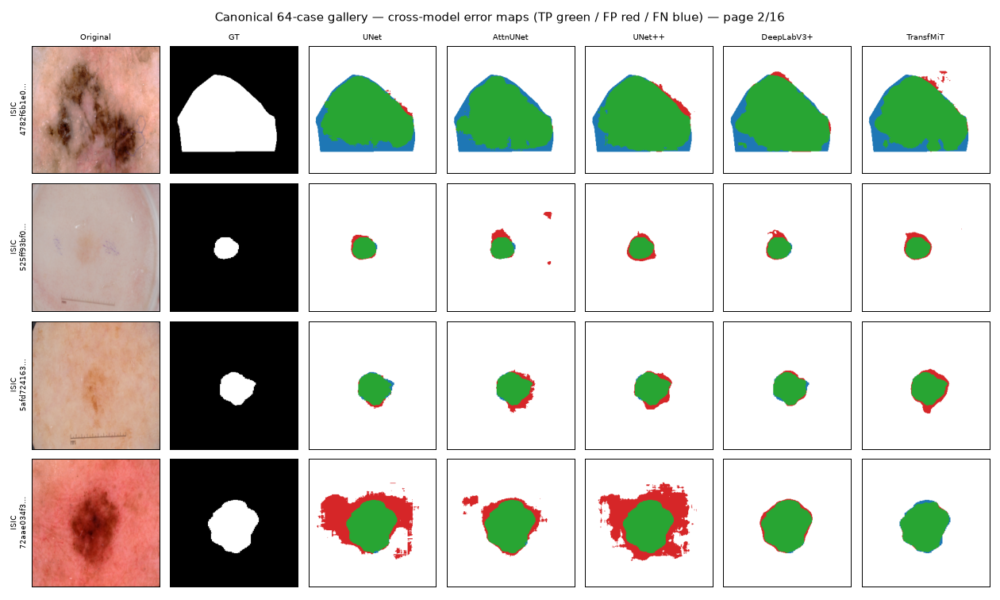

*Figure — Cross-model same-case gallery page 3*  
`reports/figures/phase20b_five_model_baselines/galleries/cross_model_page_03.png`

*Figure — Cross-model same-case gallery page 4*  
`reports/figures/phase20b_five_model_baselines/galleries/cross_model_page_04.png`

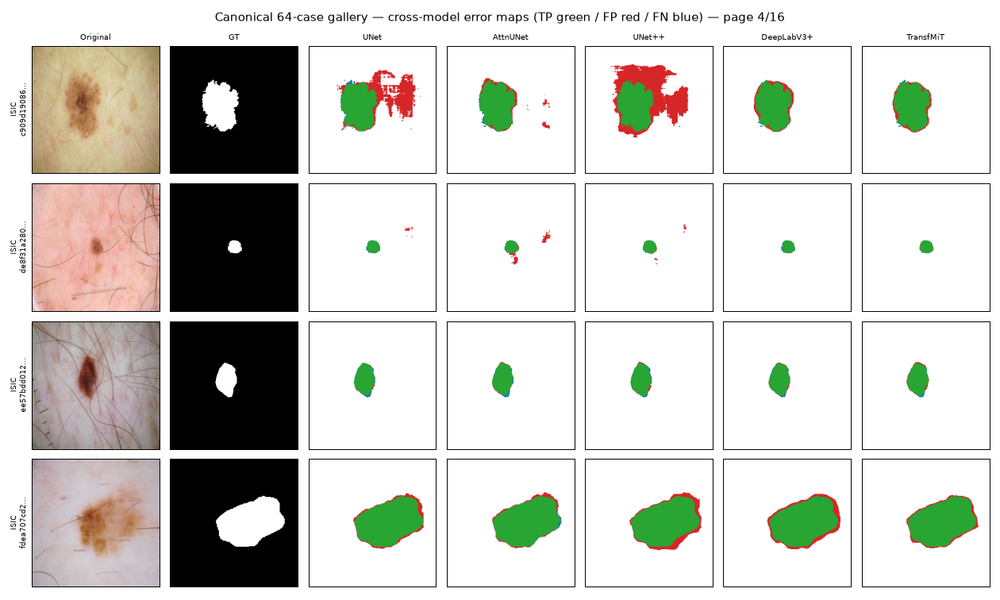

*Figure — Cross-model same-case gallery page 5*  
`reports/figures/phase20b_five_model_baselines/galleries/cross_model_page_05.png`

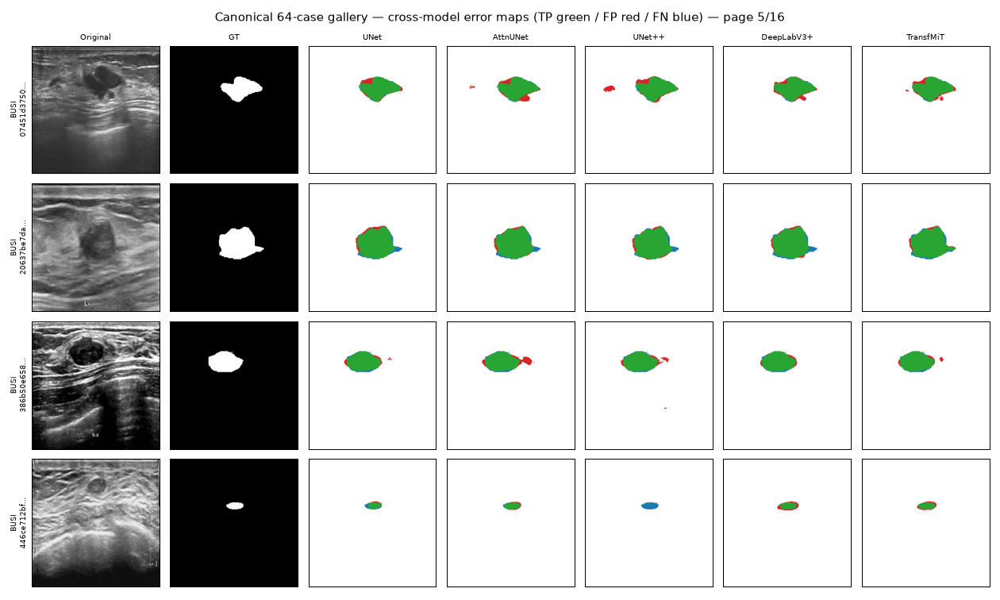

*Figure — Cross-model same-case gallery page 6*  
`reports/figures/phase20b_five_model_baselines/galleries/cross_model_page_06.png`

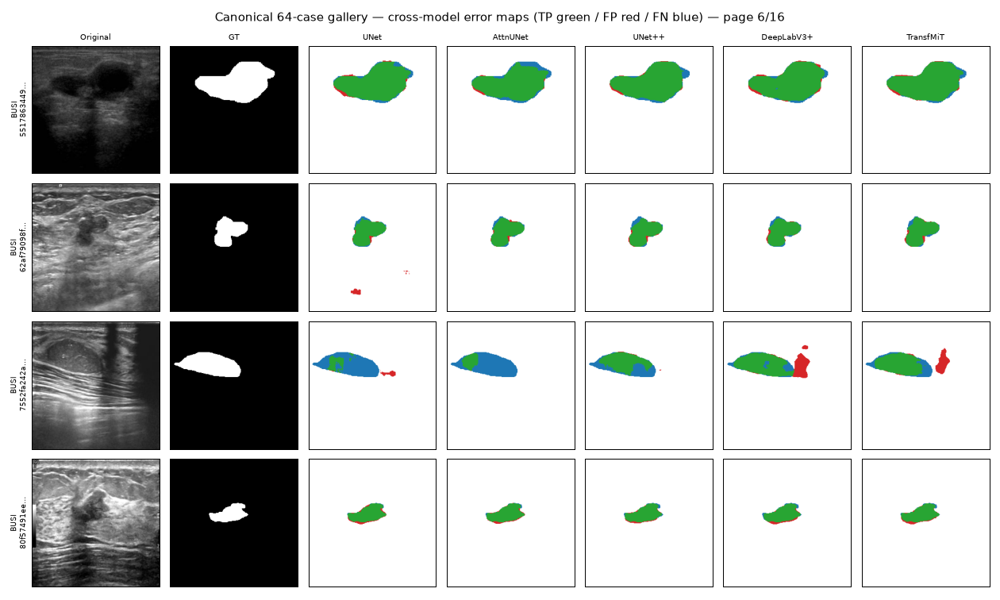

*Figure — Cross-model same-case gallery page 7*  
`reports/figures/phase20b_five_model_baselines/galleries/cross_model_page_07.png`

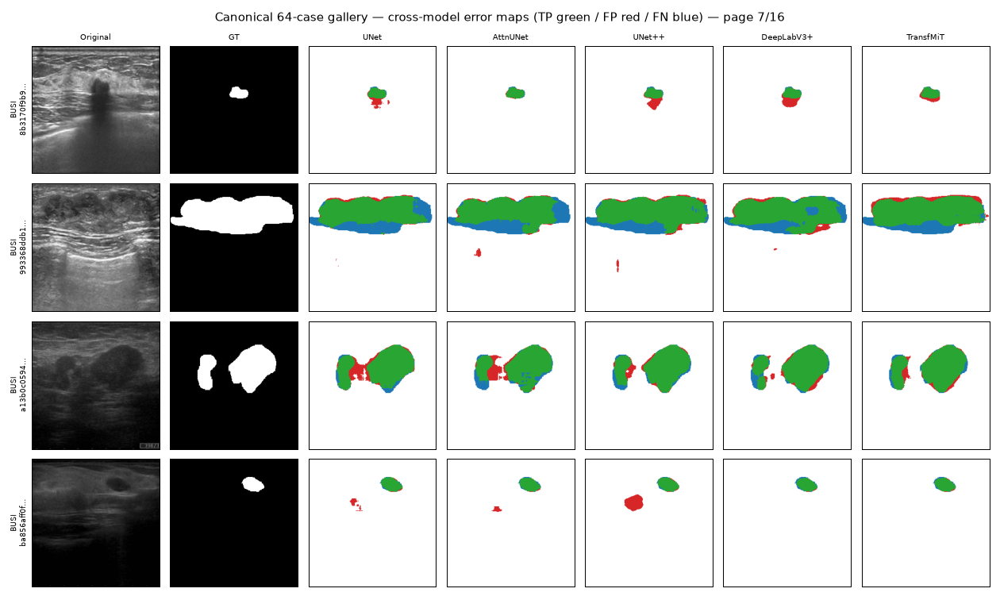

*Figure — Cross-model same-case gallery page 8*  
`reports/figures/phase20b_five_model_baselines/galleries/cross_model_page_08.png`

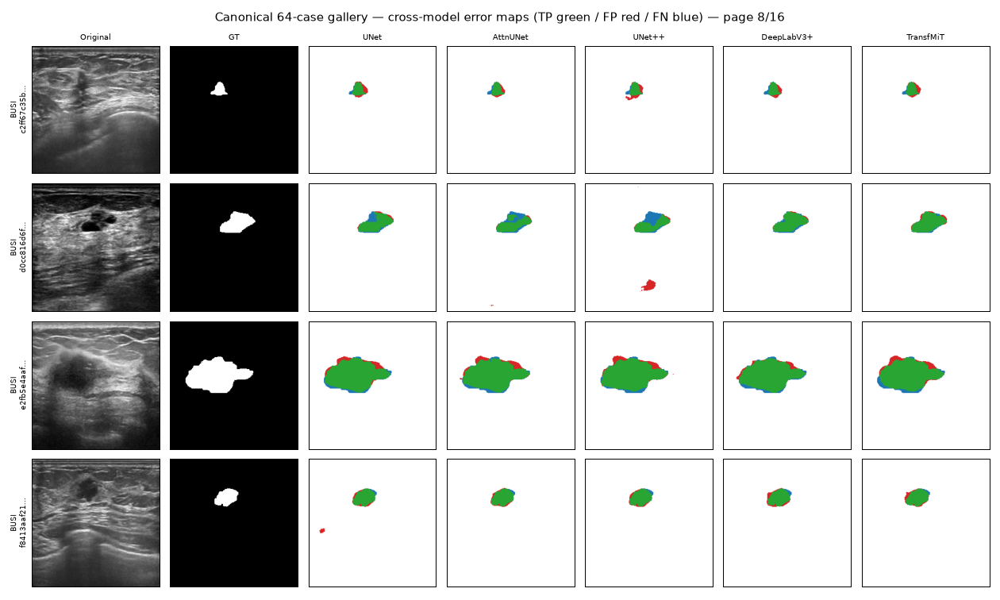

*Figure — Cross-model same-case gallery page 9*  
`reports/figures/phase20b_five_model_baselines/galleries/cross_model_page_09.png`

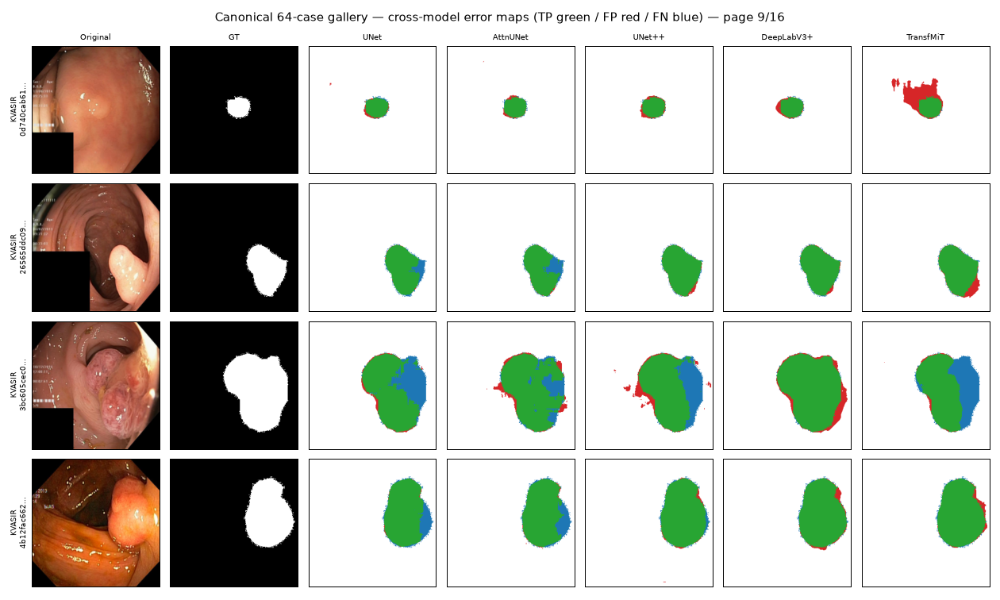

*Figure — Cross-model same-case gallery page 10*  
`reports/figures/phase20b_five_model_baselines/galleries/cross_model_page_10.png`

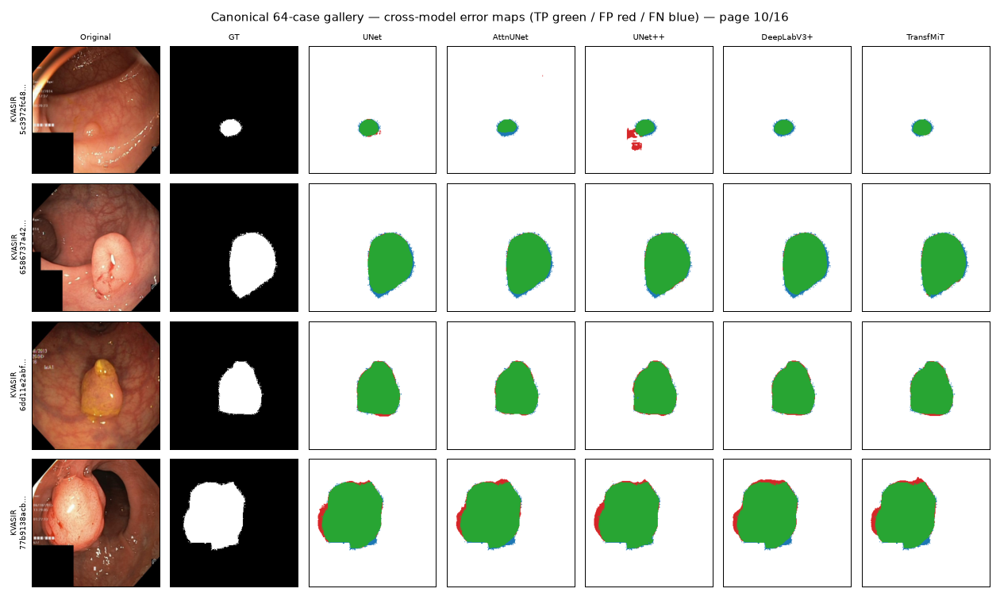

*Figure — Cross-model same-case gallery page 11*  
`reports/figures/phase20b_five_model_baselines/galleries/cross_model_page_11.png`

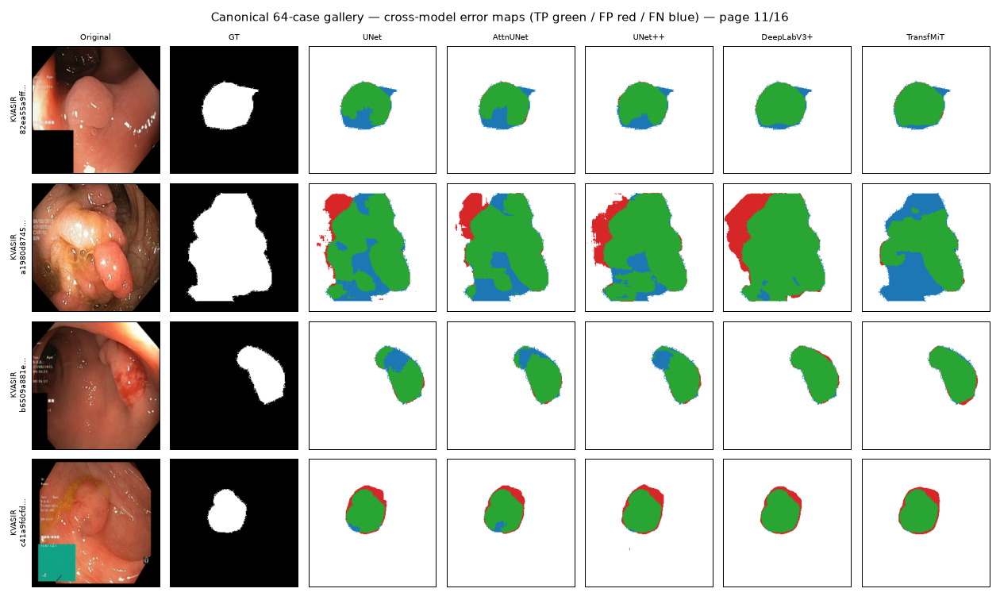

*Figure — Cross-model same-case gallery page 12*  
`reports/figures/phase20b_five_model_baselines/galleries/cross_model_page_12.png`

*Figure — Cross-model same-case gallery page 13*  
`reports/figures/phase20b_five_model_baselines/galleries/cross_model_page_13.png`

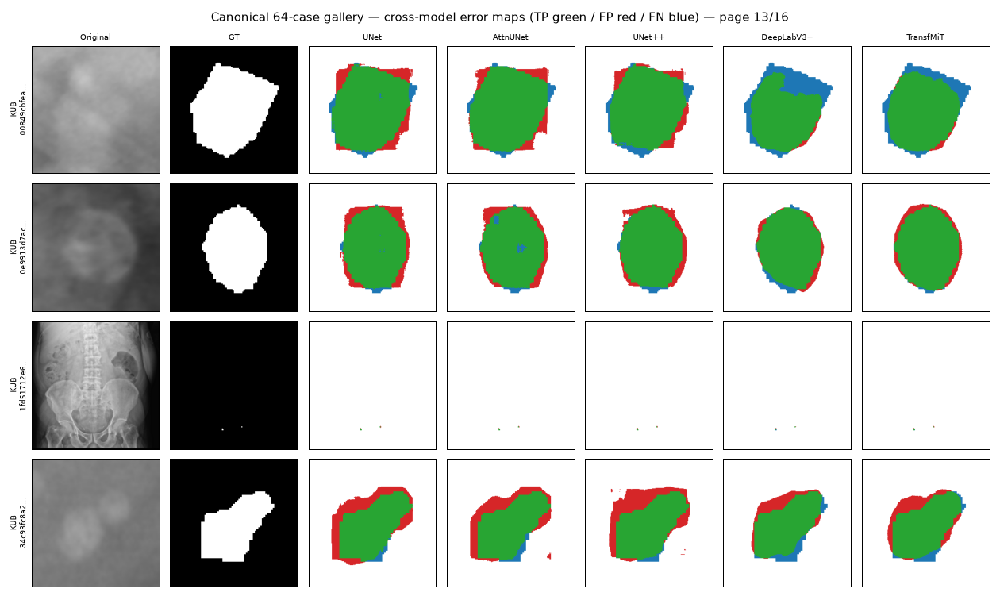

*Figure — Cross-model same-case gallery page 14*  
`reports/figures/phase20b_five_model_baselines/galleries/cross_model_page_14.png`

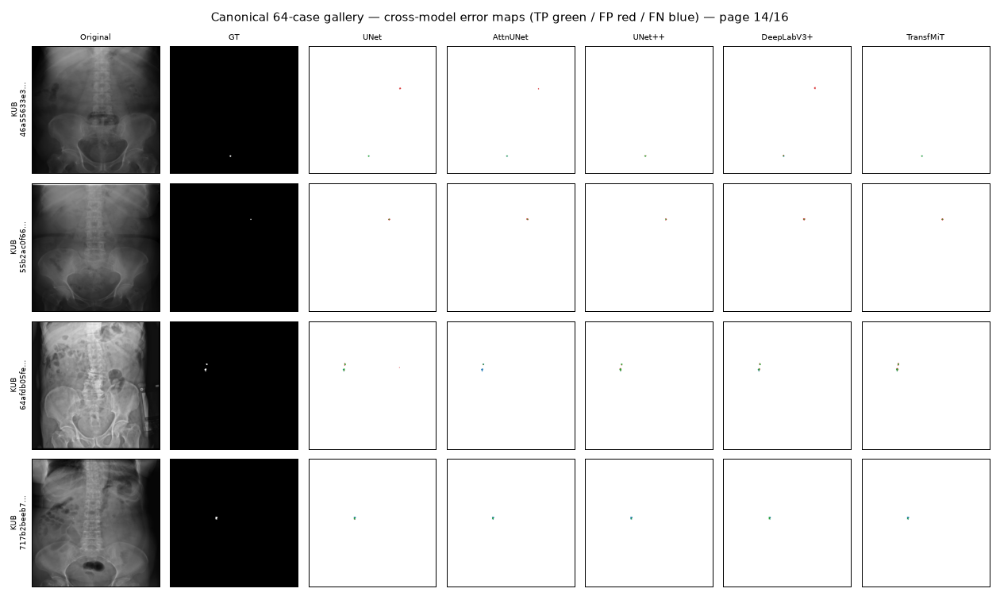

*Figure — Cross-model same-case gallery page 15*  
`reports/figures/phase20b_five_model_baselines/galleries/cross_model_page_15.png`

*Figure — Cross-model same-case gallery page 16*  
`reports/figures/phase20b_five_model_baselines/galleries/cross_model_page_16.png`

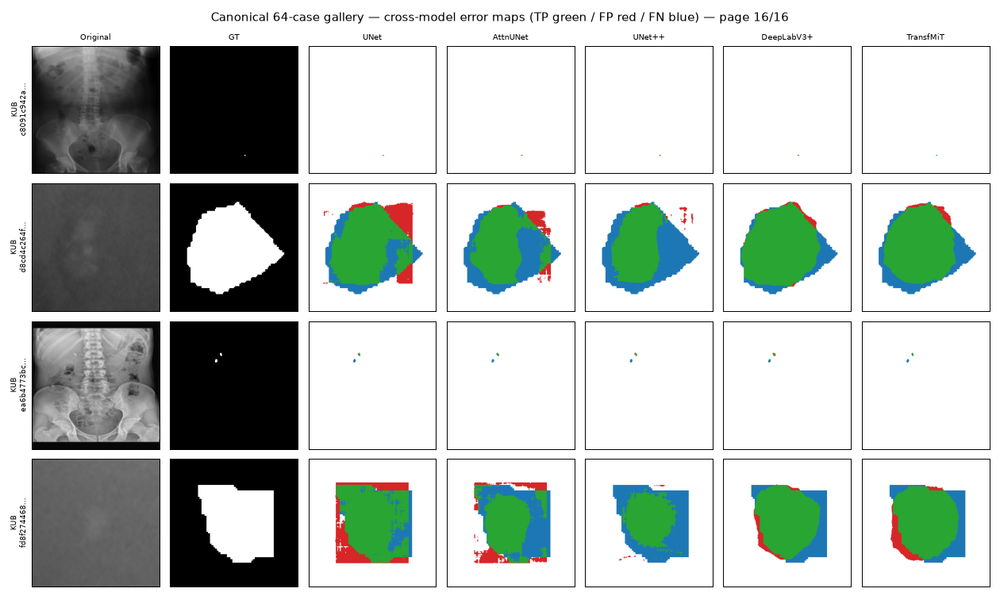

In [35]:
gal = R.load_gallery()
display(sty(gal.groupby("dataset").size().reset_index(name="cases"), "p20b_gal"))
assert len(gal) == 64 and freeze["gallery_ids_match_phase20a_frozen_set"]
show_figs([f"gallery_cross_{i:02d}" for i in range(1, 17)], width=1500)

## 38 · Detailed per-model prediction evidence

Per model × dataset × 16 cases, with panels: Original · GT · GT overlay · probability ·
binary prediction · TP/FP/FN error map · prediction overlay · GT contour. The full set is
**5 models × 4 datasets × 16 cases = 320 cases**; all pages are saved to disk and listed in
the figure inventory. One representative page per model/dataset is embedded here.

detailed gallery pages on disk: 40


,figure_id,saved_path,embedded_in_notebook
0,gallery_detailed_unet_ISIC_1,reports/figures/phase20b_five_model_baselines/galleries/detailed_unet_ISIC_p1.png,True
1,gallery_detailed_unet_ISIC_2,reports/figures/phase20b_five_model_baselines/galleries/detailed_unet_ISIC_p2.png,False
2,gallery_detailed_unet_BUSI_1,reports/figures/phase20b_five_model_baselines/galleries/detailed_unet_BUSI_p1.png,False
3,gallery_detailed_unet_BUSI_2,reports/figures/phase20b_five_model_baselines/galleries/detailed_unet_BUSI_p2.png,False
4,gallery_detailed_unet_KVASIR_1,reports/figures/phase20b_five_model_baselines/galleries/detailed_unet_KVASIR_p1.png,False
5,gallery_detailed_unet_KVASIR_2,reports/figures/phase20b_five_model_baselines/galleries/detailed_unet_KVASIR_p2.png,False
6,gallery_detailed_unet_KUB_1,reports/figures/phase20b_five_model_baselines/galleries/detailed_unet_KUB_p1.png,False
7,gallery_detailed_unet_KUB_2,reports/figures/phase20b_five_model_baselines/galleries/detailed_unet_KUB_p2.png,False
8,gallery_detailed_attention_unet_ISIC_1,reports/figures/phase20b_five_model_baselines/galleries/detailed_attention_unet_ISIC_p1.png,True
9,gallery_detailed_attention_unet_ISIC_2,reports/figures/phase20b_five_model_baselines/galleries/detailed_attention_unet_ISIC_p2.png,False


*Figure — U-Net ISIC detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_unet_ISIC_p1.png`

*Figure — U-Net BUSI detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_unet_BUSI_p1.png`

*Figure — U-Net KVASIR detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_unet_KVASIR_p1.png`

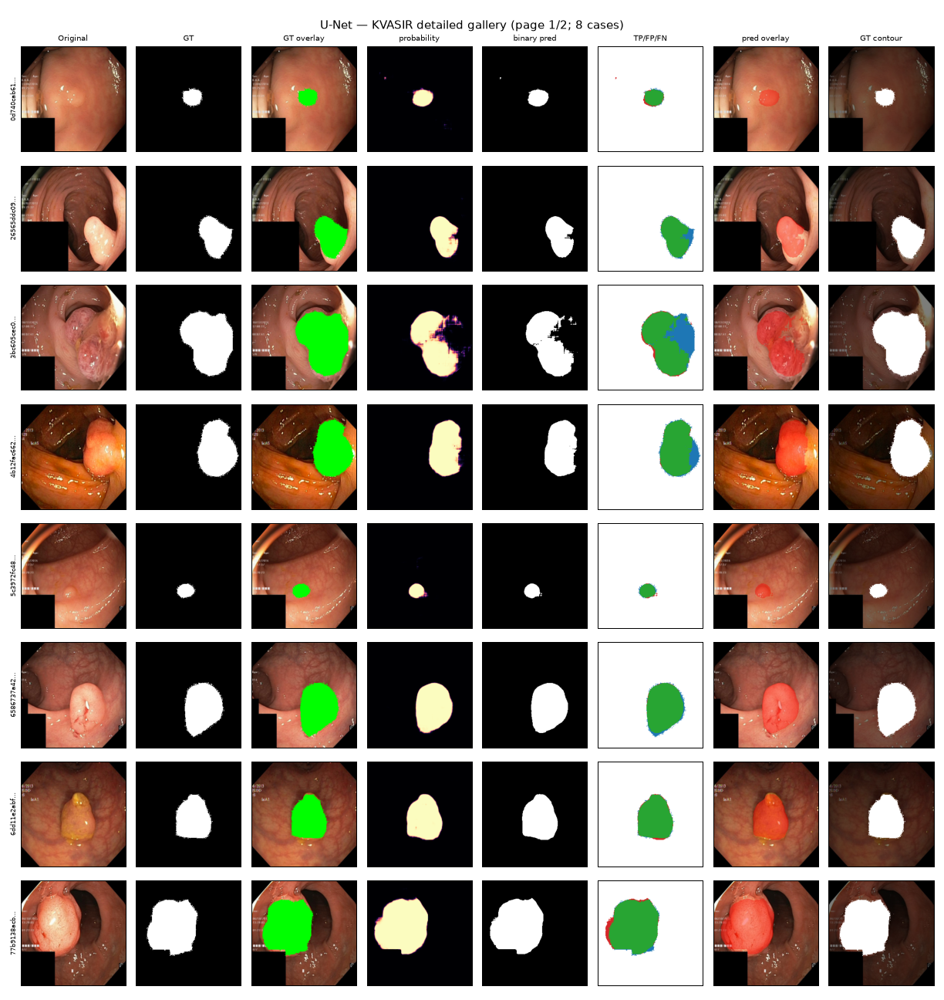

*Figure — U-Net KUB detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_unet_KUB_p1.png`

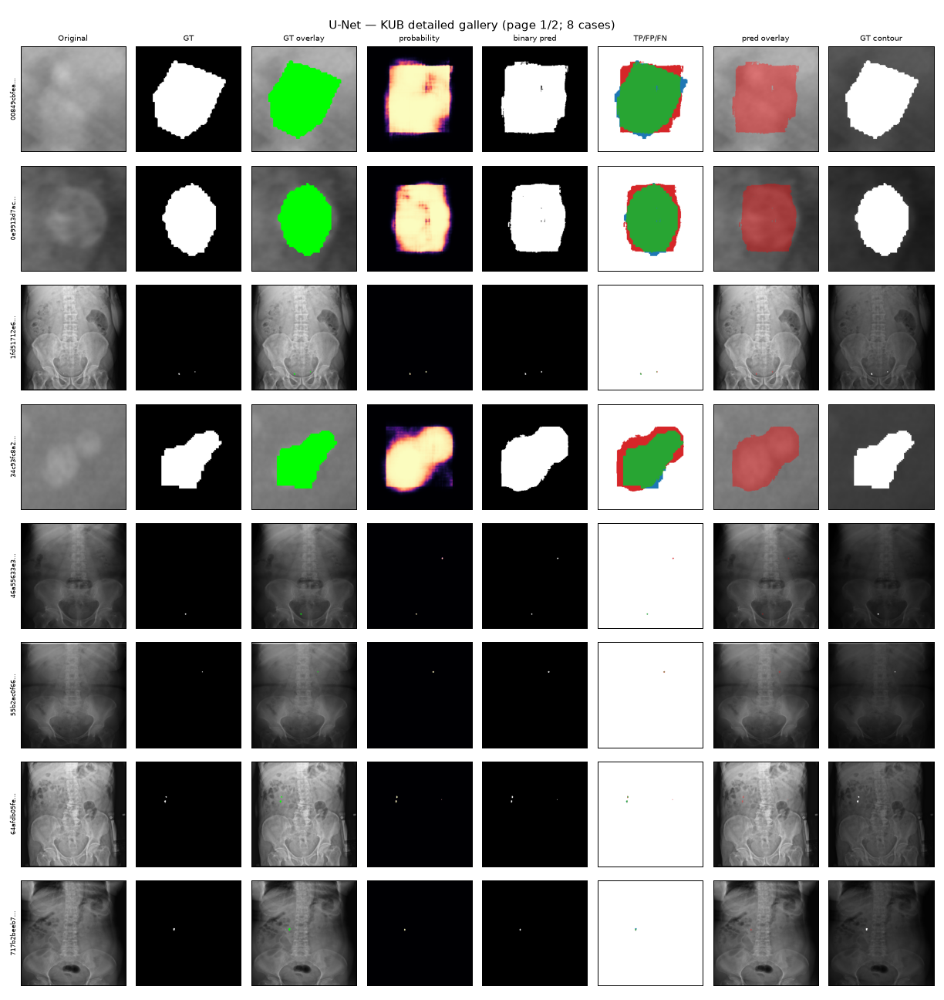

*Figure — Attention U-Net ISIC detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_attention_unet_ISIC_p1.png`

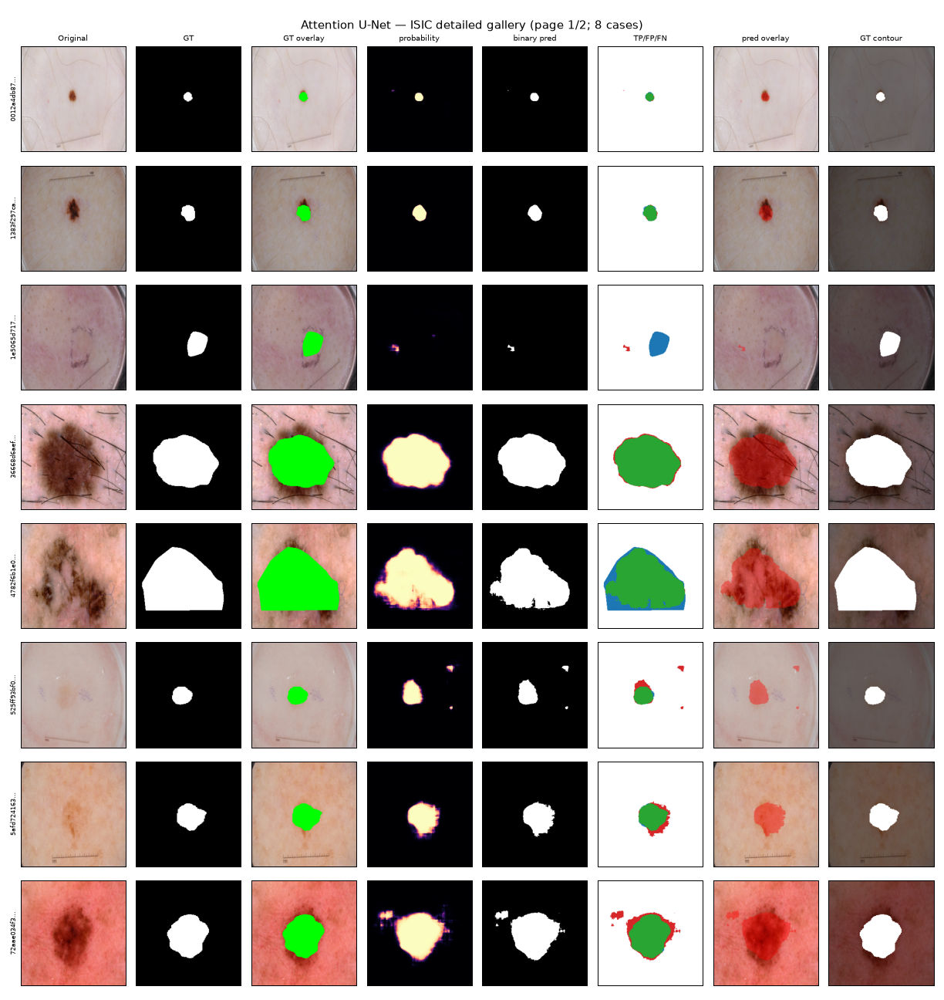

*Figure — Attention U-Net BUSI detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_attention_unet_BUSI_p1.png`

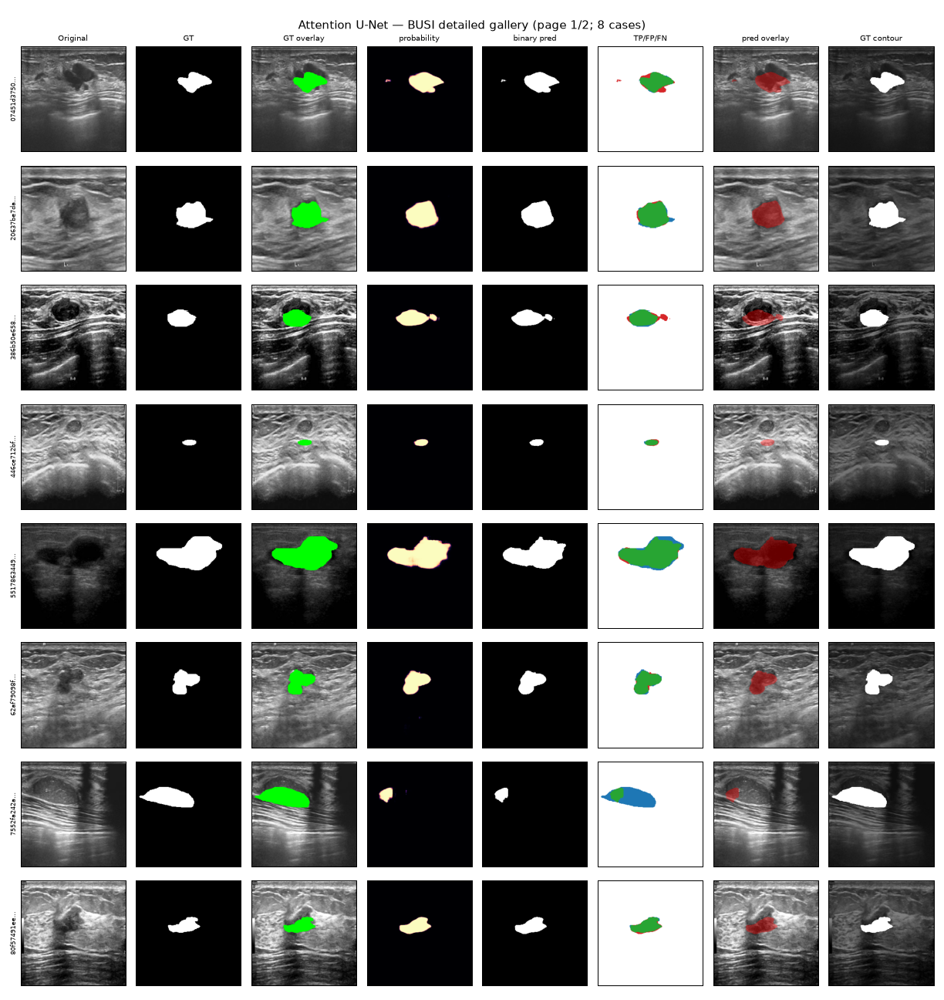

*Figure — Attention U-Net KVASIR detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_attention_unet_KVASIR_p1.png`

*Figure — Attention U-Net KUB detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_attention_unet_KUB_p1.png`

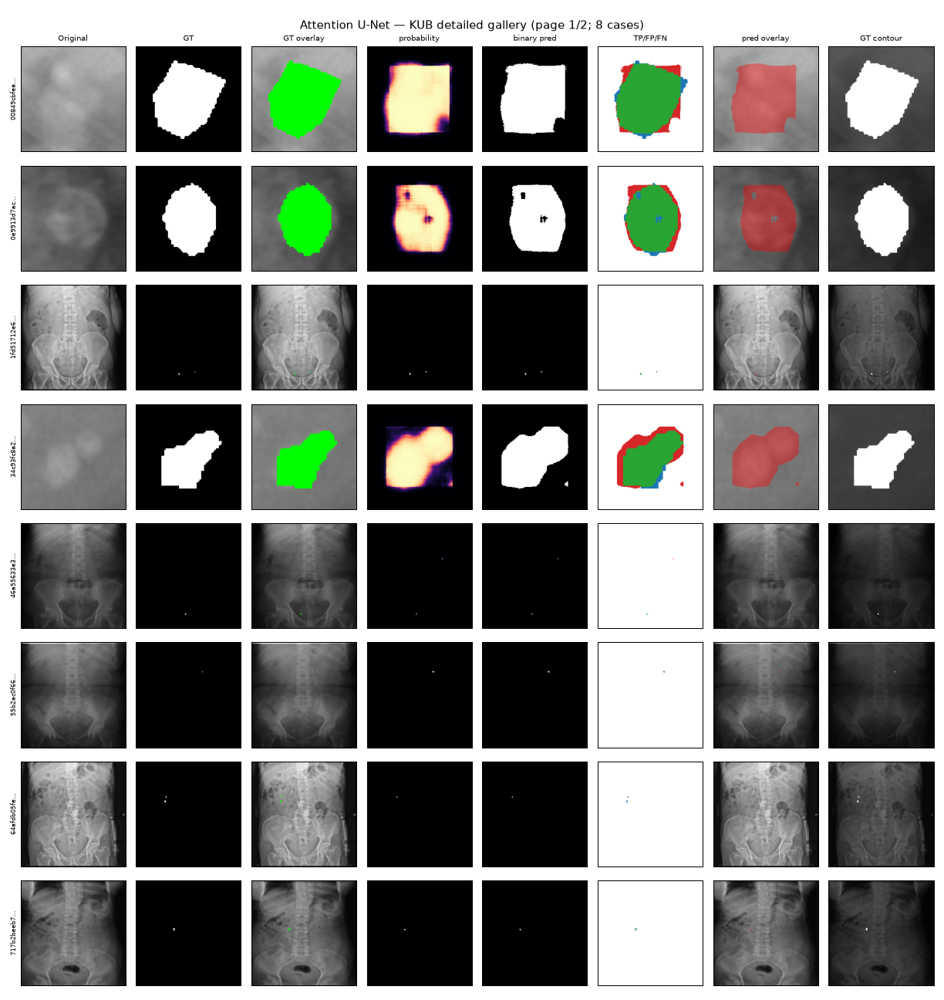

*Figure — U-Net++ ISIC detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_unetpp_ISIC_p1.png`

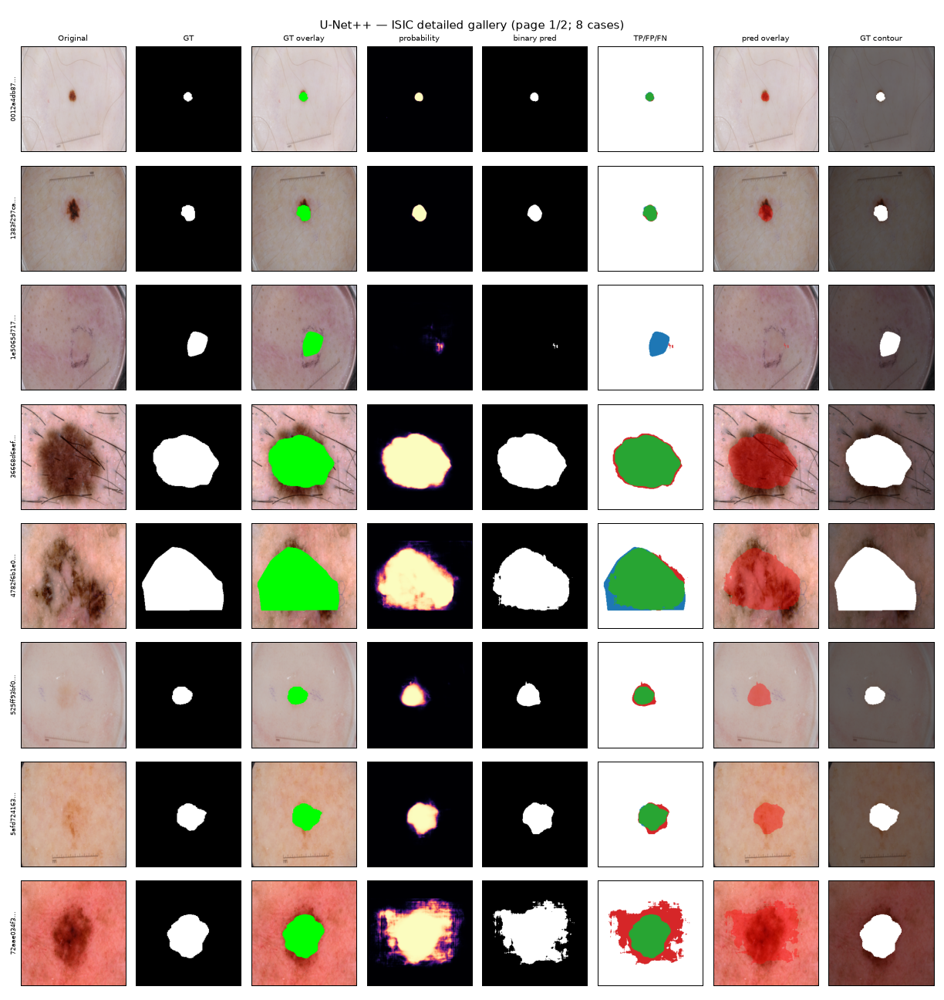

*Figure — U-Net++ BUSI detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_unetpp_BUSI_p1.png`

*Figure — U-Net++ KVASIR detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_unetpp_KVASIR_p1.png`

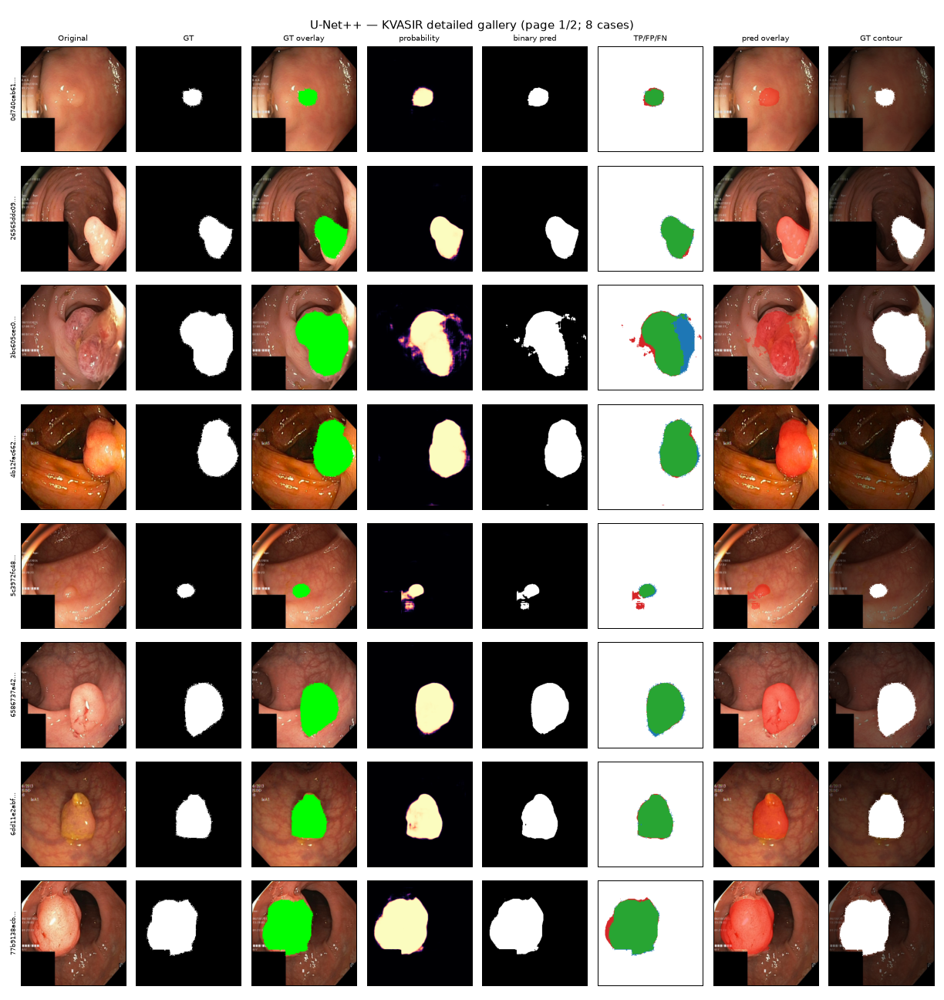

*Figure — U-Net++ KUB detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_unetpp_KUB_p1.png`

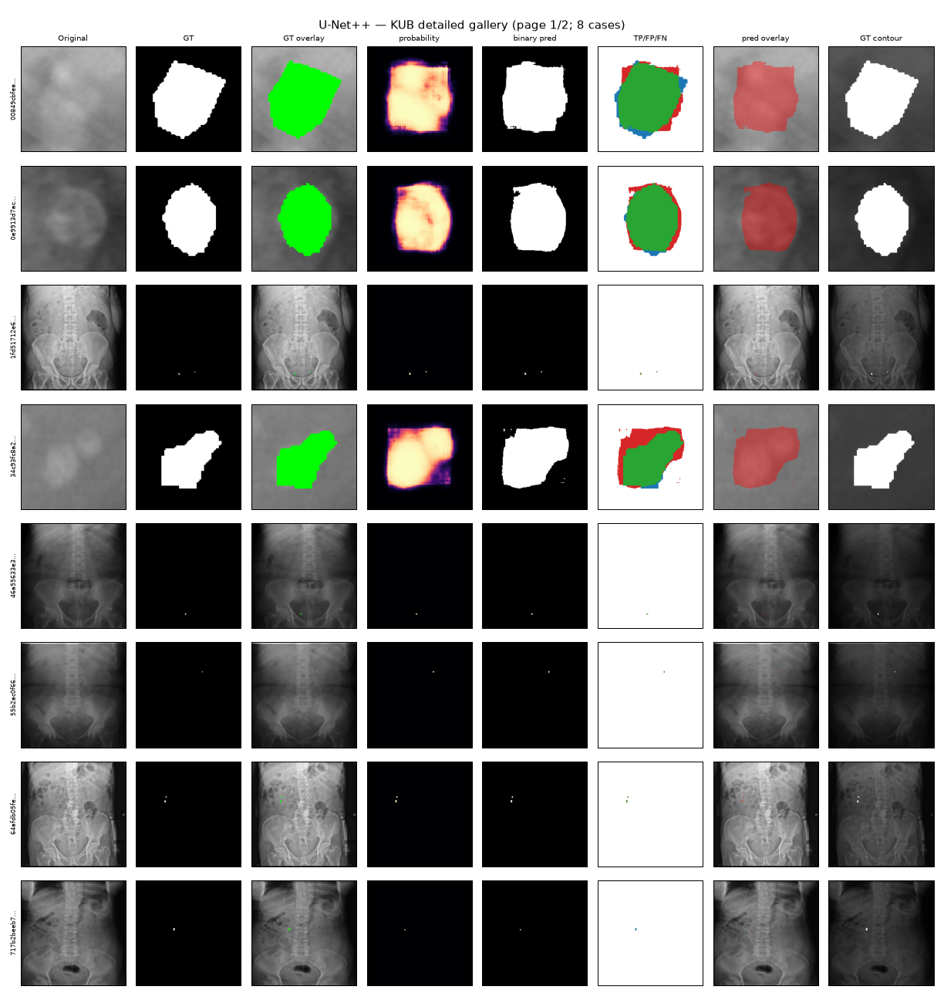

*Figure — DeepLabV3+ ISIC detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_deeplabv3plus_ISIC_p1.png`

*Figure — DeepLabV3+ BUSI detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_deeplabv3plus_BUSI_p1.png`

*Figure — DeepLabV3+ KVASIR detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_deeplabv3plus_KVASIR_p1.png`

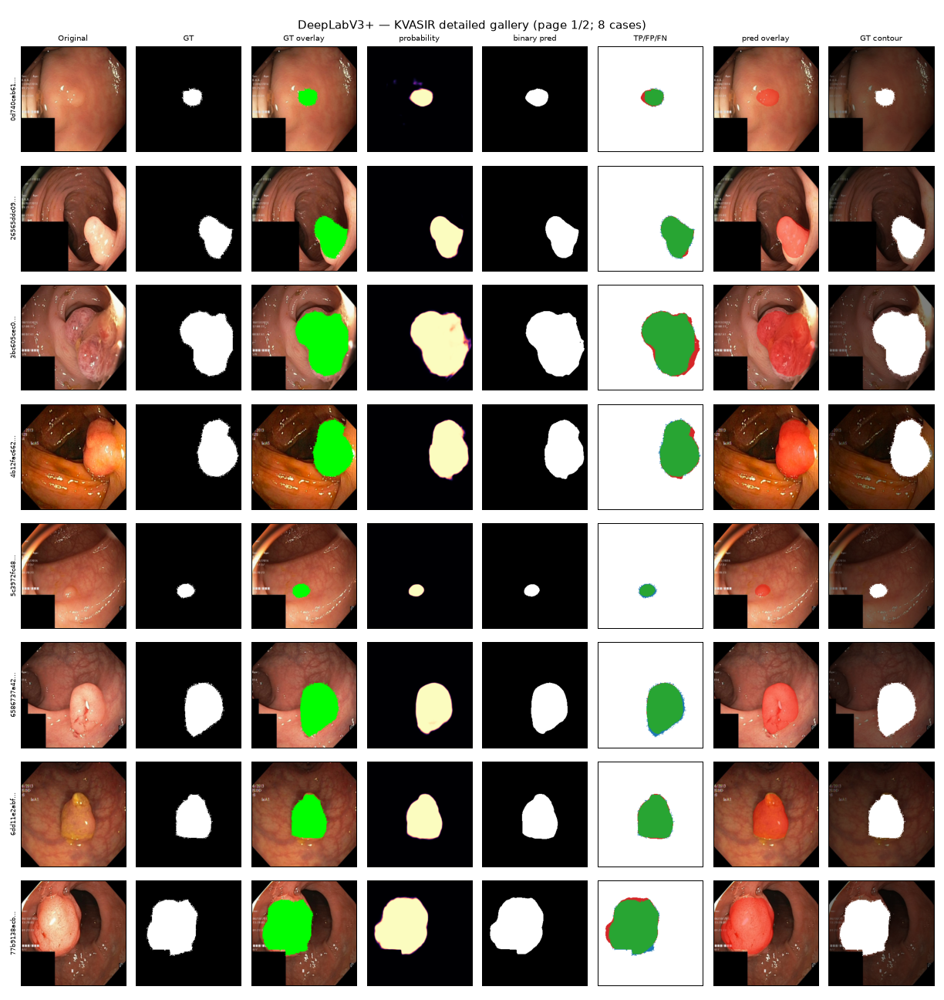

*Figure — DeepLabV3+ KUB detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_deeplabv3plus_KUB_p1.png`

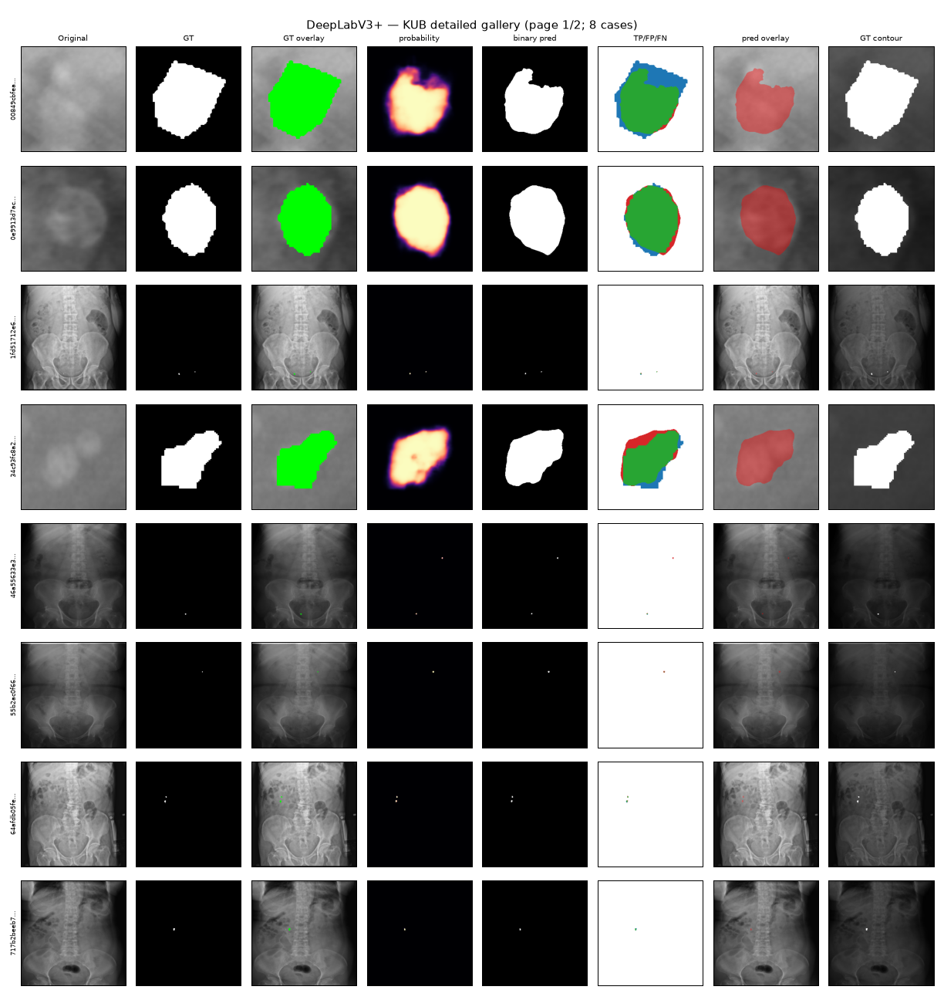

*Figure — Transformer/MiT-style U-Net ISIC detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_transformer_mit_unet_ISIC_p1.png`

*Figure — Transformer/MiT-style U-Net BUSI detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_transformer_mit_unet_BUSI_p1.png`

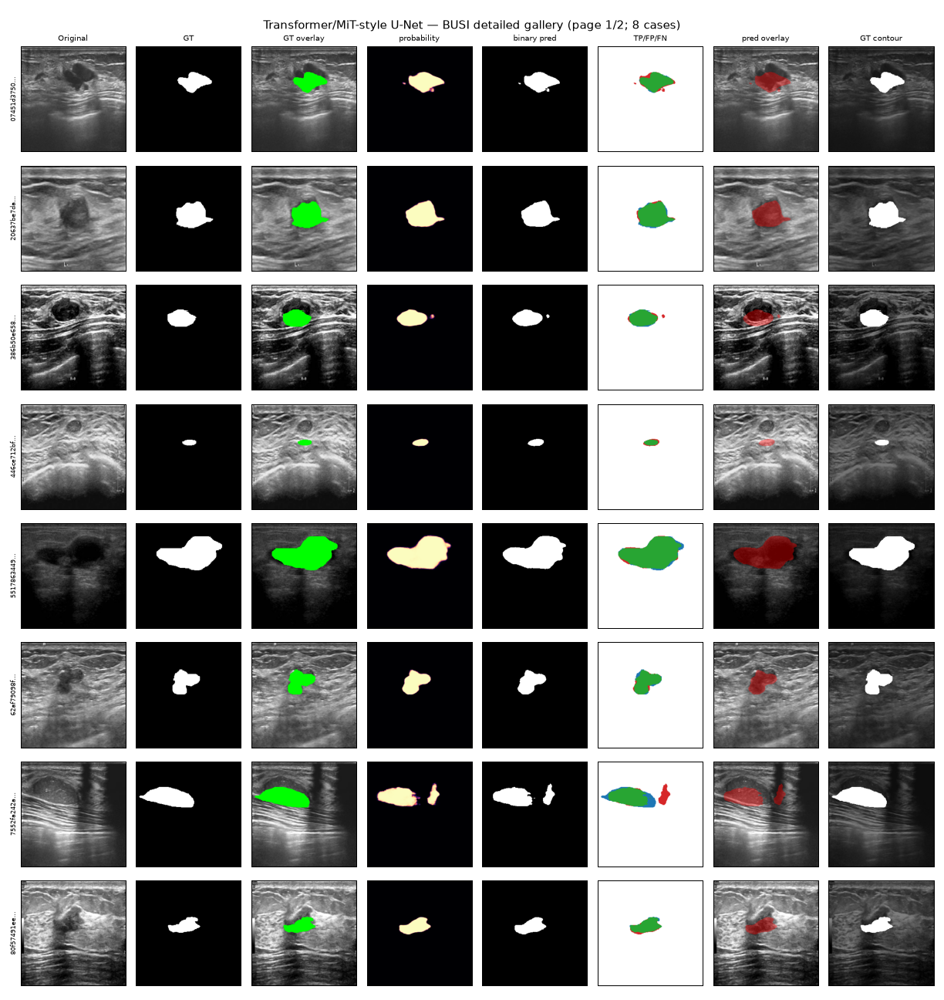

*Figure — Transformer/MiT-style U-Net KVASIR detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_transformer_mit_unet_KVASIR_p1.png`

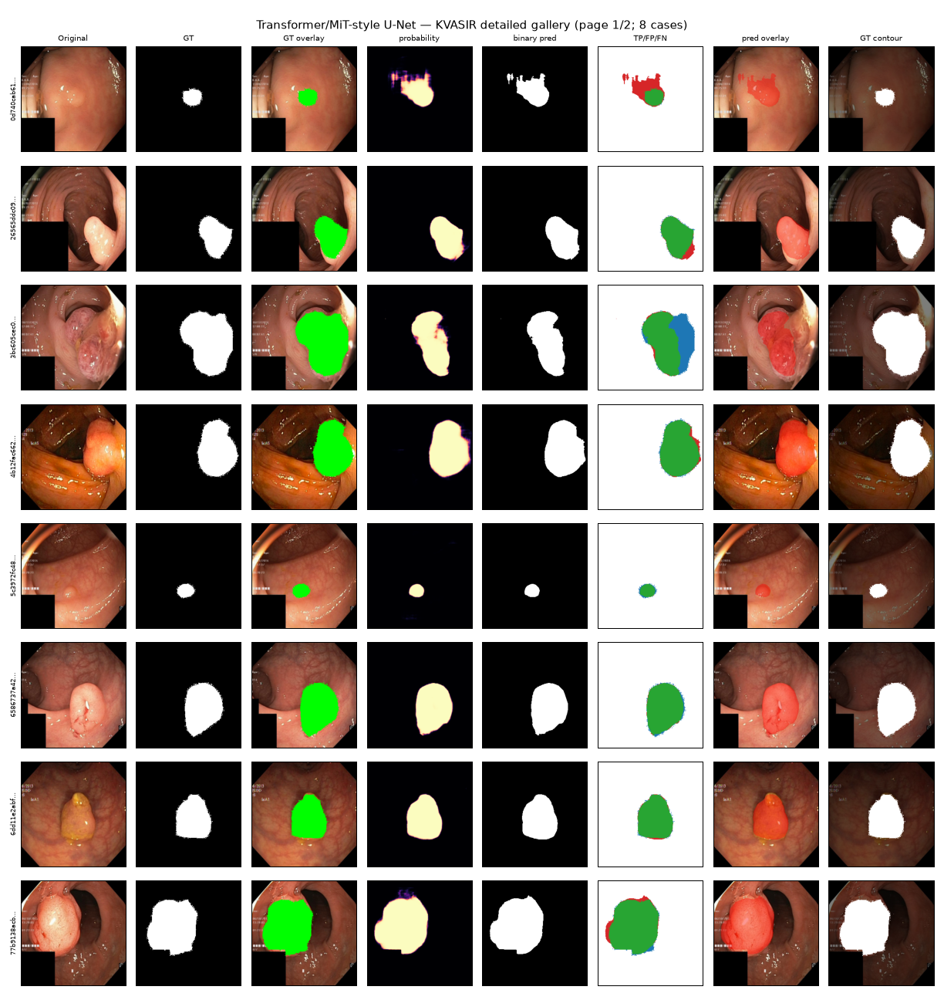

*Figure — Transformer/MiT-style U-Net KUB detailed gallery p1*  
`reports/figures/phase20b_five_model_baselines/galleries/detailed_transformer_mit_unet_KUB_p1.png`

In [36]:
det = F.figure_inventory()
det = det[det["category"] == "gallery"]
det = det[det["figure_id"].str.startswith("gallery_detailed_")]
print("detailed gallery pages on disk:", len(det))
display(sty(det[["figure_id", "saved_path", "embedded_in_notebook"]].reset_index(drop=True),
            "p20b_det"))
show_figs([f"gallery_detailed_{m}_{d}_1" for m in R.MODEL_ORDER for d in R.DATASET_ORDER],
          width=1500)

## 39 · What all models solve  ·  40 · What all models fail

In [37]:
mat = R.model_sample_matrix("dice")
dmap = R.sample_domain_map()
solved = (mat.min(axis=0) >= 0.90)
failed = (mat.max(axis=0) <= 0.30)
df = pd.DataFrame({"dataset": [dmap[s] for s in mat.columns],
                   "solved_by_all": solved.to_numpy(), "failed_by_all": failed.to_numpy()})
summ = df.groupby("dataset")[["solved_by_all", "failed_by_all"]].sum().reset_index()
summ["n"] = summ["dataset"].map(df.groupby("dataset").size())
display(sty(summ, "p20b_sf"))
display(Markdown(f"**Solved by all five models (Dice ≥ 0.90 in every model): "
                 f"{int(solved.sum())}/{len(mat.columns)} cases.**  \n"
                 f"**Failed by all five models (best model Dice ≤ 0.30): {int(failed.sum())} cases.**"))

,dataset,solved_by_all,failed_by_all,n
0,BUSI,17,1,84
1,ISIC,158,0,357
2,KUB,2,11,280
3,KVASIR,20,3,87


**Solved by all five models (Dice ≥ 0.90 in every model): 197/808 cases.**  
**Failed by all five models (best model Dice ≤ 0.30): 15 cases.**

## 41 · Statistical interpretation

- **Two-tier structure is significant.** Each two-stage architecture (DeepLabV3+,
  Transformer/MiT-style U-Net) beats every U-Net-family variant with a paired CI that
  excludes zero (p ≈ 0.000).
- **The top-two ordering is NOT significant.** DeepLabV3+ vs Transformer/MiT-style U-Net
  gives Δ ≈ +0.005270 with a 95% CI that crosses zero (p ≈ 0.282), and the two models swap
  the top-two ranks in ≈10% of bootstrap replicates. DeepLabV3+ has the highest *observed*
  macro-domain Dice; it is **not** a statistically separated winner.

In [38]:
two_tier = paired[(paired["model_a"].isin(["deeplabv3plus", "transformer_mit_unet"])
                   & paired["model_b"].isin(["unet", "attention_unet", "unetpp"]))
                  | (paired["model_b"].isin(["deeplabv3plus", "transformer_mit_unet"])
                     & paired["model_a"].isin(["unet", "attention_unet", "unetpp"]))]
display(sty(two_tier[["model_a", "model_b", "observed_diff", "diff_ci_low", "diff_ci_high",
                      "p_value_two_sided", "significant_at_0.05"]], "p20b_2tier",
            {"observed_diff": "{:+.6f}", "diff_ci_low": "{:+.6f}",
             "diff_ci_high": "{:+.6f}", "p_value_two_sided": "{:.3f}"}))
assert two_tier["significant_at_0.05"].all()
assert freeze["top_two_ranking_significant"] is False
display(Markdown("Tier separation significant ✓ · top-two ordering not significant ✓"))

,model_a,model_b,observed_diff,diff_ci_low,diff_ci_high,p_value_two_sided,significant_at_0.05
0,deeplabv3plus,unetpp,+0.035643,+0.023153,+0.047986,0.000,True
1,transformer_mit_unet,unetpp,+0.030373,+0.016946,+0.044389,0.000,True
6,attention_unet,transformer_mit_unet,-0.033346,-0.046688,-0.021403,0.000,True
7,unet,transformer_mit_unet,-0.034550,-0.048555,-0.020799,0.000,True
8,attention_unet,deeplabv3plus,-0.038616,-0.051391,-0.026347,0.000,True
9,unet,deeplabv3plus,-0.039820,-0.053127,-0.026640,0.000,True


Tier separation significant ✓ · top-two ordering not significant ✓

## 42 · Limitations

- **VAL-only.** All numbers are on the 808-case VAL split. TEST stays closed (Phase 39).
- **Single seed (42) per model.** No seed-replication, so architecture-level variance is not
  separated from seed variance; the paired bootstrap quantifies *sampling* uncertainty on
  the fixed VAL set, not training-seed uncertainty.
- **Top-two tie.** DeepLabV3+ and Transformer/MiT-style U-Net are statistically
  indistinguishable under this protocol; no definitive winner is claimed.
- **`deeplabv3plus` is random-init** (not ImageNet-pretrained) and `transformer_mit_unet` is
  `LOCAL_RANDOM_INIT` (not official pretrained MiT-B1) — so these are *not* the published
  pretrained variants.
- **KUB ROI vs FULL_FIELD** are different acquisition regimes; ROI cases are reported
  separately and are not directly comparable with FULL_FIELD strata.
- **Boundary metrics** are undefined for empty masks; the frozen sentinel rule excludes
  those cases and reports valid counts.
- **Descriptive additions.** ROC/PR curves, reliability diagrams, rank stability, efficiency
  and Pareto analyses are *descriptive*; they reuse frozen artifacts and change no frozen
  value.

## 43 · Baseline benchmark freeze  ·  44 · Provenance / hashes

In [39]:
display(Markdown(f"**Frozen science artifact:** `reports/audits/phase20_five_model_baseline_benchmark_freeze.json`"))
display(sty(pd.DataFrame(sorted({
    "terminal_state": freeze["terminal_state"],
    "protocol_sha256": freeze["protocol_sha256"],
    "protocol_matches_expected": freeze["protocol_sha256"] == freeze["protocol_sha256_expected"],
    "per_model_replay_all_pass": freeze["per_model_replay_all_pass"],
    "gallery_ids_match_phase20a": freeze["gallery_ids_match_phase20a_frozen_set"],
    "test_reads_total_zero": all(v == 0 for v in freeze["test_reads_total"].values()),
    "phase21_started": freeze["phase21_started"],
}.items()), columns=["freeze item", "value"]), "p20b_fz"))
display(sty(prov, "p20b_prov2"))
display(Markdown("**Additive reviewer-package companion:** "
                 "`reports/audits/phase20b_reviewer_package_freeze.json` (documentation/provenance only; "
                 "the historical freeze is not rewritten)."))
assert freeze["protocol_sha256"] == freeze["protocol_sha256_expected"]
assert freeze["per_model_replay_all_pass"] is True
assert all(v == 0 for v in freeze["test_reads_total"].values())

**Frozen science artifact:** `reports/audits/phase20_five_model_baseline_benchmark_freeze.json`

,freeze item,value
0,gallery_ids_match_phase20a,True
1,per_model_replay_all_pass,True
2,phase21_started,False
3,protocol_matches_expected,True
4,protocol_sha256,b74f1f9f429adbce374f0306180943b9f373f872e1e69e115b7d17e81414283c
5,terminal_state,PHASE20_FIVE_MODEL_BASELINE_BENCHMARK_COMPLETE__PHASE21_ELIGIBLE_NOT_STARTED
6,test_reads_total_zero,True


,model_key,model,phase,model_class,model_source_file,model_source_sha256,architecture_binding_sha256,pre_execution_check_sha256,history_sha256,best_checkpoint_sha256,protocol_sha256,protocol_binding,protocol_sha_matches_repo
0,unet,U-Net,20B,UNet,src/models/unet.py,62edc8fb481eb02c46c2c64f6e7219254a57d7ba935a4c840a5a7965b41bdfc2,edc2b1268218a4fe931ed6e1dd3184fb5b1a555cf55904c480a72c5d2759fbae,972b364068d468daa1839b4777f5bede272e9f694d2db13b87c97d6ec641b968,7dcf6088b5ce51fb1ffcca706aa84dc231aae373c09d369e79fbd52f46e7c683,62fde8f4b0de50803e510c609f4cb943b7d72bd1ab7a5b1ff1534b38a76a5634,b74f1f9f429adbce374f0306180943b9f373f872e1e69e115b7d17e81414283c,closure_field,True
1,attention_unet,Attention U-Net,20B,AttentionUNet,src/models/attention_unet.py,834c02170aafc1093de9edb2afad99f76a200ae1eb5ecae16ad57eb7c2e21690,ebdeb453356f9d683bf14773c54bd9d25287fc37b0701054f7a5ac992a4ec15f,1e484bd7b424b7444b5638635d7b89687b23f23e024d8f39080384aaeb060665,f8448b85a4f4b6b37cbc9ed7e5b1a4ae31e6c933f3eb42dd2dbe19d6f6ce66d7,feb0eb0577841f3a9cfc1efb3a46dd4cdd5f749e3f3b08b85d80e472f7dd2b35,b74f1f9f429adbce374f0306180943b9f373f872e1e69e115b7d17e81414283c,closure_field,True
2,unetpp,U-Net++,20A,nan,nan,nan,nan,nan,ed9abeee112a45954e458209ecff9c480a9b68ced7d76edd8dc31eaf9d2333cd,d647ac52bf39704549ce2eea4fee8e17dfcb5ce9ace5e0b24ffb1f7db86a059f,b74f1f9f429adbce374f0306180943b9f373f872e1e69e115b7d17e81414283c,frozen_protocol_code_shas,True
3,deeplabv3plus,DeepLabV3+,20B,DeepLabV3Plus,src/models/deeplabv3plus.py,751a1ead9aca93c7372750924f7483b3de3ad3f5f40edd3a648e9e39bdd77406,1fcf38a67791e81218f94086fd9e8c636428d24ed8c6a3461b355c01d827d561,11d62c7f54fea55b44db6b5d433dc2844dc58d35de8f43cbb2216d5cd1e83260,5ddc59442e1163d6762772c04645230bd9770457e6f76fa5dbd6e2427826631c,0bd9548f141174f05f842d2015dceda6db4587921d241590b63e9ae0099d3ff8,b74f1f9f429adbce374f0306180943b9f373f872e1e69e115b7d17e81414283c,closure_field,True
4,transformer_mit_unet,Transformer/MiT-style U-Net,20B,TransformerMiTUNet,src/models/transformer_mit_unet.py,46c445adf0aaa190b022a7782af3dd0646f29b1978db0cf297cc38eed3d47641,8297ab13a61005848711b5a7021567b3bf6b4d5b2ab50b4a4b9acf749d35e01f,d8dc15e2ff4aec895be4d8d6190f79fd7ca5cc378fe76db6ee29ad041feb52a0,2fcfa684b5d7a242a473ede510199d0b4f622d14f605e96cb5d6a41e93298075,e2c1fca196348d57e4bc8d8ae0f17d82ff0252142e8d94631f7e0ba7d69149e2,b74f1f9f429adbce374f0306180943b9f373f872e1e69e115b7d17e81414283c,closure_field,True


**Additive reviewer-package companion:** `reports/audits/phase20b_reviewer_package_freeze.json` (documentation/provenance only; the historical freeze is not rewritten).

## 45 · Evaluation-matrix visualization coverage  ·  46 · Notebook determinism

Every important evaluation matrix has a visual counterpart. The coverage table below is the
machine-checkable proof, and the notebook itself is byte-deterministic across rebuilds.

In [40]:
cov = F.matrix_coverage()
display(sty(cov[["matrix_name", "source_artifact", "visualization_type", "status"]], "p20b_covm"))
frac = (cov["status"] == "VISUALIZED").mean()
print("evaluation matrices:", len(cov), "| visualized:", int((cov['status'] == 'VISUALIZED').sum()),
      "| coverage:", round(float(frac), 4))
assert frac == 1.0
inv = F.figure_inventory()
print("figures total:", len(inv), "| embedded:", int(inv['embedded_in_notebook'].sum()))
display(sty(inv.groupby("category").size().reset_index(name="figures"), "p20b_invg"))

,matrix_name,source_artifact,visualization_type,status
0,macro_domain_dice_ci,phase20b_five_model_comparison_final.csv,bar + 95% CI,VISUALIZED
1,macro_domain_iou,phase20b_five_model_comparison_final.csv,bar,VISUALIZED
2,per_domain_dice,phase20b__domain_performance.csv,grouped bars,VISUALIZED
3,model_x_domain_dice,phase20b__domain_performance.csv,heatmap,VISUALIZED
4,model_x_domain_iou,phase20b__domain_performance.csv,heatmap,VISUALIZED
5,model_x_domain_precision,phase20b__domain_performance.csv,heatmap,VISUALIZED
6,model_x_domain_recall,phase20b__domain_performance.csv,heatmap,VISUALIZED
7,model_x_domain_specificity,phase20b__domain_performance.csv,heatmap,VISUALIZED
8,model_x_domain_balanced_accuracy,phase20b__domain_performance.csv,heatmap,VISUALIZED
9,model_x_domain_mcc,phase20b__domain_performance.csv,heatmap,VISUALIZED


evaluation matrices: 51 | visualized: 51 | coverage: 1.0
figures total: 153 | embedded: 114


,category,figures
0,agreement,3
1,bootstrap,6
2,boundary,4
3,calibration,4
4,confusion,8
5,distribution,6
6,efficiency,9
7,failure,11
8,gallery,56
9,kub_size,5


## 47 · Phase-21 entry status

Phase 21 (Global MedFiLM) is **ELIGIBLE but NOT STARTED**. All entry criteria are met and
the Phase-20 five-model baseline is frozen, but starting Phase 21 requires **fresh
supervisor authorization**. Phase 21 must be compared on the **same 64** gallery cases.

In [41]:
p21 = json.loads((ROOT / "reports/audits/phase20_phase21_entry_criteria.json").read_text(encoding="utf-8"))
crit = pd.DataFrame(p21["criteria"])
display(sty(crit, "p20b_p21"))
met = int(crit["met"].sum()) if "met" in crit.columns else sum(1 for c in p21["criteria"] if c["met"])
print(f"Phase-21 entry criteria met: {met}/{len(p21['criteria'])} | may_start: {p21.get('phase21_may_start')}")
assert p21.get("phase21_may_start") is False
assert freeze["phase21_started"] is False

,id,criterion,met,observed
0,P21-1,Phase-20 training naturally terminated,True,EARLY_STOPPING_PATIENCE
1,P21-2,checkpoint-selection replay PASS,True,PHASE20_CHECKPOINT_SELECTION_REPLAY_PASS
2,P21-3,all four domains evaluated,True,"['BUSI', 'ISIC', 'KUB', 'KVASIR']"
3,P21-4,macro-domain score available,True,0.792010
4,P21-5,per-domain scores available for every domain,True,4/4
5,P21-6,prediction artifacts persisted,True,808
6,P21-7,complete notebook executed,True,notebooks\phasewise\phase_20_multidomain_baselines\phase20_shared_global_unetpp_baseline.ipynb
7,P21-8,64 deterministic cases available,True,64
8,P21-9,TEST reads = 0,True,"{'test_image_reads': 0, 'test_mask_reads': 0, 'test_inference': 0, 'test_visualization': 0}"
9,P21-10,architecture/input/training artifacts SHA-bound,True,15


Phase-21 entry criteria met: 12/12 | may_start: False


## 48 · Final assertions

In [42]:
checks = {
  "five models present": len(head) == 5,
  "terminal state correct": freeze["terminal_state"] == "PHASE20_FIVE_MODEL_BASELINE_BENCHMARK_COMPLETE__PHASE21_ELIGIBLE_NOT_STARTED",
  "protocol SHA matches": freeze["protocol_sha256"] == freeze["protocol_sha256_expected"],
  "all replays PASS": freeze["per_model_replay_all_pass"] is True,
  "every model 808 VAL": (ve["samples_evaluated"] == 808).all(),
  "exactly 1 canonical pass/model": (ve["canonical_val_inference_runs"] == 1).all(),
  "TEST reads total = 0": all(v == 0 for v in freeze["test_reads_total"].values()),
  "no per-model recipe change": freeze["no_per_model_recipe_or_threshold_change"] is True,
  "threshold unchanged (0.5)": freeze["threshold"] == 0.5,
  "top-two NOT significant": freeze["top_two_ranking_significant"] is False,
  "gallery = 64 frozen IDs": len(gal) == 64 and freeze["gallery_ids_match_phase20a_frozen_set"],
  "matrix coverage = 100%": (cov["status"] == "VISUALIZED").all(),
  "figures embedded": int(inv["embedded_in_notebook"].sum()) > 0,
  "phase21 not started": freeze["phase21_started"] is False,
}
res = pd.DataFrame(sorted(checks.items()), columns=["assertion", "passed"])
display(sty(res, "p20b_assert"))
assert all(checks.values()), [k for k, v in checks.items() if not v]
print("All Phase-20B reviewer-package assertions passed.")
print("SCIENTIFIC TERMINAL STATE:", freeze["terminal_state"])
print("REVIEWER-PACKAGE STATE   : PHASE20B_REVIEWER_PACKAGE_COMPLETE__FULL_VISUAL_EVIDENCE__PHASE21_ELIGIBLE_NOT_STARTED")

,assertion,passed
0,TEST reads total = 0,True
1,all replays PASS,True
2,every model 808 VAL,True
3,exactly 1 canonical pass/model,True
4,figures embedded,True
5,five models present,True
6,gallery = 64 frozen IDs,True
7,matrix coverage = 100%,True
8,no per-model recipe change,True
9,phase21 not started,True


All Phase-20B reviewer-package assertions passed.
SCIENTIFIC TERMINAL STATE: PHASE20_FIVE_MODEL_BASELINE_BENCHMARK_COMPLETE__PHASE21_ELIGIBLE_NOT_STARTED
REVIEWER-PACKAGE STATE   : PHASE20B_REVIEWER_PACKAGE_COMPLETE__FULL_VISUAL_EVIDENCE__PHASE21_ELIGIBLE_NOT_STARTED
